In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, mean_squared_error, confusion_matrix
import wandb
from IPython.display import display, clear_output

### **Multi-Task CNN for Fashion-MNIST Classification and Regression**

- 1. **Classifies** Fashion-MNIST images into 10 clothing categories
- 2. **Regresses** the "ink" value (normalized pixel   intensity) of each image
 The model uses a shared CNN backbone with two separate heads and is trained with a joint loss function.


In [2]:
# Set style for better plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)


def add_watermark(fig, text="Rithvika", fontsize=14, alpha=0.3):
    """
    Adds a semi-transparent watermark text to the given matplotlib figure.
    """
    fig.text(
        0.5, 0.5, text,
        fontsize=fontsize,
        color='gray',
        ha='center', va='center',
        alpha=alpha,
        rotation=30,
        fontweight='bold'
    )



### 1. Data Loading and Preprocessing:

This section handles downloading Fashion-MNIST, creating custom datasets, and preparing data loaders with appropriate augmentations

In [ ]:

# ============================================================================
# 1. DATA LOADING AND PREPROCESSING
# ============================================================================


def load_fashion_data(data_dir='./data'):
    """
    Load Fashion-MNIST dataset and split into train/val/test
    Returns: train_dataset, val_dataset, test_dataset (raw, before custom dataset)
    """
    # Download Fashion-MNIST
    train_dataset_full = torchvision.datasets.FashionMNIST(
        root=data_dir,
        train=True,
        download=True,
        transform=None  # We'll apply transforms in custom dataset
    )

    test_dataset = torchvision.datasets.FashionMNIST(
        root=data_dir,
        train=False,
        download=True,
        transform=None
    )

    # Split train into train and validation (90/10)
    train_size = int(0.9 * len(train_dataset_full))
    val_size = len(train_dataset_full) - train_size

    train_dataset_raw, val_dataset_raw = random_split(
        train_dataset_full,
        [train_size, val_size],
        generator=torch.Generator().manual_seed(42)
    )

    return train_dataset_raw, val_dataset_raw, test_dataset



def compute_mean_std(base_dataset):
    """
    Compute mean and std over [0,1] pixel values for Fashion-MNIST.
    Works for torchvision datasets and Subset splits.
    """
    if hasattr(base_dataset, 'dataset') and hasattr(base_dataset, 'indices'):
        indices = base_dataset.indices
        get_item = lambda i: base_dataset.dataset[i]
    else:
        indices = range(len(base_dataset))
        get_item = lambda i: base_dataset[i]

    total_sum = 0.0
    total_sq_sum = 0.0
    total_count = 0

    for idx in indices:
        img, _ = get_item(idx)
        arr = np.array(img, dtype=np.float32) / 255.0  # HxW in [0,1]
        total_sum += arr.sum()
        total_sq_sum += (arr ** 2).sum()
        total_count += arr.size

    mean = total_sum / total_count
    std = np.sqrt(total_sq_sum / total_count - mean ** 2)
    return float(mean), float(std)



class FashionMNISTDataset(Dataset):
    """
    Custom Dataset that returns (image, class_label, ink_target)
    """
    def __init__(self, base_dataset, transform=None, is_train=False,mean=None,std=None):
        self.base_dataset = base_dataset
        self.transform = transform
        self.is_train = is_train

         # Calculate mean and std for Fashion-MNIST (grayscale) from actual data if not provided
        if mean is None or std is None:
            m, s = compute_mean_std(base_dataset)
            self.mean = m
            self.std = s
        else:
            self.mean = float(mean)
            self.std = float(std)

        # # Calculate mean and std for Fashion-MNIST (grayscale)
        # self.mean = 0.2860
        # self.std = 0.3530

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        if hasattr(self.base_dataset, 'dataset'):
            # For Subset objects
            img, label = self.base_dataset.dataset[self.base_dataset.indices[idx]]
        else:
            img, label = self.base_dataset[idx]

        # Convert PIL to tensor
        img_array = np.array(img, dtype=np.float32) / 255.0

        # Calculate ink target (normalized pixel intensity) - ensure float32
        ink_target = np.float32(img_array.mean())

        # Convert to tensor
        img_tensor = torch.FloatTensor(img_array).unsqueeze(0)  # Add channel dimension

        # Apply augmentations
        if self.transform:
            img_tensor = self.transform(img_tensor)

        # Normalize
        img_tensor = (img_tensor - self.mean) / self.std

        return img_tensor, label, torch.tensor(ink_target, dtype=torch.float32)


def get_data_loaders(batch_size=64):
    """
    Create data loaders with appropriate transforms
    """
    # Load raw data
    train_raw, val_raw, test_raw = load_fashion_data()

    # Compute normalization stats from training data
    train_mean, train_std = compute_mean_std(train_raw)

    # Define augmentations for training only
    train_transform = transforms.Compose([
        transforms.RandomCrop(28, padding=2),
        transforms.RandomRotation(10),
    ])

    # Create custom datasets with computed mean/std
    train_dataset = FashionMNISTDataset(train_raw, transform=train_transform, is_train=True,
                                        mean=train_mean, std=train_std)
    val_dataset = FashionMNISTDataset(val_raw, transform=None, is_train=False,
                                      mean=train_mean, std=train_std)
    test_dataset = FashionMNISTDataset(test_raw, transform=None, is_train=False,
                                       mean=train_mean, std=train_std)

    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

    return train_loader, val_loader, test_loader



### 2. Multi-Task CNN Architecture
This section defines the neural network model with a shared convolutional backbone and separate heads for classification and regression tasks.

In [ ]:
# ============================================================================
# 2. MODEL IMPLEMENTATION: MULTI-TASK CNN
# ============================================================================


class MultiTaskCNN(nn.Module):
    """
    Multi-Task CNN with shared backbone and separate heads for classification and regression
    """
    def __init__(self, num_classes=10, dropout_rate=0.5, channels=None):
        super(MultiTaskCNN, self).__init__()

        if channels is None:
            channels = [32, 64, 128]  # default filters per conv block

        self.channels = channels

        # Shared convolutional backbone (configurable number of blocks/filters)
        conv_blocks = []
        in_ch = 1
        for out_ch in channels:
            conv_blocks.append(nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(),
                nn.MaxPool2d(2, 2),
                nn.Dropout2d(dropout_rate)
            ))
            in_ch = out_ch
        self.conv_blocks = nn.ModuleList(conv_blocks)

        # Compute flattened size dynamically: 28x28 -> (28 / 2^n) x (28 / 2^n)
        final_hw = 28 // (2 ** len(channels))
        self.flatten_size = channels[-1] * final_hw * final_hw

        # Classification head
        self.classification_head = nn.Sequential(
            nn.Linear(self.flatten_size, 256),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(256, num_classes)
        )

        # Regression head
        self.regression_head = nn.Sequential(
            nn.Linear(self.flatten_size, 128),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(128, 1)
        )

        # Store intermediate features for visualization
        self.feature_maps = {}

    def forward(self, x, return_features=False):
        h = x
        if return_features:
            self.feature_maps = {}

        for i, block in enumerate(self.conv_blocks):
            h = block(h)
            if return_features:
                self.feature_maps[f'conv{i+1}'] = h.detach()

        # Flatten
        x_flat = h.view(h.size(0), -1)

        # Task-specific heads
        class_logits = self.classification_head(x_flat)
        regression_output = self.regression_head(x_flat)

        return class_logits, regression_output


def compute_joint_loss(class_logits, class_labels, reg_output, reg_targets, lambda1=1.0, lambda2=1.0):
    """
    Compute joint loss: L = lambda1 * L_CE + lambda2 * L_MSE
    """
    ce_loss = nn.CrossEntropyLoss()(class_logits, class_labels)

    # Ensure both tensors are float32
    reg_output_flat = reg_output.squeeze().float()
    reg_targets_flat = reg_targets.float()

    mse_loss = nn.MSELoss()(reg_output_flat, reg_targets_flat)

    total_loss = lambda1 * ce_loss + lambda2 * mse_loss

    return total_loss, ce_loss.item(), mse_loss.item()


- Key Architecture Features:

Shared Backbone: Convolutional layers extract features useful for both tasks
Separate Heads: Task-specific layers prevent interference between objectives
Joint Loss: Weighted combination allows tuning the classification/regression trade-off

### 3. Training and Evaluation Functions
This section contains the core training loop, evaluation metrics, and model training pipeline with wandb logging.

In [ ]:

# ============================================================================
# 3. TRAINING AND EVALUATION
# ============================================================================

def train_epoch(model, train_loader, optimizer, device, lambda1, lambda2):
    """
    Train for one epoch
    """
    model.train()
    total_loss = 0
    total_ce_loss = 0
    total_mse_loss = 0

    for images, labels, ink_targets in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        ink_targets = ink_targets.to(device)

        optimizer.zero_grad()

        class_logits, reg_output = model(images)
        loss, ce_loss, mse_loss = compute_joint_loss(
            class_logits, labels, reg_output, ink_targets, lambda1, lambda2
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_ce_loss += ce_loss
        total_mse_loss += mse_loss

    num_batches = len(train_loader)
    return total_loss / num_batches, total_ce_loss / num_batches, total_mse_loss / num_batches


def evaluate(model, data_loader, device, lambda1, lambda2):
    """
    Evaluate model on validation or test set
    """
    model.eval()
    total_loss = 0
    total_ce_loss = 0
    total_mse_loss = 0

    all_preds = []
    all_labels = []
    all_reg_preds = []
    all_reg_targets = []

    with torch.no_grad():
        for images, labels, ink_targets in data_loader:
            images = images.to(device)
            labels = labels.to(device)
            ink_targets = ink_targets.to(device)

            class_logits, reg_output = model(images)
            loss, ce_loss, mse_loss = compute_joint_loss(
                class_logits, labels, reg_output, ink_targets, lambda1, lambda2
            )

            total_loss += loss.item()
            total_ce_loss += ce_loss
            total_mse_loss += mse_loss

            preds = torch.argmax(class_logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_reg_preds.extend(reg_output.squeeze().cpu().numpy())
            all_reg_targets.extend(ink_targets.cpu().numpy())

    num_batches = len(data_loader)
    avg_loss = total_loss / num_batches
    avg_ce_loss = total_ce_loss / num_batches
    avg_mse_loss = total_mse_loss / num_batches

    # Calculate metrics
    accuracy = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted')
    mae = mean_absolute_error(all_reg_targets, all_reg_preds)
    rmse = np.sqrt(mean_squared_error(all_reg_targets, all_reg_preds))

    return {
        'loss': avg_loss,
        'ce_loss': avg_ce_loss,
        'mse_loss': avg_mse_loss,
        'accuracy': accuracy,
        'f1_score': f1,
        'mae': mae,
        'rmse': rmse,
        'all_preds': all_preds,
        'all_labels': all_labels
    }


def train_model(model, train_loader, val_loader, config, device):
    """
    Full training loop with wandb logging and history tracking
    """
    optimizer_name = config['optimizer']
    if optimizer_name == 'Adam':
        optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])
    elif optimizer_name == 'AdamW':
        optimizer = optim.AdamW(model.parameters(), lr=config['learning_rate'])
    else:  # SGD
        optimizer = optim.SGD(model.parameters(), lr=config['learning_rate'], momentum=0.9)

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

    best_val_acc = 0
    best_val_rmse = float('inf')

    # Track history for plotting
    history = {
        'train_loss': [], 'train_ce': [], 'train_mse': [],
        'val_loss': [], 'val_ce': [], 'val_mse': [],
        'val_accuracy': [], 'val_f1': [], 'val_mae': [], 'val_rmse': []
    }

    for epoch in range(config['epochs']):
        # Train
        train_loss, train_ce, train_mse = train_epoch(
            model, train_loader, optimizer, device, config['lambda1'], config['lambda2']
        )

        # Validate
        val_metrics = evaluate(model, val_loader, device, config['lambda1'], config['lambda2'])

        # Learning rate scheduling
        scheduler.step(val_metrics['loss'])

        # Store history
        history['train_loss'].append(train_loss)
        history['train_ce'].append(train_ce)
        history['train_mse'].append(train_mse)
        history['val_loss'].append(val_metrics['loss'])
        history['val_ce'].append(val_metrics['ce_loss'])
        history['val_mse'].append(val_metrics['mse_loss'])
        history['val_accuracy'].append(val_metrics['accuracy'])
        history['val_f1'].append(val_metrics['f1_score'])
        history['val_mae'].append(val_metrics['mae'])
        history['val_rmse'].append(val_metrics['rmse'])

        # Log to wandb
        wandb.log({
            'epoch': epoch,
            'train/loss': train_loss,
            'train/ce_loss': train_ce,
            'train/mse_loss': train_mse,
            'val/loss': val_metrics['loss'],
            'val/ce_loss': val_metrics['ce_loss'],
            'val/mse_loss': val_metrics['mse_loss'],
            'val/accuracy': val_metrics['accuracy'],
            'val/f1_score': val_metrics['f1_score'],
            'val/mae': val_metrics['mae'],
            'val/rmse': val_metrics['rmse'],
            'learning_rate': optimizer.param_groups[0]['lr']
        })

        if val_metrics['accuracy'] > best_val_acc:
            best_val_acc = val_metrics['accuracy']
            model_name = f'best_acc_{wandb.run.name}_{val_metrics["accuracy"]:.4f}.pth'
            torch.save(model.state_dict(), model_name)

        if val_metrics['rmse'] < best_val_rmse:
            best_val_rmse = val_metrics['rmse']
            model_name = f'best_rmse_{wandb.run.name}_{val_metrics["rmse"]:.4f}.pth'
            torch.save(model.state_dict(), model_name)


        print(f"Epoch {epoch+1}/{config['epochs']} - "
                f"Train Loss: {train_loss:.4f}, Val Loss: {val_metrics['loss']:.4f}, "
                f"Val Acc: {val_metrics['accuracy']:.4f}, Val RMSE: {val_metrics['rmse']:.4f}")


    return model, history



- Multi-optimizer support: Adam, AdamW, SGD with different characteristics

### 4. Visualization Functions
This section creates comprehensive visualizations to understand model performance, feature learning, and prediction quality.

In [ ]:


# ============================================================================
# 4. VISUALIZATION FUNCTIONS
# ============================================================================

def plot_training_curves(history, config_name):
    """
    Plot training and validation curves
    """
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle(f'Training Curves - {config_name}', fontsize=16, fontweight='bold')

    epochs = range(1, len(history['train_loss']) + 1)

    # Total Loss
    axes[0, 0].plot(epochs, history['train_loss'], 'b-', label='Train', linewidth=2)
    axes[0, 0].plot(epochs, history['val_loss'], 'r-', label='Validation', linewidth=2)
    axes[0, 0].set_title('Total Loss', fontsize=12, fontweight='bold')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

    # Classification Loss (CE)
    axes[0, 1].plot(epochs, history['train_ce'], 'b-', label='Train', linewidth=2)
    axes[0, 1].plot(epochs, history['val_ce'], 'r-', label='Validation', linewidth=2)
    axes[0, 1].set_title('Classification Loss (CE)', fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('CE Loss')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)

    # Regression Loss (MSE)
    axes[0, 2].plot(epochs, history['train_mse'], 'b-', label='Train', linewidth=2)
    axes[0, 2].plot(epochs, history['val_mse'], 'r-', label='Validation', linewidth=2)
    axes[0, 2].set_title('Regression Loss (MSE)', fontsize=12, fontweight='bold')
    axes[0, 2].set_xlabel('Epoch')
    axes[0, 2].set_ylabel('MSE Loss')
    axes[0, 2].legend()
    axes[0, 2].grid(True, alpha=0.3)

    # Accuracy
    axes[1, 0].plot(epochs, history['val_accuracy'], 'g-', linewidth=2)
    axes[1, 0].set_title('Validation Accuracy', fontsize=12, fontweight='bold')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Accuracy')
    axes[1, 0].grid(True, alpha=0.3)

    # F1 Score
    axes[1, 1].plot(epochs, history['val_f1'], 'm-', linewidth=2)
    axes[1, 1].set_title('Validation F1 Score', fontsize=12, fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('F1 Score')
    axes[1, 1].grid(True, alpha=0.3)

    # RMSE
    axes[1, 2].plot(epochs, history['val_rmse'], 'c-', linewidth=2)
    axes[1, 2].set_title('Validation RMSE', fontsize=12, fontweight='bold')
    axes[1, 2].set_xlabel('Epoch')
    axes[1, 2].set_ylabel('RMSE')
    axes[1, 2].grid(True, alpha=0.3)

    add_watermark(fig)
    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(all_labels, all_preds, config_name):
    """
    Plot confusion matrix
    """
    class_names = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
                   'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

    cm = confusion_matrix(all_labels, all_preds)

    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {config_name}', fontsize=14, fontweight='bold')
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)

    add_watermark(plt.gcf())
    plt.tight_layout()
    plt.show()


def visualize_feature_maps(model, test_loader, device, num_images=3):
    """
    Visualize intermediate feature maps for sample images (supports variable conv blocks)
    """
    model.eval()

    # Get sample images
    images, labels, _ = next(iter(test_loader))
    sample_images = images[:num_images].to(device)
    sample_labels = labels[:num_images]

    class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
                   'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

    with torch.no_grad():
        _ = model(sample_images, return_features=True)

    feature_maps = model.feature_maps
    num_blocks = len(feature_maps)

    # Create visualization for each image
    for img_idx in range(num_images):
        rows = num_blocks + 1  # +1 for original image row
        fig, axes = plt.subplots(rows, 8, figsize=(20, 3 * rows))
        if rows == 1:
            axes = np.expand_dims(axes, 0)
        fig.suptitle(
            f'Feature Maps - Image {img_idx+1} (Class: {class_names[sample_labels[img_idx]]})',
            fontsize=16, fontweight='bold'
        )

        # Original image (denormalize for visualization)
        # orig_img = sample_images[img_idx].cpu().squeeze()
        # mean, std = 0.2860, 0.3530
        # orig_img = torch.clamp(orig_img * std + mean, 0, 1)
        orig_img = sample_images[img_idx].cpu().squeeze()
        mean = getattr(test_loader.dataset, 'mean', 0.5)
        std = getattr(test_loader.dataset, 'std', 0.5)
        orig_img = torch.clamp(orig_img * std + mean, 0, 1)

        axes[0, 0].imshow(orig_img, cmap='gray')
        axes[0, 0].set_title('Original Image', fontsize=10, fontweight='bold')
        axes[0, 0].axis('off')
        for i in range(1, 8):
            axes[0, i].axis('off')

        # Visualize each conv block (show first 8 channels)
        for b in range(num_blocks):
            fmap = feature_maps[f'conv{b+1}'][img_idx].cpu()
            for i in range(8):
                axes[b+1, i].axis('off')
                if i < fmap.shape[0]:
                    axes[b+1, i].imshow(fmap[i], cmap='viridis')
                    axes[b+1, i].set_title(f'Conv{b+1}-Ch{i+1}', fontsize=9)

        plt.tight_layout()
        add_watermark(fig)
        wandb.log({f'feature_maps/image_{img_idx+1}': wandb.Image(fig)})
        plt.show()

    print("\n Feature map visualizations completed and logged to wandb'")

def plot_sample_predictions(model, test_loader, device, num_samples=12):
    """
    Plot sample predictions with true labels and regression values
    """
    model.eval()

    images, labels, ink_targets = next(iter(test_loader))
    sample_images = images[:num_samples].to(device)
    sample_labels = labels[:num_samples]
    sample_ink = ink_targets[:num_samples]

    class_names = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
                   'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

    with torch.no_grad():
        class_logits, reg_output = model(sample_images)
        preds = torch.argmax(class_logits, dim=1).cpu()
        reg_preds = reg_output.squeeze().cpu()

    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    fig.suptitle('Sample Predictions: Classification + Regression', fontsize=16, fontweight='bold')

    for idx in range(num_samples):
        ax = axes[idx // 4, idx % 4]

        # # Denormalize image
        # img = sample_images[idx].cpu().squeeze()
        # mean, std = 0.2860, 0.3530
        # img = img * std + mean
        # img = torch.clamp(img, 0, 1)
        img = sample_images[idx].cpu().squeeze()
        mean = getattr(test_loader.dataset, 'mean', 0.5)
        std = getattr(test_loader.dataset, 'std', 0.5)
        img = torch.clamp(img * std + mean, 0, 1)

        ax.imshow(img, cmap='gray')

        true_label = class_names[sample_labels[idx]]
        pred_label = class_names[preds[idx]]
        true_ink = sample_ink[idx].item()
        pred_ink = reg_preds[idx].item()

        color = 'green' if sample_labels[idx] == preds[idx] else 'red'

        ax.set_title(f'True: {true_label}\nPred: {pred_label}\n'
                    f'Ink: {true_ink:.3f} → {pred_ink:.3f}',
                    fontsize=9, color=color, fontweight='bold')
        ax.axis('off')

    add_watermark(fig)

    plt.tight_layout()
    plt.show()


- Visualization Components:

- Training Curves: Shows loss progression and metric improvements over epochs
- Confusion Matrix: Reveals which clothing classes are most often confused
- Feature Maps: Displays what the CNN learns at different layers (edges → textures → shapes)
- Sample Predictions: Shows real predictions with both classification and ink regression results


### 5. Hyperparameter Tuning and Experiments
This section orchestrates individual experiments with different configurations and logs everything to wandb.

In [ ]:

# ============================================================================
# 5. HYPERPARAMETER TUNING AND EXPERIMENTS
# ============================================================================


def run_experiment(config_dict):
    """
    Run a single experiment with given configuration
    """
    channels = config_dict.get('channels', [32, 64, 128])
    ch_str = "-".join(map(str, channels))
    run_name = (
        f"{config_dict['name']}_lr{config_dict['learning_rate']}_bs{config_dict['batch_size']}"
        f"_l1-{config_dict['lambda1']}_l2-{config_dict['lambda2']}_ch-{ch_str}"
    )

    # Initialize wandb with descriptive name and tags
    wandb.init(
        project='fashion-mnist-multitask',
        config=config_dict,
        name=run_name,
        tags=[
            config_dict['optimizer'],
            f"lambda1_{config_dict['lambda1']}",
            f"lambda2_{config_dict['lambda2']}",
            f"lr_{config_dict['learning_rate']}",
            f"channels_{ch_str}",
            config_dict['name'].replace(' ', '_').lower()
        ],
        reinit=True
    )
    config = wandb.config

    # Setup
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    # Load data
    print("Loading data...")
    train_loader, val_loader, test_loader = get_data_loaders(batch_size=config.batch_size)

    # Create model
    print("Creating model...")
    model = MultiTaskCNN(dropout_rate=config.dropout_rate, channels=config_dict.get('channels', [32,64,128])).to(device)
    # Train
    print("Training...")
    model, history = train_model(model, train_loader, val_loader, config, device)

    # Plot training curves
    print("\n" + "="*80)
    print("TRAINING CURVES")
    print("="*80)
    plot_training_curves(history, config.name)

    # Final test evaluation
    print("\n" + "="*80)
    print("EVALUATING ON TEST SET")
    print("="*80)
    test_metrics = evaluate(model, test_loader, device, config.lambda1, config.lambda2)

    # Log test metrics
    wandb.log({
        'test/loss': test_metrics['loss'],
        'test/accuracy': test_metrics['accuracy'],
        'test/f1_score': test_metrics['f1_score'],
        'test/mae': test_metrics['mae'],
        'test/rmse': test_metrics['rmse']
    })

    print(f"\n✓ Test Results:")
    print(f"  • Accuracy:  {test_metrics['accuracy']:.4f}")
    print(f"  • F1 Score:  {test_metrics['f1_score']:.4f}")
    print(f"  • MAE:       {test_metrics['mae']:.4f}")
    print(f"  • RMSE:      {test_metrics['rmse']:.4f}")

    # Plot confusion matrix
    print("\n" + "="*80)
    print("CONFUSION MATRIX")
    print("="*80)
    plot_confusion_matrix(test_metrics['all_labels'], test_metrics['all_preds'], config.name)

    # Visualize sample predictions
    print("\n" + "="*80)
    print("SAMPLE PREDICTIONS")
    print("="*80)
    plot_sample_predictions(model, test_loader, device)

    # Visualize feature maps
    print("\n" + "="*80)
    print("FEATURE MAP VISUALIZATIONS")
    print("="*80)
    visualize_feature_maps(model, test_loader, device)

    wandb.finish()

    return test_metrics, history

- Experiment Pipeline:

- Single experiment runner: Handles one complete train/test cycle
- Wandb integration: Automatic logging of configurations, metrics, and visualizations
- Comprehensive evaluation: Tests on both classification and regression metrics
- Visual outputs: Generates plots for training curves, confusion matrix, feature maps, and predictions

### 6. Cross-Experiment Comparison
These functions analyze results across multiple experiments to understand the impact of different hyperparameters.

In [8]:



# ============================================================================
# 6. COMPARISON PLOTS ACROSS EXPERIMENTS
# ============================================================================

def plot_all_experiments_comparison(all_results):
    """
    Plot comparison of all experiments
    """
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    fig.suptitle('Comparison Across All Experiments', fontsize=18, fontweight='bold')

    exp_names = [r['name'] for r in all_results]
    colors = plt.cm.tab10(np.linspace(0, 1, len(all_results)))

    # Plot 1: Validation Loss over epochs
    ax = axes[0, 0]
    for idx, result in enumerate(all_results):
        epochs = range(1, len(result['history']['val_loss']) + 1)
        ax.plot(epochs, result['history']['val_loss'],
                color=colors[idx], label=result['name'], linewidth=2)
    ax.set_title('Validation Loss', fontsize=12, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

    # Plot 2: Validation Accuracy over epochs
    ax = axes[0, 1]
    for idx, result in enumerate(all_results):
        epochs = range(1, len(result['history']['val_accuracy']) + 1)
        ax.plot(epochs, result['history']['val_accuracy'],
                color=colors[idx], label=result['name'], linewidth=2)
    ax.set_title('Validation Accuracy', fontsize=12, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

    # Plot 3: Validation RMSE over epochs
    ax = axes[0, 2]
    for idx, result in enumerate(all_results):
        epochs = range(1, len(result['history']['val_rmse']) + 1)
        ax.plot(epochs, result['history']['val_rmse'],
                color=colors[idx], label=result['name'], linewidth=2)
    ax.set_title('Validation RMSE', fontsize=12, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('RMSE')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

    # Plot 4: Final Test Accuracy (Bar chart)
    ax = axes[1, 0]
    test_accs = [r['metrics']['accuracy'] for r in all_results]
    bars = ax.bar(range(len(exp_names)), test_accs, color=colors)
    ax.set_title('Final Test Accuracy', fontsize=12, fontweight='bold')
    ax.set_ylabel('Accuracy')
    ax.set_xticks(range(len(exp_names)))
    ax.set_xticklabels(exp_names, rotation=45, ha='right', fontsize=8)
    ax.grid(True, alpha=0.3, axis='y')
    # Add value labels on bars
    for i, (bar, acc) in enumerate(zip(bars, test_accs)):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{acc:.3f}', ha='center', va='bottom', fontsize=8)

    # Plot 5: Final Test RMSE (Bar chart)
    ax = axes[1, 1]
    test_rmses = [r['metrics']['rmse'] for r in all_results]
    bars = ax.bar(range(len(exp_names)), test_rmses, color=colors)
    ax.set_title('Final Test RMSE', fontsize=12, fontweight='bold')
    ax.set_ylabel('RMSE')
    ax.set_xticks(range(len(exp_names)))
    ax.set_xticklabels(exp_names, rotation=45, ha='right', fontsize=8)
    ax.grid(True, alpha=0.3, axis='y')
    # Add value labels on bars
    for i, (bar, rmse) in enumerate(zip(bars, test_rmses)):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                f'{rmse:.4f}', ha='center', va='bottom', fontsize=8)

    # Plot 6: Trade-off plot (Accuracy vs RMSE)
    ax = axes[1, 2]
    for idx, result in enumerate(all_results):
        ax.scatter(result['metrics']['accuracy'], result['metrics']['rmse'],
                  s=200, color=colors[idx], label=result['name'],
                  alpha=0.7, edgecolors='black', linewidth=2)
    ax.set_title('Classification vs Regression Trade-off', fontsize=12, fontweight='bold')
    ax.set_xlabel('Test Accuracy')
    ax.set_ylabel('Test RMSE')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    add_watermark(fig)
    plt.show()


def plot_lambda_analysis(all_results):
    """
    Analyze the effect of lambda1 and lambda2
    """
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle('Lambda Weight Analysis', fontsize=16, fontweight='bold')

    # Extract lambda values and metrics
    lambda1_vals = [r['config']['lambda1'] for r in all_results]
    lambda2_vals = [r['config']['lambda2'] for r in all_results]
    accuracies = [r['metrics']['accuracy'] for r in all_results]
    rmses = [r['metrics']['rmse'] for r in all_results]
    names = [r['name'] for r in all_results]

    # Plot 1: Lambda1 vs Accuracy
    ax = axes[0]
    scatter = ax.scatter(lambda1_vals, accuracies, s=200, c=lambda2_vals,
                        cmap='viridis', alpha=0.7, edgecolors='black', linewidth=2)
    for i, name in enumerate(names):
        ax.annotate(name, (lambda1_vals[i], accuracies[i]),
                   fontsize=8, ha='center', va='bottom')
    ax.set_xlabel('Lambda1 (Classification Weight)', fontsize=12)
    ax.set_ylabel('Test Accuracy', fontsize=12)
    ax.set_title('Effect of Lambda1 on Classification', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    cbar1 = plt.colorbar(scatter, ax=ax)
    cbar1.set_label('Lambda2', fontsize=10)

    # Plot 2: Lambda2 vs RMSE
    ax = axes[1]
    scatter = ax.scatter(lambda2_vals, rmses, s=200, c=lambda1_vals,
                        cmap='plasma', alpha=0.7, edgecolors='black', linewidth=2)
    for i, name in enumerate(names):
        ax.annotate(name, (lambda2_vals[i], rmses[i]),
                   fontsize=8, ha='center', va='bottom')
    ax.set_xlabel('Lambda2 (Regression Weight)', fontsize=12)
    ax.set_ylabel('Test RMSE', fontsize=12)
    ax.set_title('Effect of Lambda2 on Regression', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    cbar2 = plt.colorbar(scatter, ax=ax)
    cbar2.set_label('Lambda1', fontsize=10)

    plt.tight_layout()
    plt.show()


def print_summary_table(all_results):
    """
    Print a summary table of all experiments
    """
    print("\n" + "="*120)
    print("COMPREHENSIVE RESULTS SUMMARY TABLE")
    print("="*120)
    print(f"{'Experiment':<25} {'λ1':<6} {'λ2':<6} {'Accuracy':<10} {'F1-Score':<10} {'MAE':<10} {'RMSE':<10}")
    print("-"*120)

    for result in all_results:
        print(f"{result['name']:<25} "
              f"{result['config']['lambda1']:<6.2f} "
              f"{result['config']['lambda2']:<6.2f} "
              f"{result['metrics']['accuracy']:<10.4f} "
              f"{result['metrics']['f1_score']:<10.4f} "
              f"{result['metrics']['mae']:<10.4f} "
              f"{result['metrics']['rmse']:<10.4f}")

    print("="*120)



- Comparison Analysis:

Performance comparison: Side-by-side plots of all experiments' training curves
Lambda analysis: Shows how λ1 and λ2 weights affect classification vs regression trade-off
Summary table: Clean tabular view of all experiment results
Trade-off visualization: Scatter plot revealing the accuracy-RMSE relationship


### 7. Main Execution Pipeline
The main function that orchestrates all experiments with different hyperparameter combinations.

<>:248: SyntaxWarning: invalid escape sequence '\ '
<>:248: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipython-input-2444087007.py:248: SyntaxWarning: invalid escape sequence '\ '
  print(f"\ Best Regression RMSE: {all_results[best_rmse_idx]['name']}")


                                        MULTI-TASK CNN EXPERIMENTS

Running 8 experiments with different hyperparameter configurations...


EXPERIMENT 1/8: Balanced (1:1)
Configuration:
  • Learning Rate: 0.001
  • Optimizer: Adam
  • Dropout: 0.3
  • Batch Size: 128
  • Lambda1 (Classification): 1.0
  • Lambda2 (Regression): 1.0
  • Channels/Filters: [32, 64, 128] (Blocks: 3)
------------------------------------------------------------------------------------------------------------------------



/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


<IPython.core.display.Javascript object>

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: rithvikakonda (rithvikakonda-iiit-hyderabad) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


Using device: cuda
Loading data...


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 213kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 4.00MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.41MB/s]


Creating model...
Training...
Epoch 1/30 - Train Loss: 0.7616, Val Loss: 0.4793, Val Acc: 0.8235, Val RMSE: 0.0416
Epoch 2/30 - Train Loss: 0.5390, Val Loss: 0.4065, Val Acc: 0.8478, Val RMSE: 0.0406
Epoch 3/30 - Train Loss: 0.4811, Val Loss: 0.3599, Val Acc: 0.8652, Val RMSE: 0.0323
Epoch 4/30 - Train Loss: 0.4503, Val Loss: 0.3727, Val Acc: 0.8593, Val RMSE: 0.0368
Epoch 5/30 - Train Loss: 0.4252, Val Loss: 0.3523, Val Acc: 0.8720, Val RMSE: 0.0411
Epoch 6/30 - Train Loss: 0.4107, Val Loss: 0.3083, Val Acc: 0.8837, Val RMSE: 0.0351
Epoch 7/30 - Train Loss: 0.3957, Val Loss: 0.3042, Val Acc: 0.8833, Val RMSE: 0.0348
Epoch 8/30 - Train Loss: 0.3844, Val Loss: 0.2939, Val Acc: 0.8913, Val RMSE: 0.0332
Epoch 9/30 - Train Loss: 0.3764, Val Loss: 0.2925, Val Acc: 0.8895, Val RMSE: 0.0334
Epoch 10/30 - Train Loss: 0.3694, Val Loss: 0.2905, Val Acc: 0.8907, Val RMSE: 0.0418
Epoch 11/30 - Train Loss: 0.3611, Val Loss: 0.2747, Val Acc: 0.8945, Val RMSE: 0.0381
Epoch 12/30 - Train Loss: 0.3539,

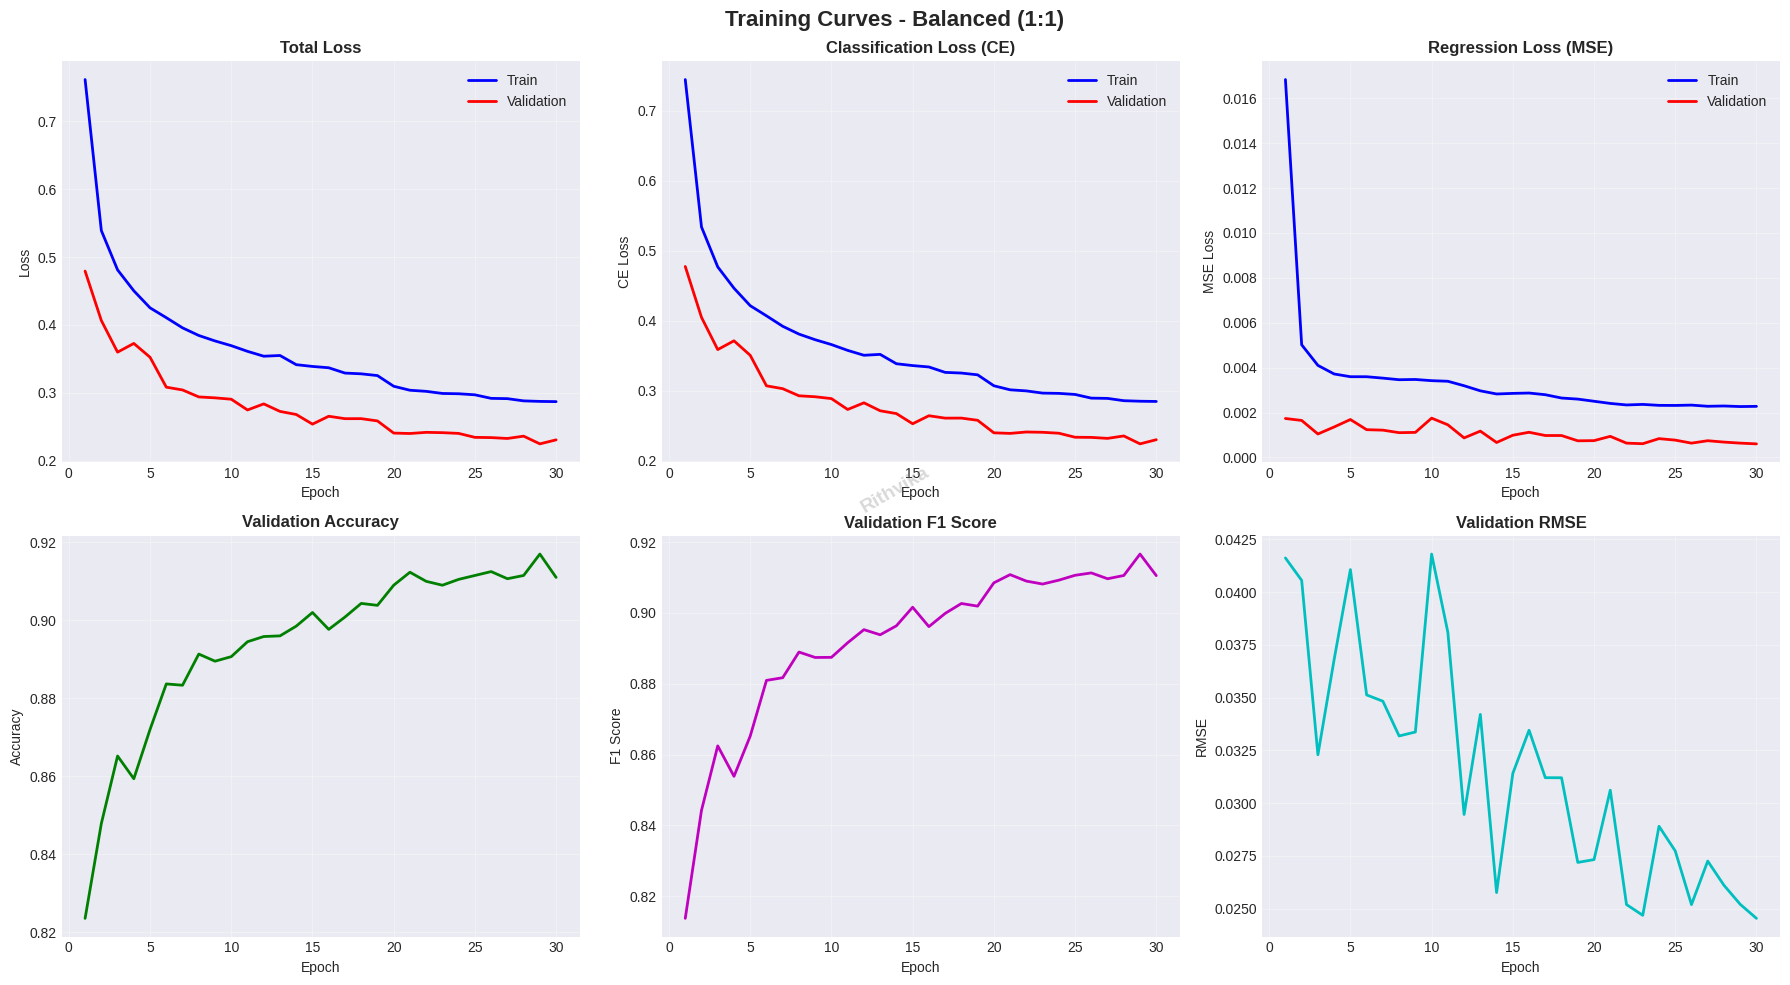


EVALUATING ON TEST SET

✓ Test Results:
  • Accuracy:  0.9110
  • F1 Score:  0.9109
  • MAE:       0.0182
  • RMSE:      0.0239

CONFUSION MATRIX


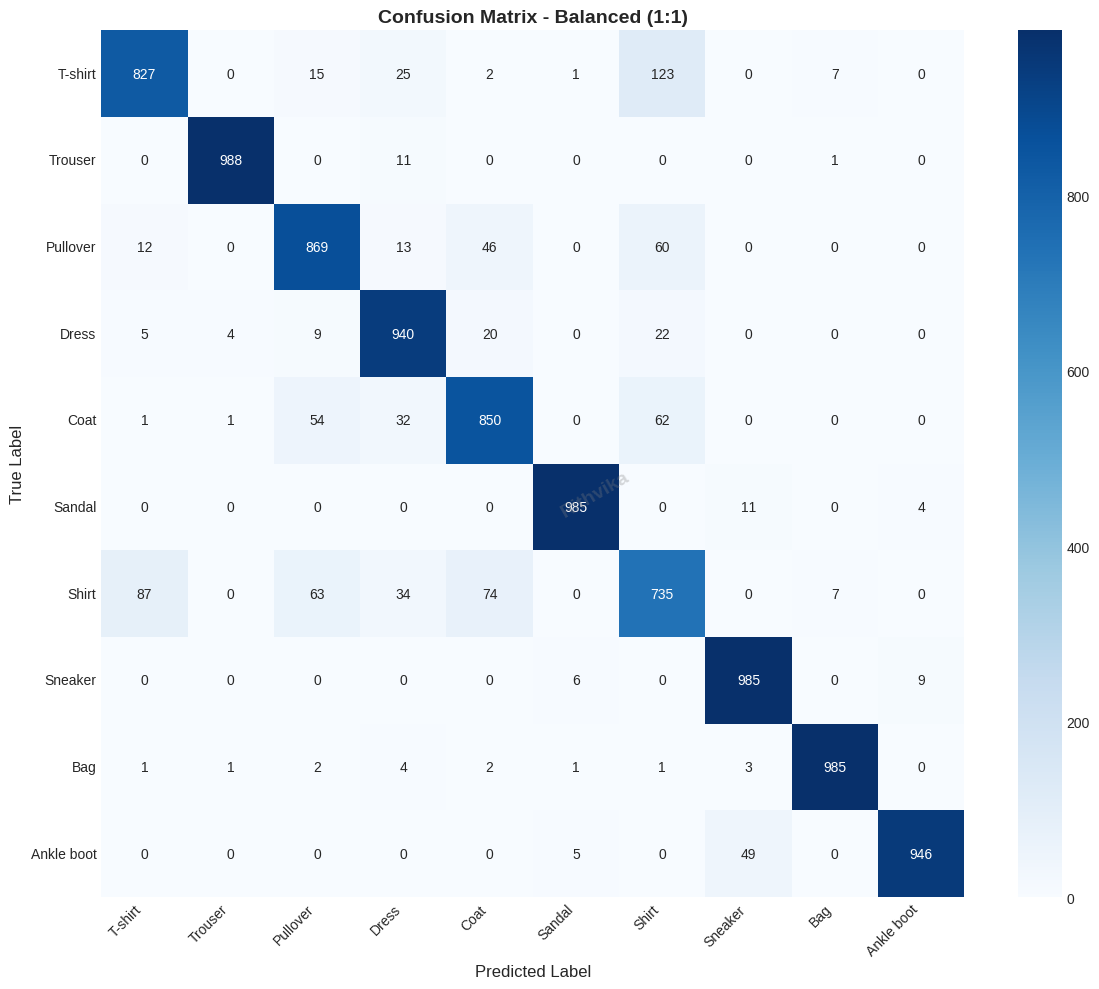


SAMPLE PREDICTIONS


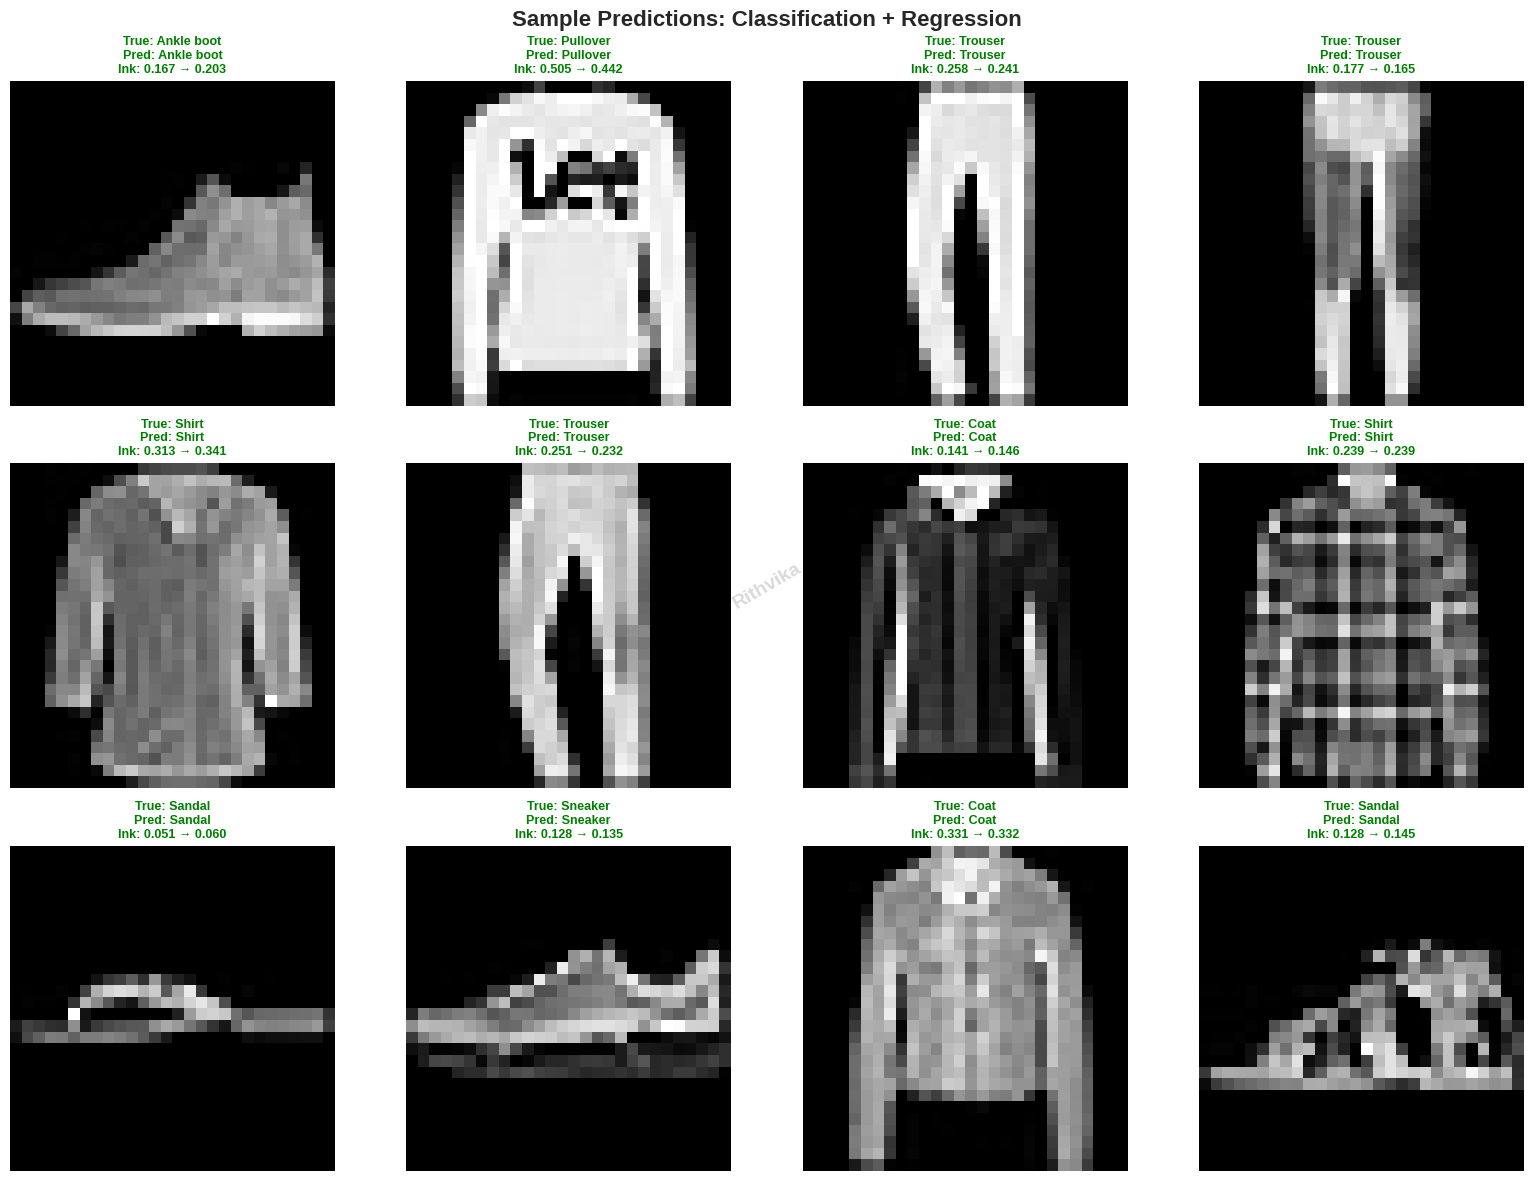


FEATURE MAP VISUALIZATIONS


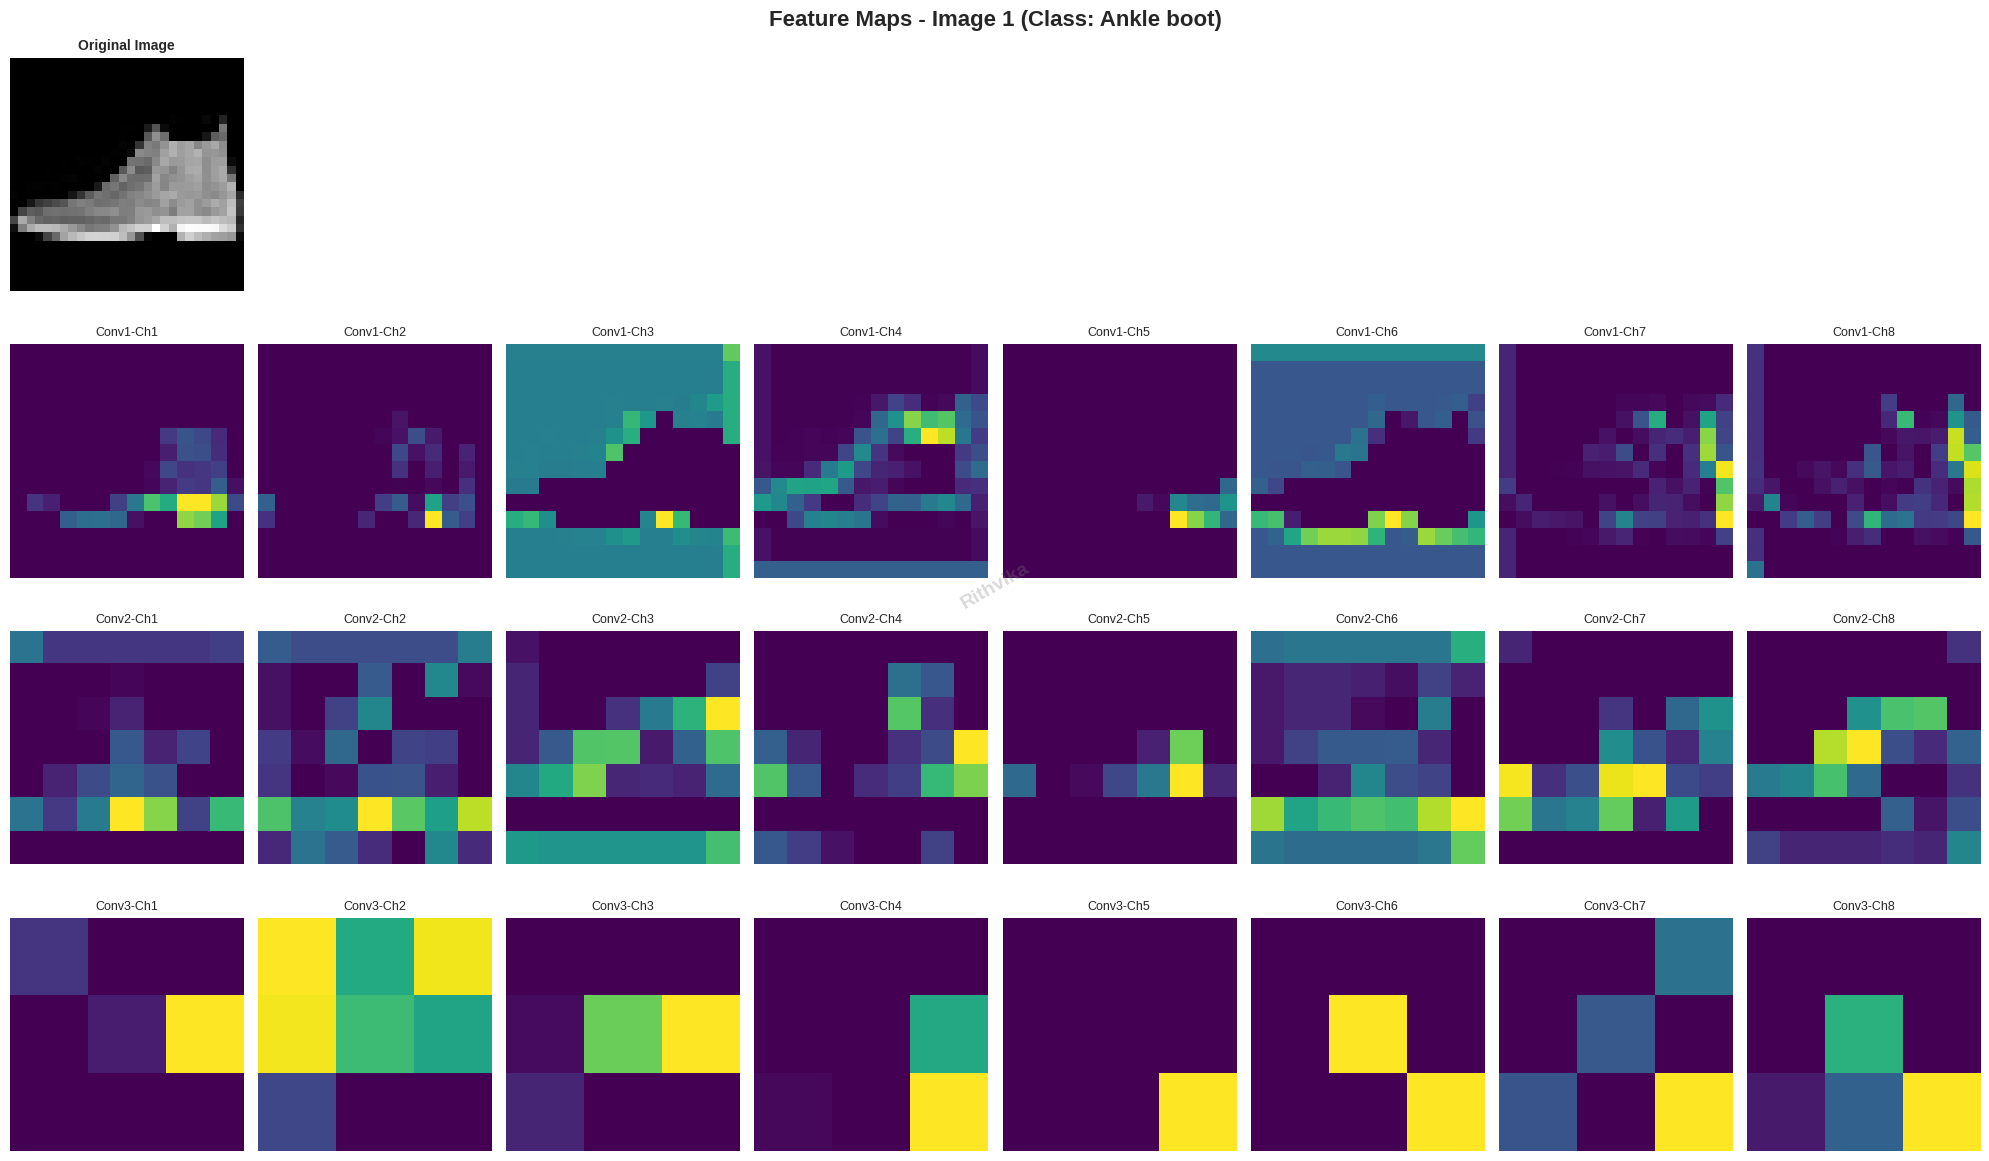

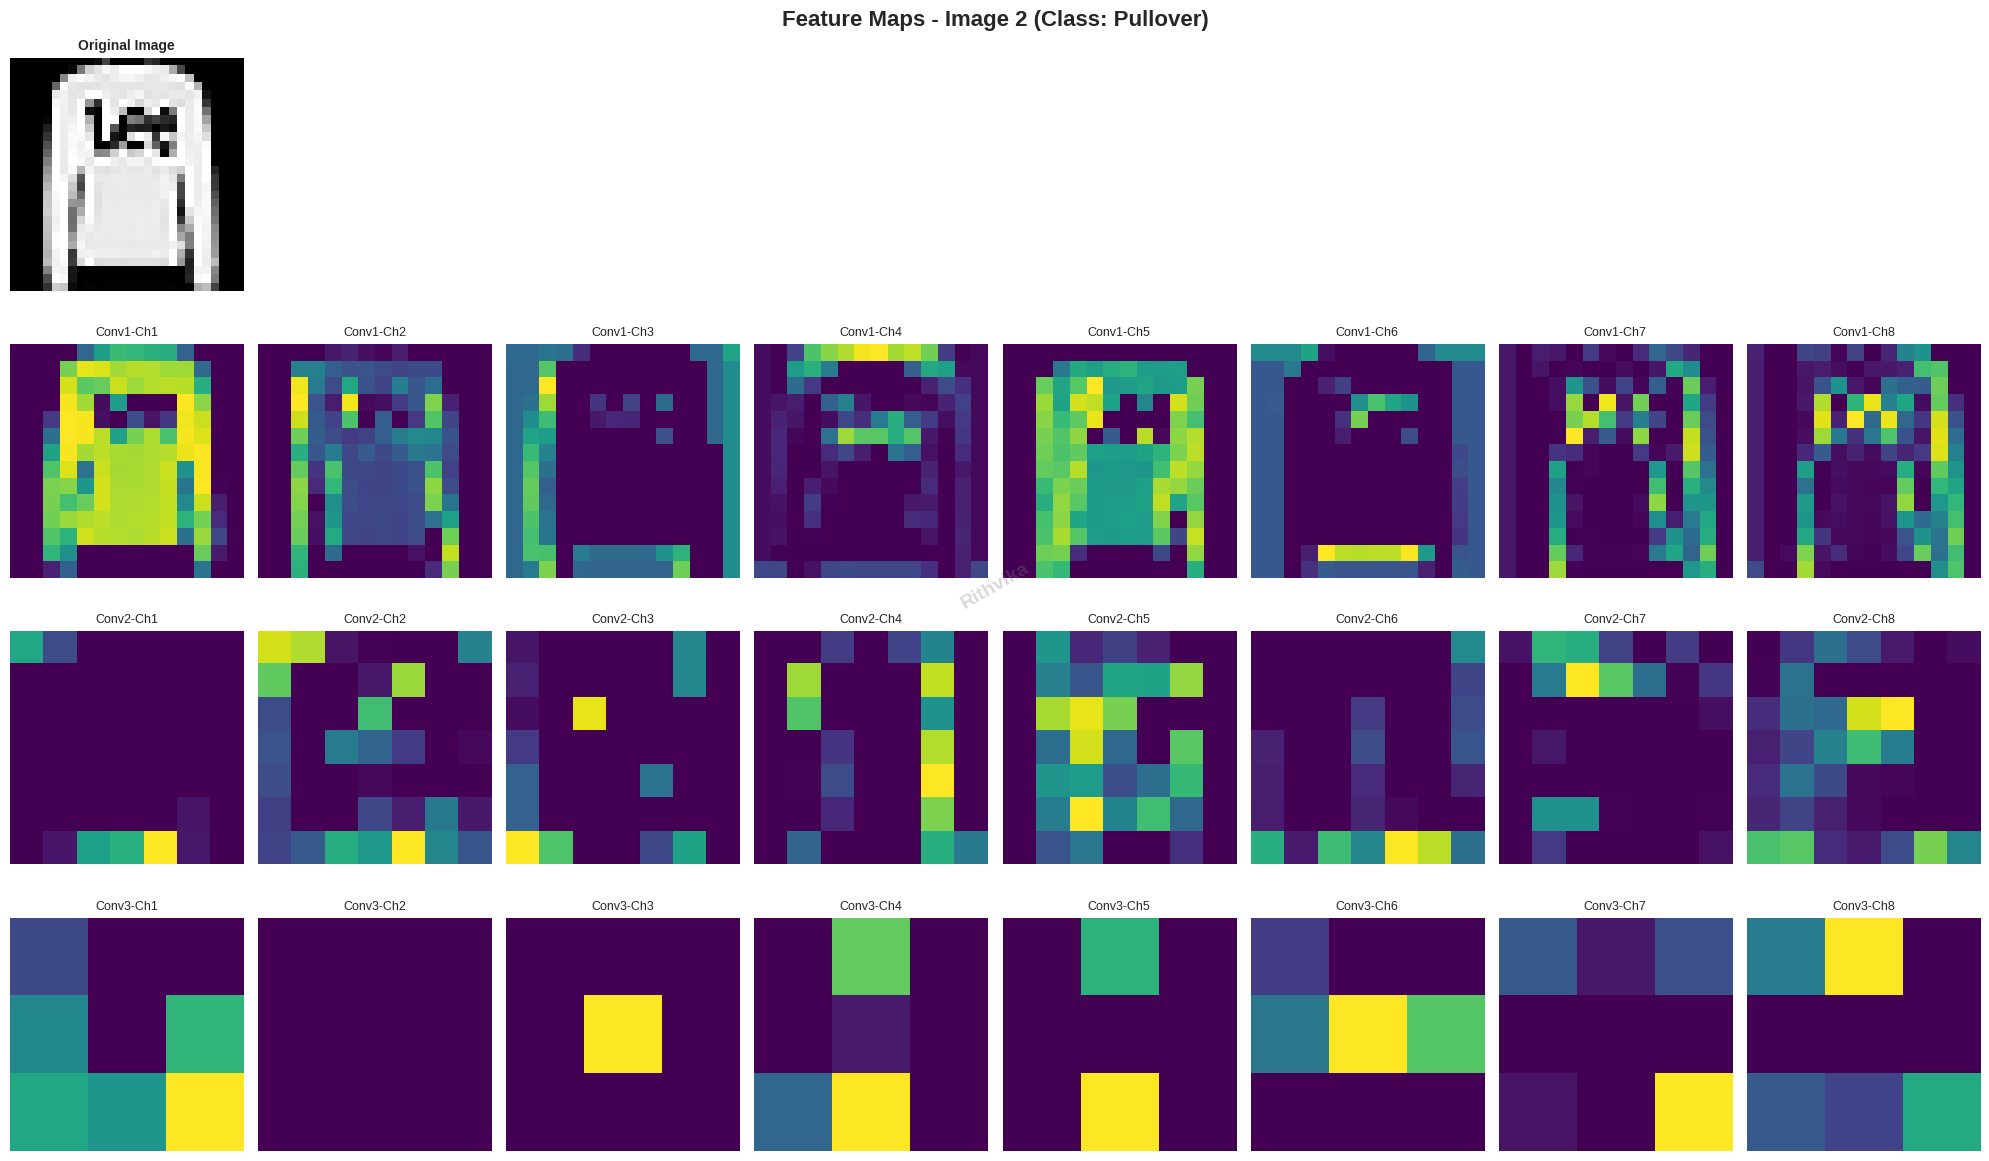

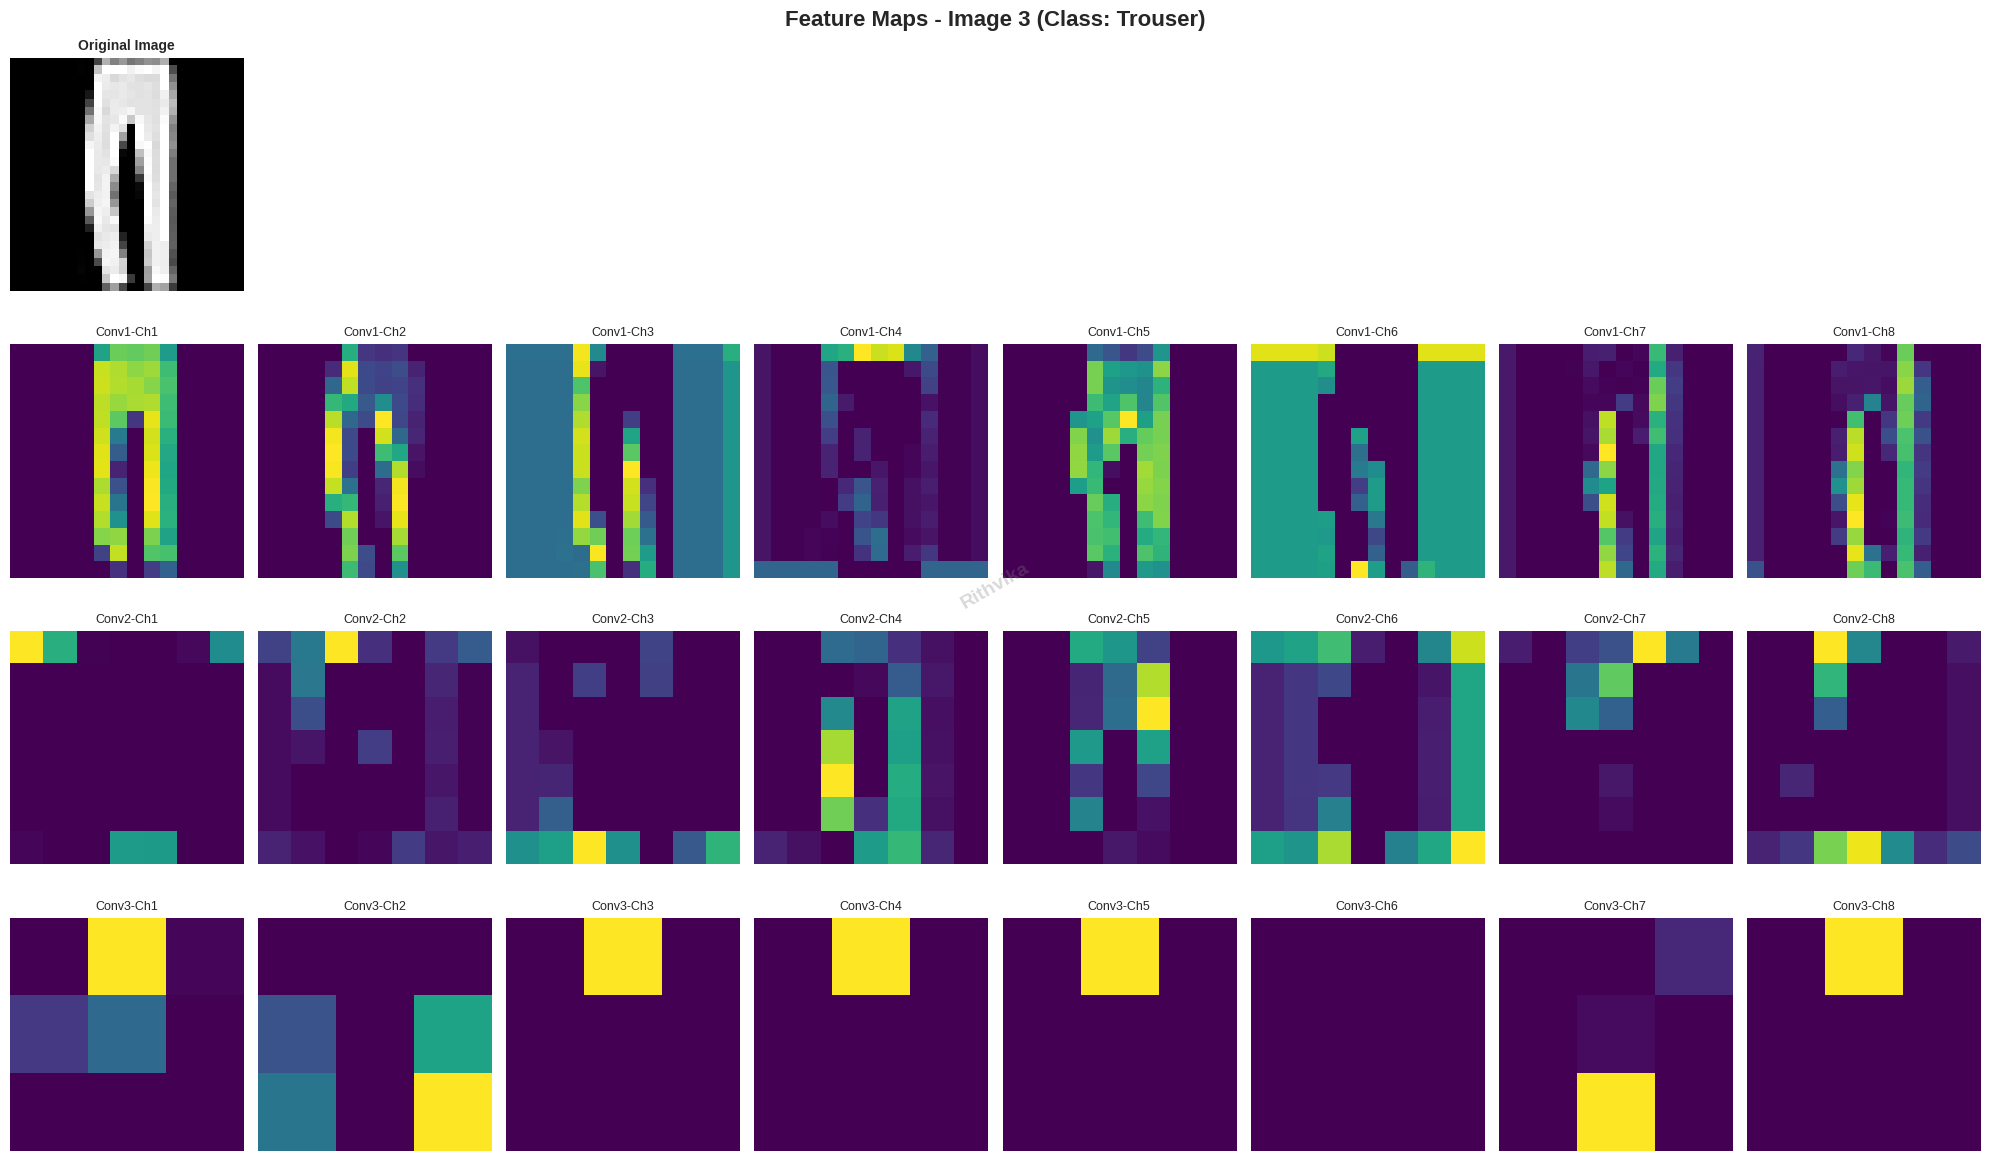


 Feature map visualizations completed and logged to wandb'


epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
learning_rate,██████████████████▁▁▁▁▁▁▁▁▁▁▁▁
test/accuracy,▁
test/f1_score,▁
test/loss,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▅▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁
train/loss,█▅▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁
train/mse_loss,█▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
+7,...



✓ Experiment 1 completed!


EXPERIMENT 2/8: Classification Focus (2:1)
Configuration:
  • Learning Rate: 0.001
  • Optimizer: Adam
  • Dropout: 0.3
  • Batch Size: 128
  • Lambda1 (Classification): 2.0
  • Lambda2 (Regression): 1.0
  • Channels/Filters: [32, 64, 128] (Blocks: 3)
------------------------------------------------------------------------------------------------------------------------



Using device: cuda
Loading data...
Creating model...
Training...
Epoch 1/30 - Train Loss: 1.5185, Val Loss: 0.9570, Val Acc: 0.8143, Val RMSE: 0.0684
Epoch 2/30 - Train Loss: 1.0622, Val Loss: 0.8448, Val Acc: 0.8392, Val RMSE: 0.0510
Epoch 3/30 - Train Loss: 0.9533, Val Loss: 0.8050, Val Acc: 0.8520, Val RMSE: 0.0559
Epoch 4/30 - Train Loss: 0.8886, Val Loss: 0.6925, Val Acc: 0.8723, Val RMSE: 0.0411
Epoch 5/30 - Train Loss: 0.8493, Val Loss: 0.6550, Val Acc: 0.8777, Val RMSE: 0.0357
Epoch 6/30 - Train Loss: 0.8182, Val Loss: 0.6394, Val Acc: 0.8813, Val RMSE: 0.0383
Epoch 7/30 - Train Loss: 0.7979, Val Loss: 0.6182, Val Acc: 0.8857, Val RMSE: 0.0380
Epoch 8/30 - Train Loss: 0.7711, Val Loss: 0.6088, Val Acc: 0.8868, Val RMSE: 0.0416
Epoch 9/30 - Train Loss: 0.7494, Val Loss: 0.5850, Val Acc: 0.8912, Val RMSE: 0.0369
Epoch 10/30 - Train Loss: 0.7383, Val Loss: 0.5593, Val Acc: 0.8928, Val RMSE: 0.0346
Epoch 11/30 - Train Loss: 0.7211, Val Loss: 0.5485, Val Acc: 0.8955, Val RMSE: 0.033

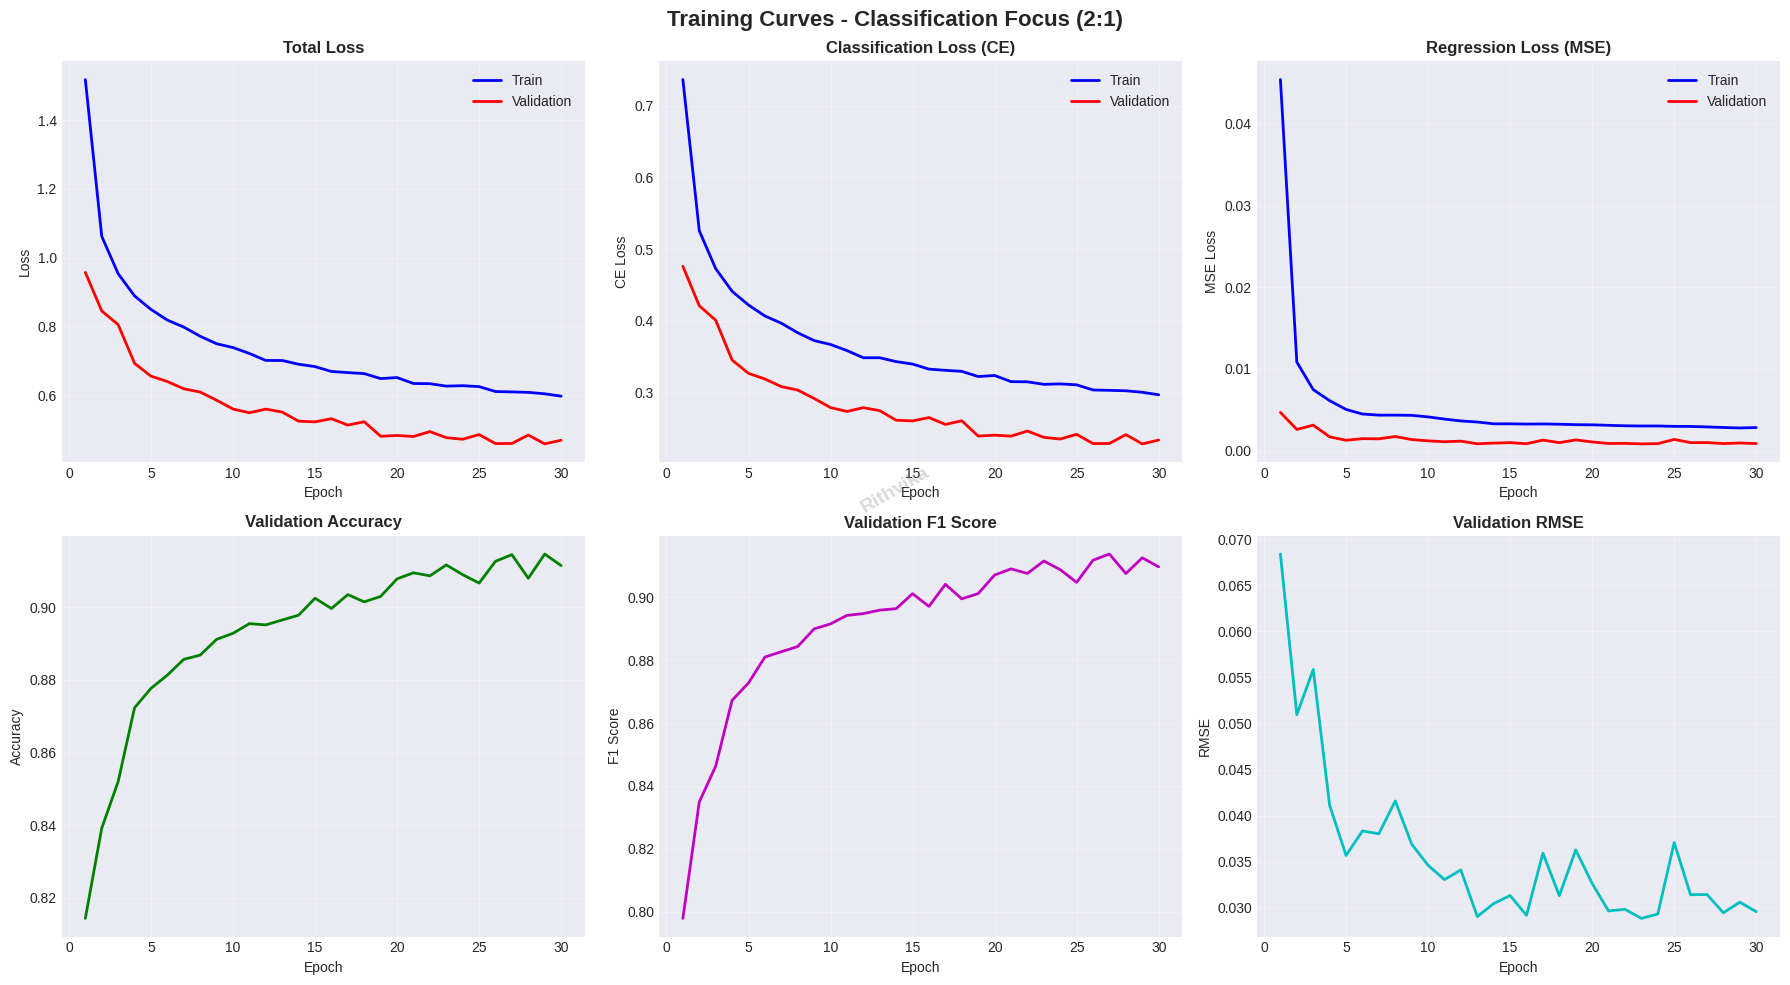


EVALUATING ON TEST SET

✓ Test Results:
  • Accuracy:  0.9120
  • F1 Score:  0.9104
  • MAE:       0.0226
  • RMSE:      0.0293

CONFUSION MATRIX


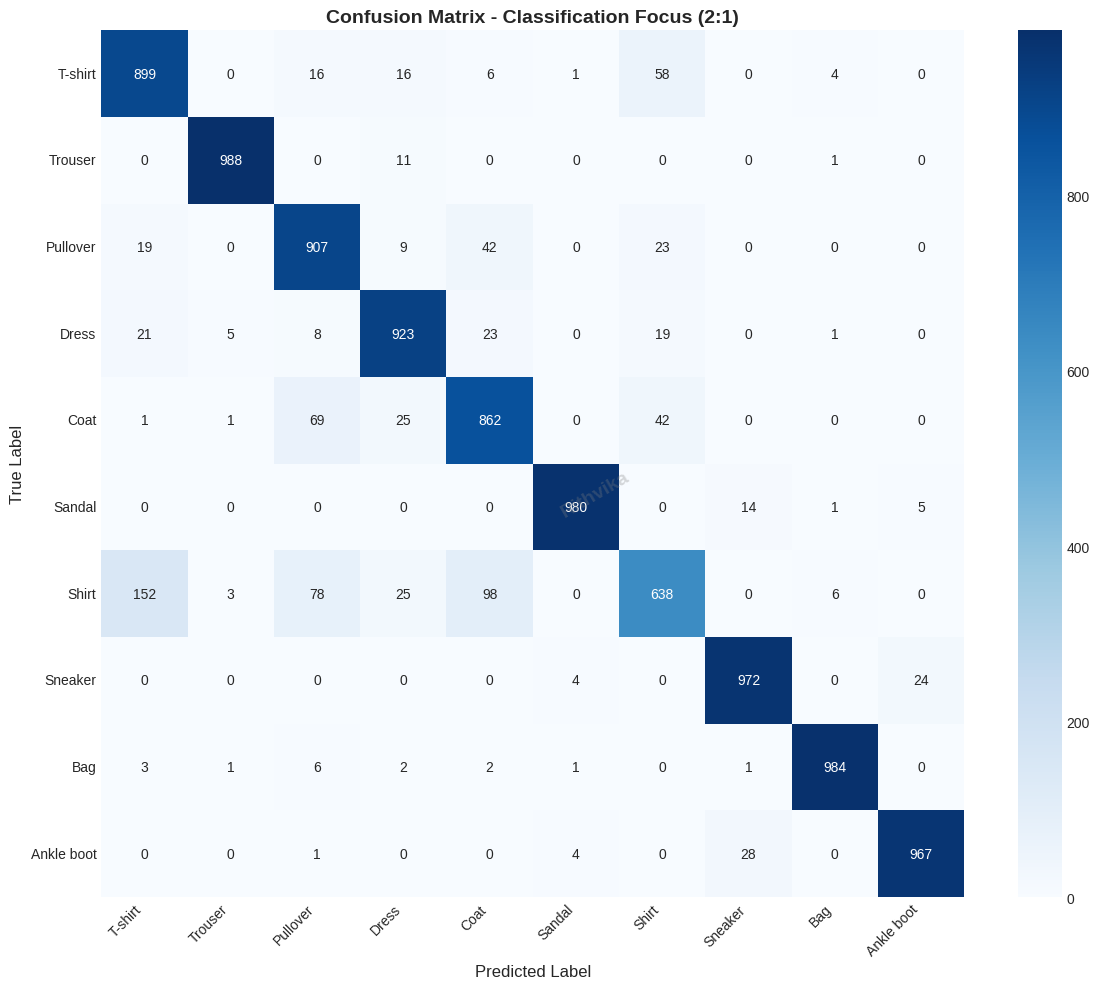


SAMPLE PREDICTIONS


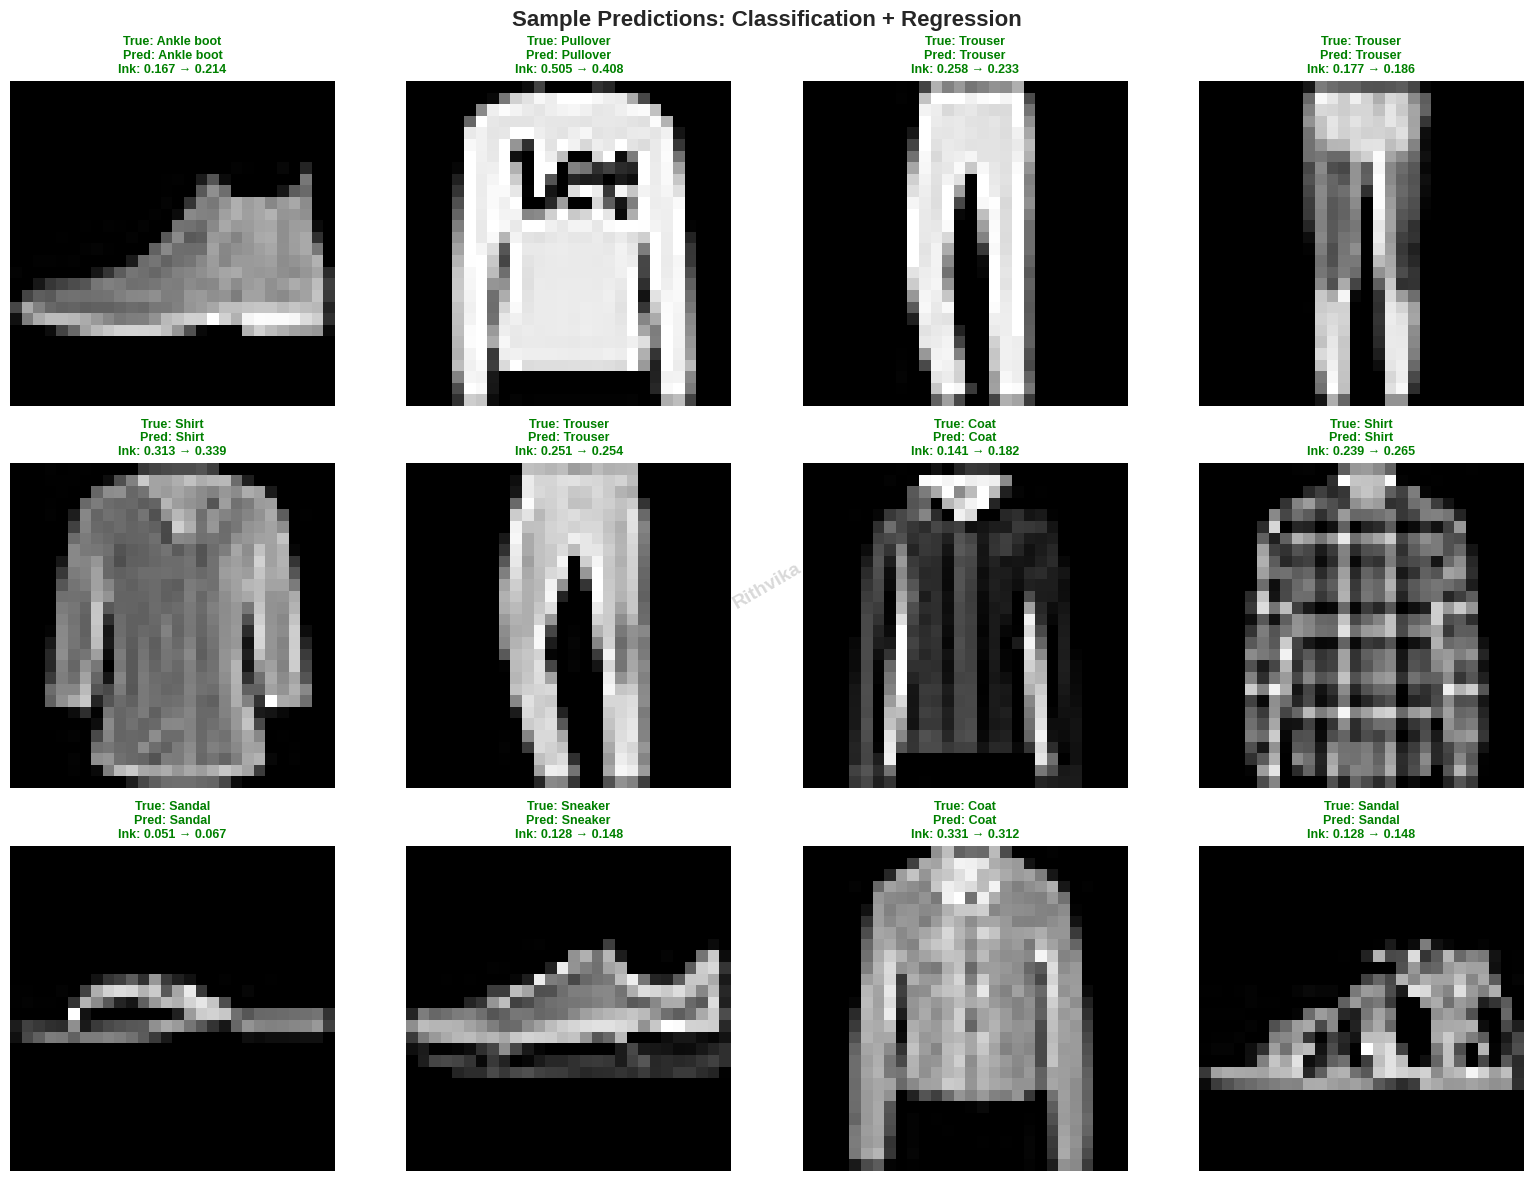


FEATURE MAP VISUALIZATIONS


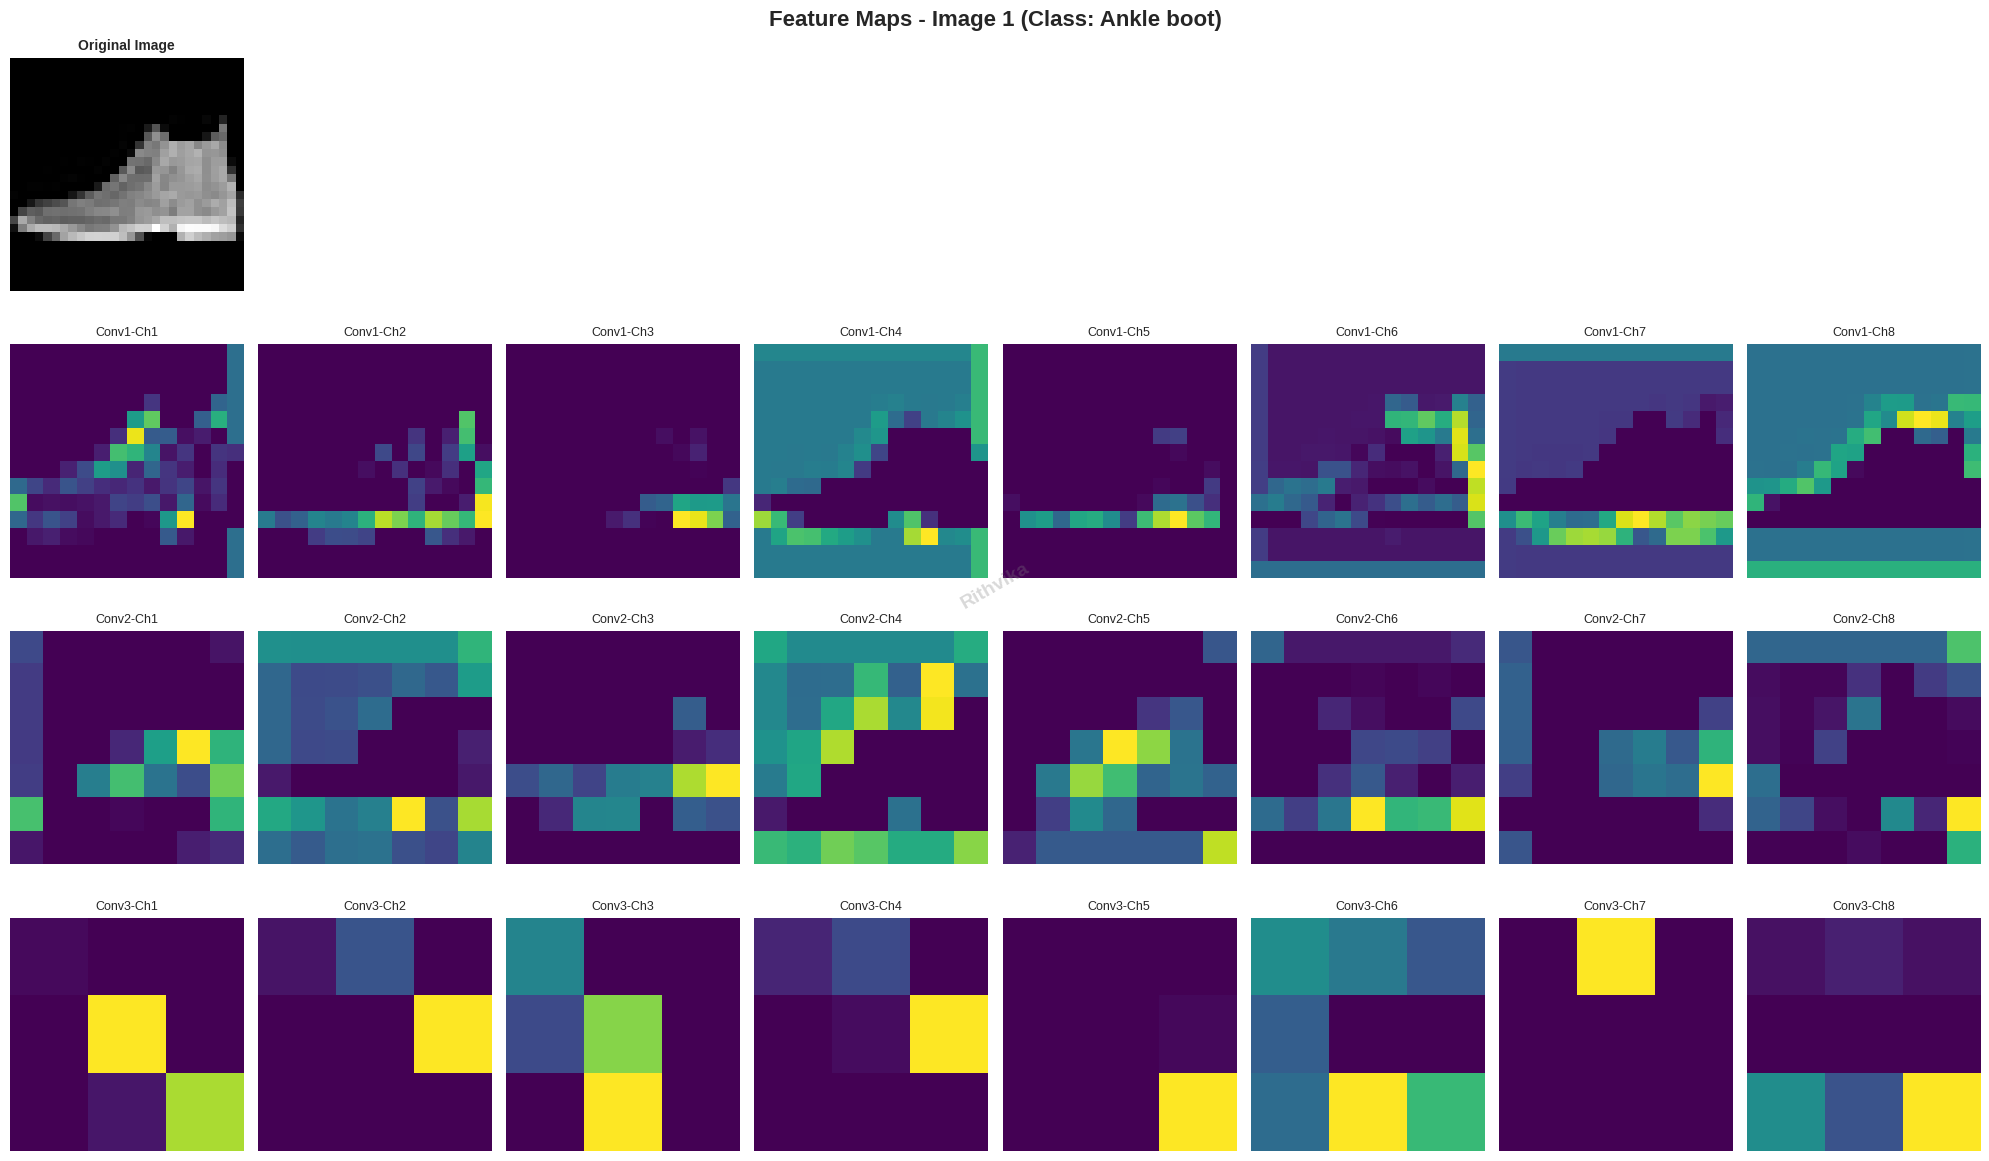

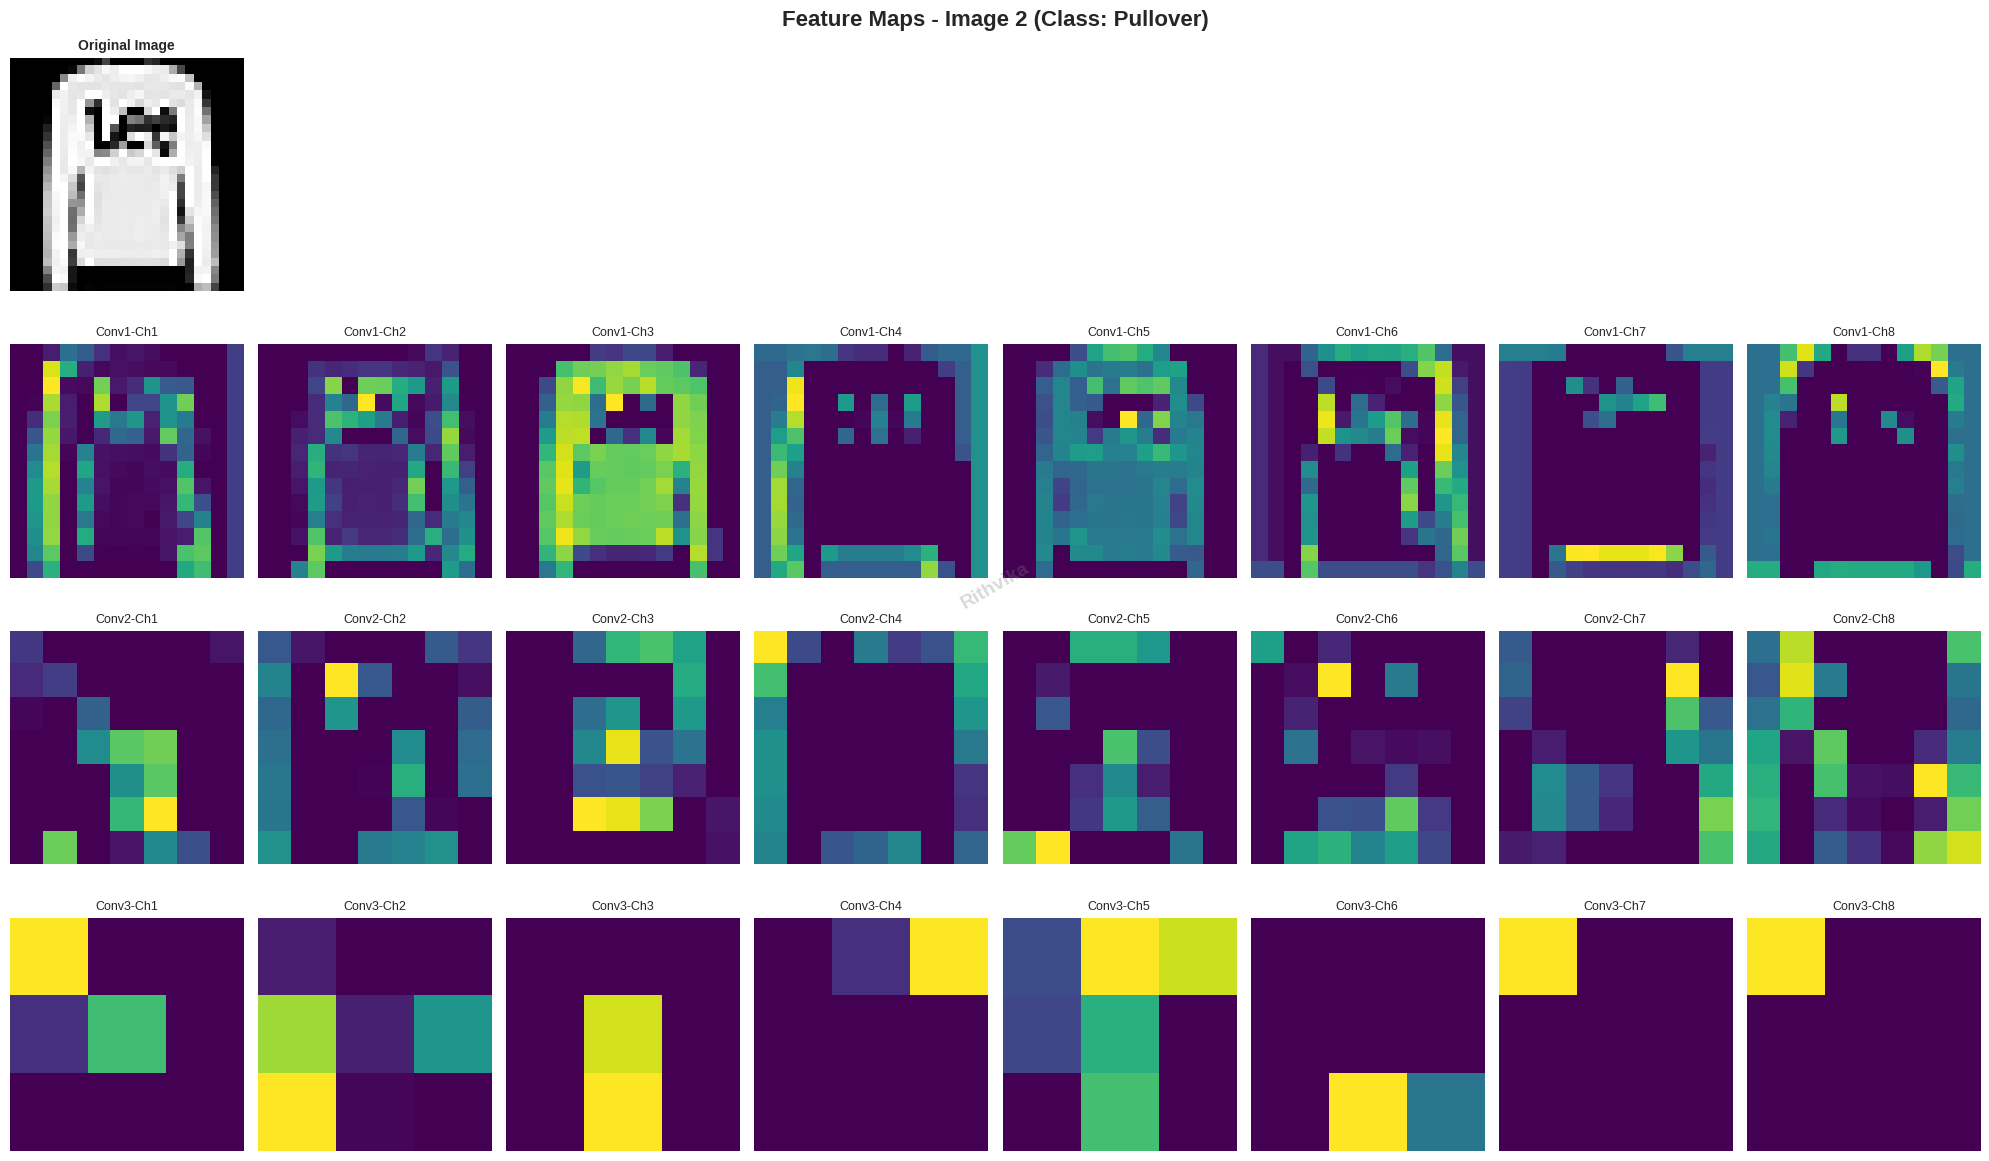

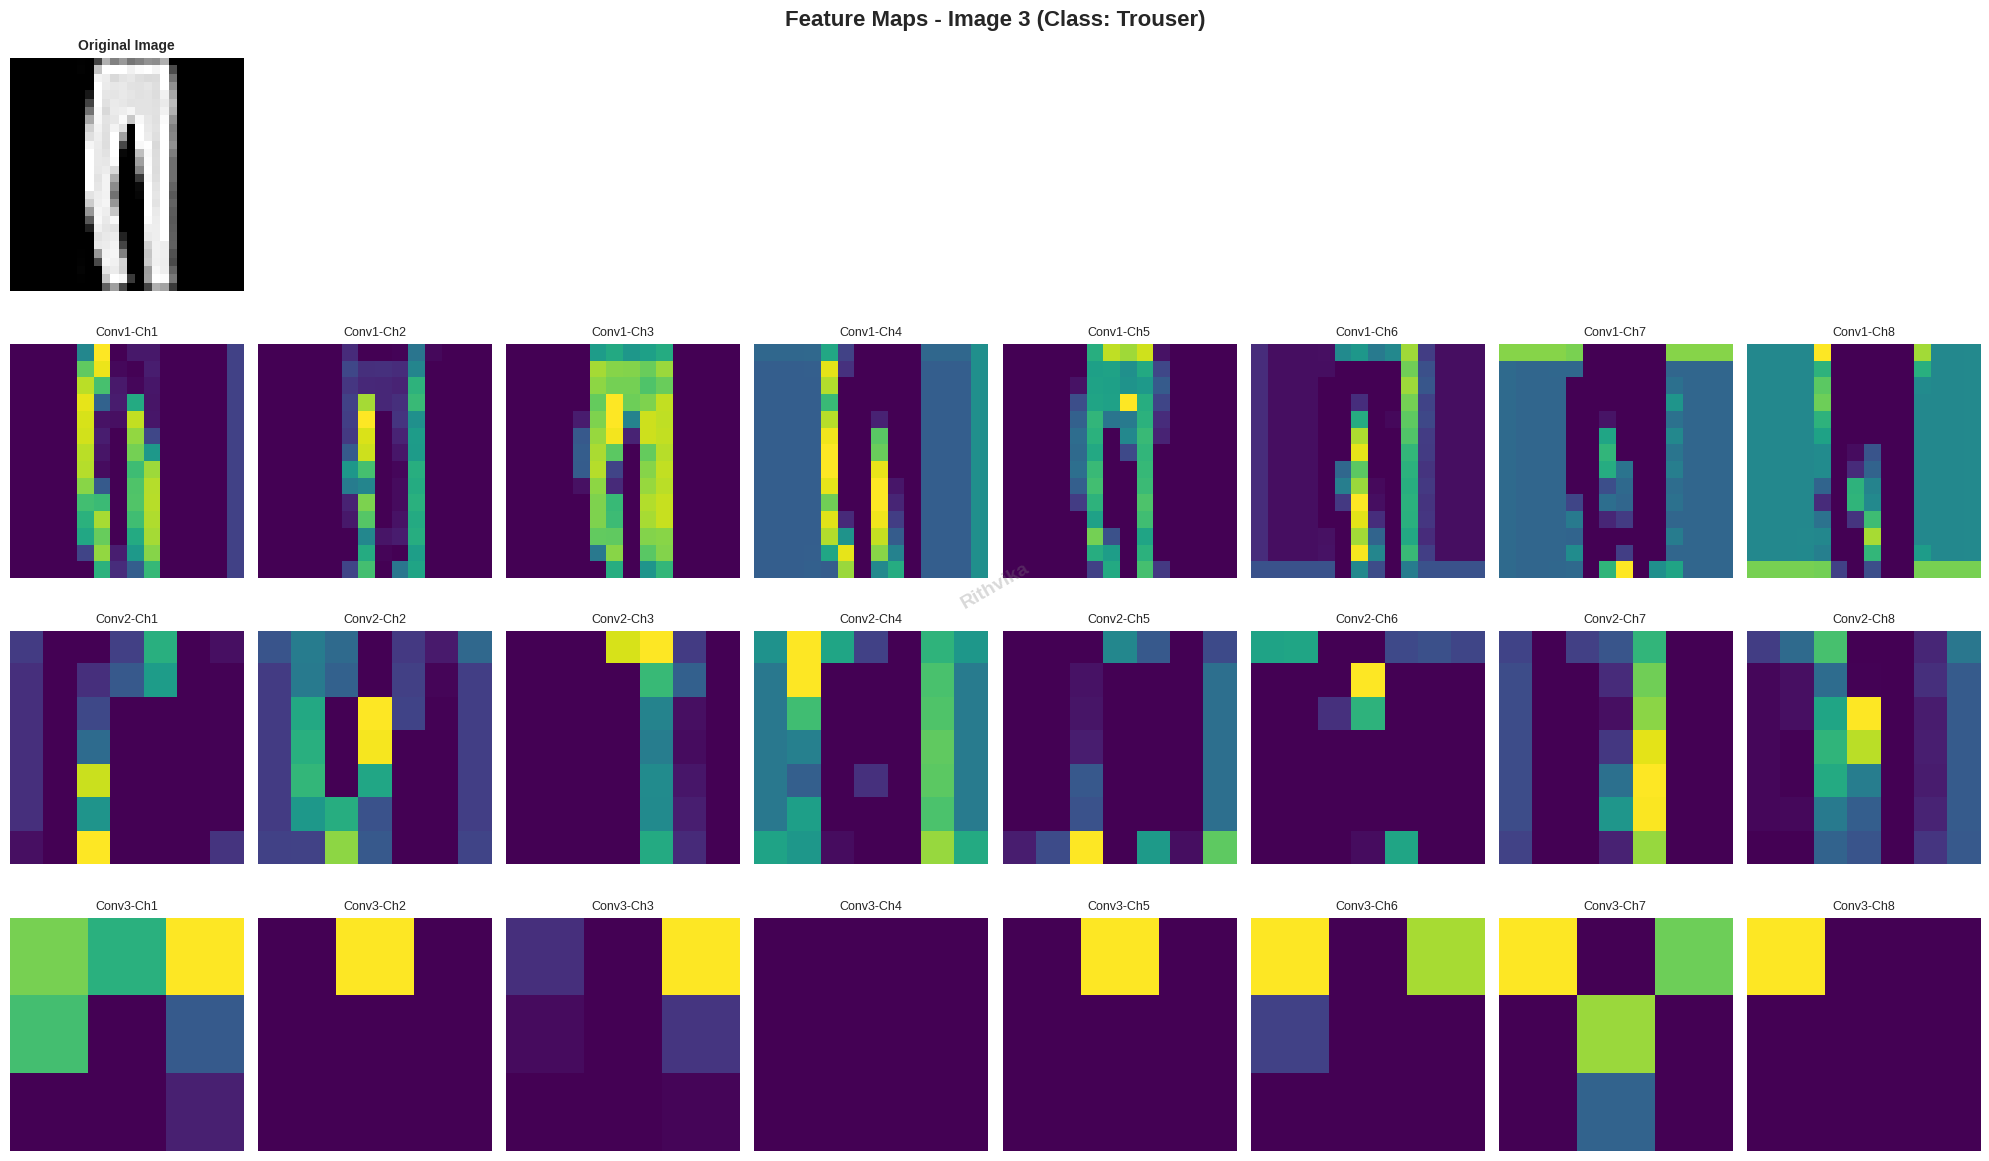


 Feature map visualizations completed and logged to wandb'


epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
test/accuracy,▁
test/f1_score,▁
test/loss,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▅▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
train/loss,█▅▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
train/mse_loss,█▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
+7,...



✓ Experiment 2 completed!


EXPERIMENT 3/8: Regression Focus (1:2)
Configuration:
  • Learning Rate: 0.001
  • Optimizer: Adam
  • Dropout: 0.3
  • Batch Size: 128
  • Lambda1 (Classification): 1.0
  • Lambda2 (Regression): 2.0
  • Channels/Filters: [32, 64, 128] (Blocks: 3)
------------------------------------------------------------------------------------------------------------------------



Using device: cuda
Loading data...
Creating model...
Training...
Epoch 1/30 - Train Loss: 0.8985, Val Loss: 0.5167, Val Acc: 0.8007, Val RMSE: 0.0695
Epoch 2/30 - Train Loss: 0.5805, Val Loss: 0.4242, Val Acc: 0.8432, Val RMSE: 0.0531
Epoch 3/30 - Train Loss: 0.5081, Val Loss: 0.3814, Val Acc: 0.8605, Val RMSE: 0.0451
Epoch 4/30 - Train Loss: 0.4750, Val Loss: 0.3649, Val Acc: 0.8623, Val RMSE: 0.0334
Epoch 5/30 - Train Loss: 0.4512, Val Loss: 0.3521, Val Acc: 0.8708, Val RMSE: 0.0404
Epoch 6/30 - Train Loss: 0.4301, Val Loss: 0.3292, Val Acc: 0.8765, Val RMSE: 0.0360
Epoch 7/30 - Train Loss: 0.4147, Val Loss: 0.3260, Val Acc: 0.8830, Val RMSE: 0.0389
Epoch 8/30 - Train Loss: 0.4051, Val Loss: 0.3121, Val Acc: 0.8887, Val RMSE: 0.0348
Epoch 9/30 - Train Loss: 0.3931, Val Loss: 0.2962, Val Acc: 0.8918, Val RMSE: 0.0341
Epoch 10/30 - Train Loss: 0.3850, Val Loss: 0.2919, Val Acc: 0.8908, Val RMSE: 0.0350
Epoch 11/30 - Train Loss: 0.3747, Val Loss: 0.2792, Val Acc: 0.8962, Val RMSE: 0.034

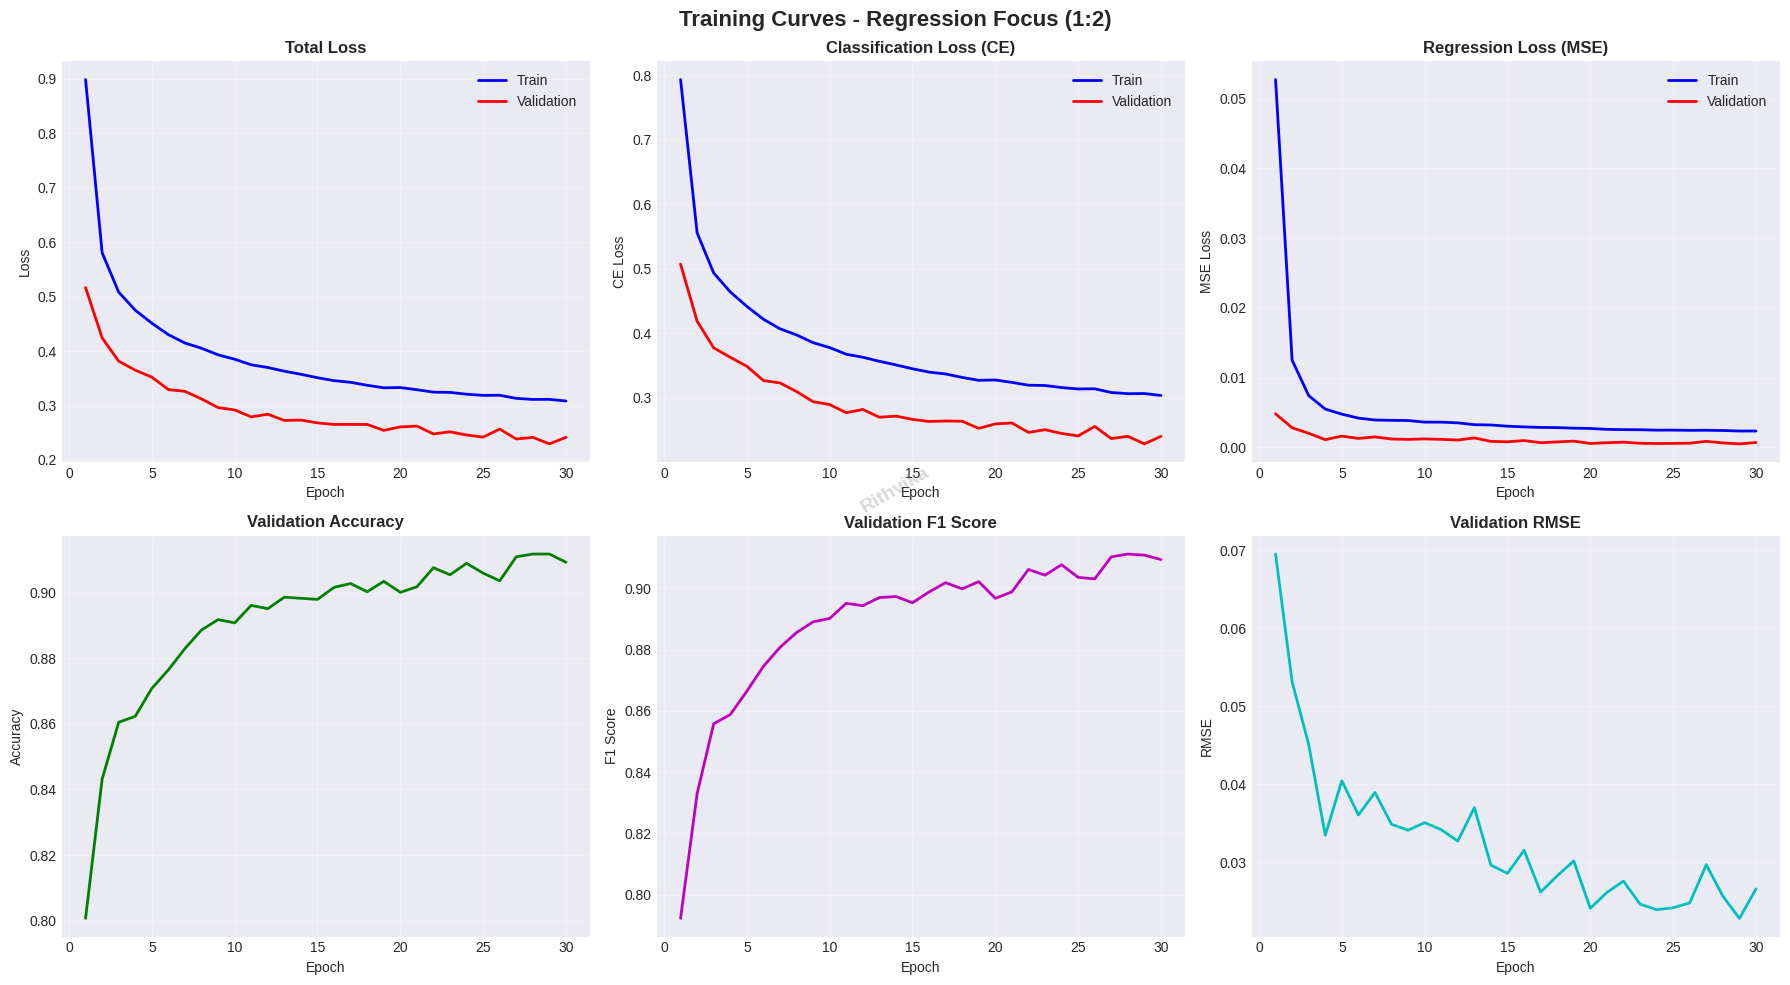


EVALUATING ON TEST SET

✓ Test Results:
  • Accuracy:  0.9099
  • F1 Score:  0.9102
  • MAE:       0.0209
  • RMSE:      0.0264

CONFUSION MATRIX


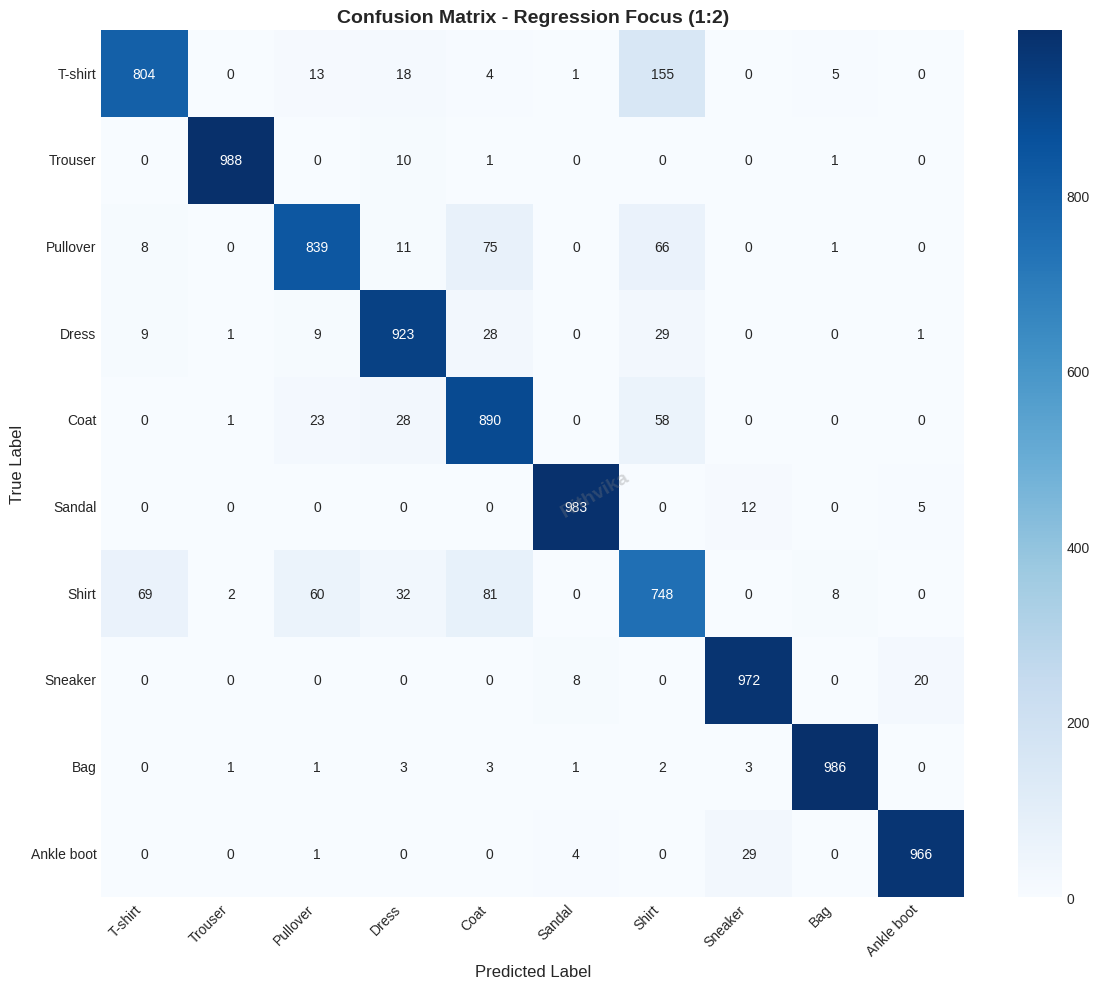


SAMPLE PREDICTIONS


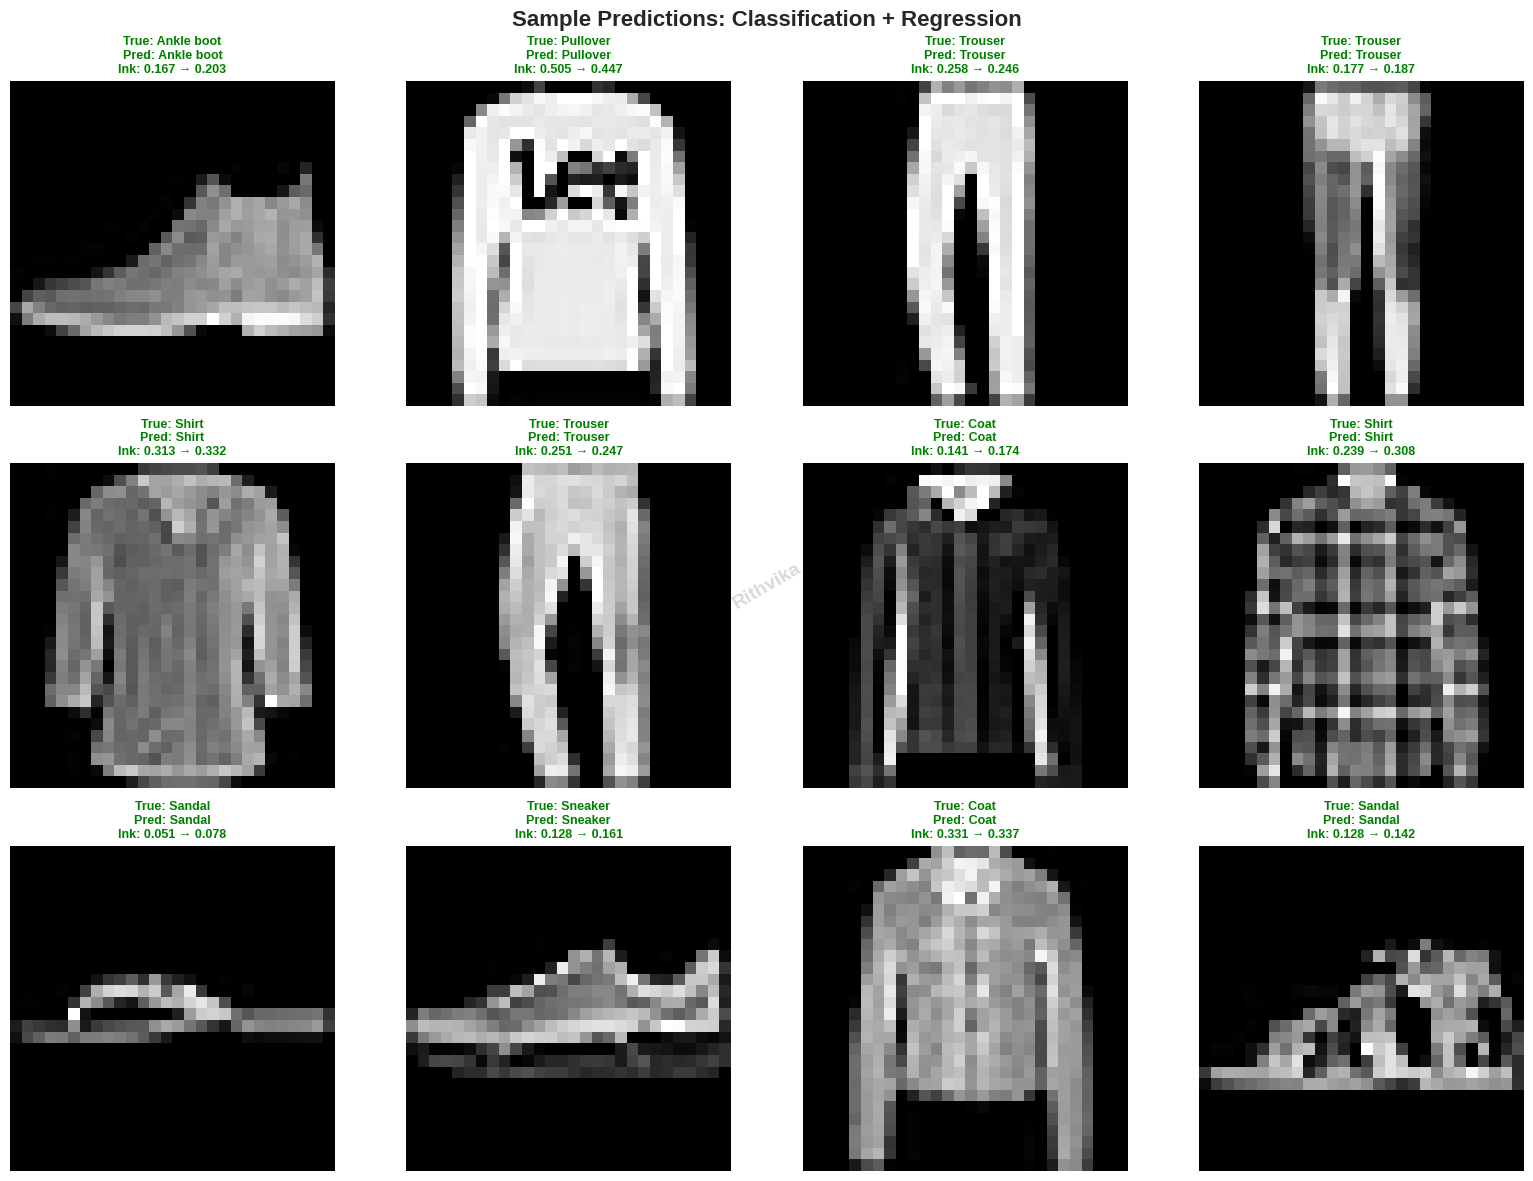


FEATURE MAP VISUALIZATIONS


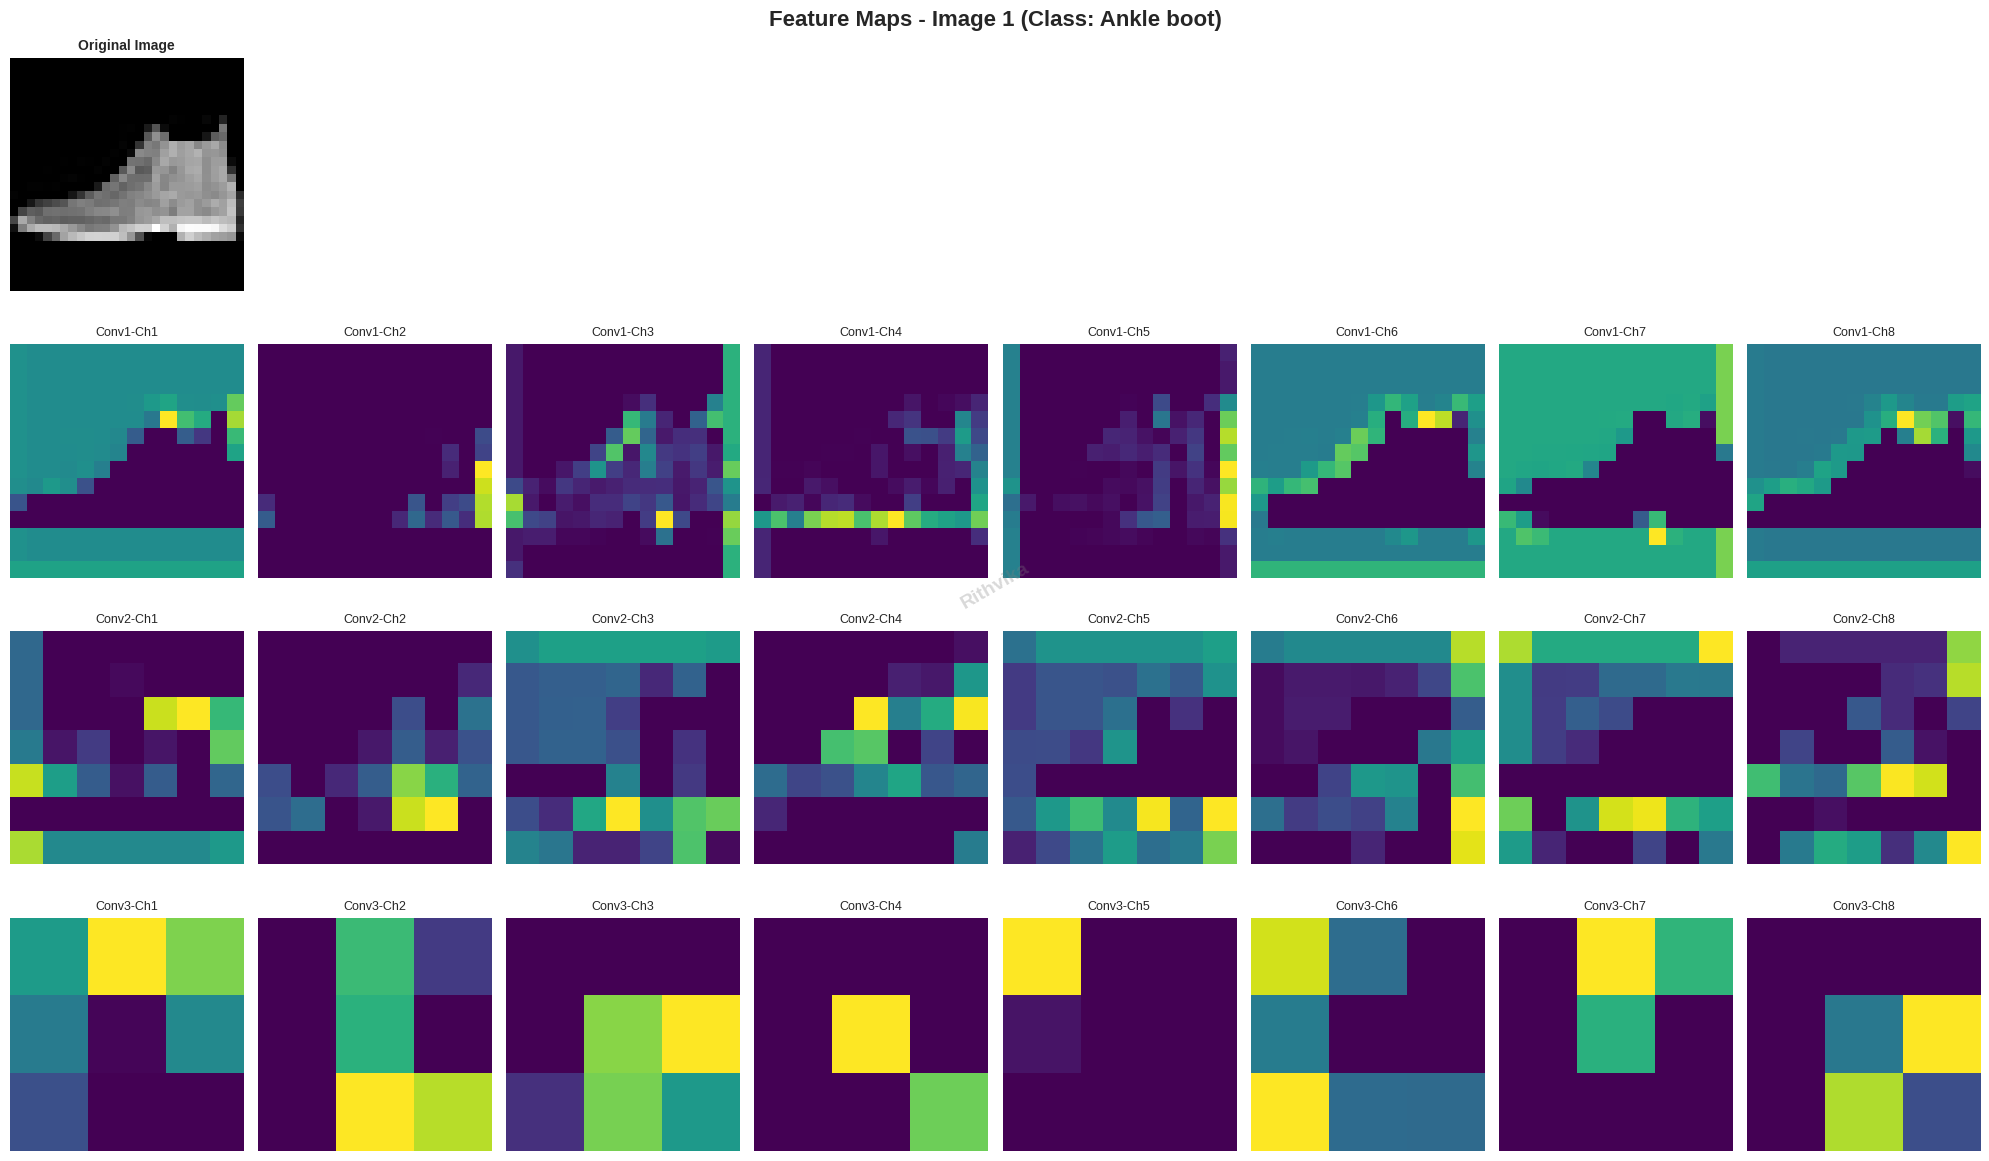

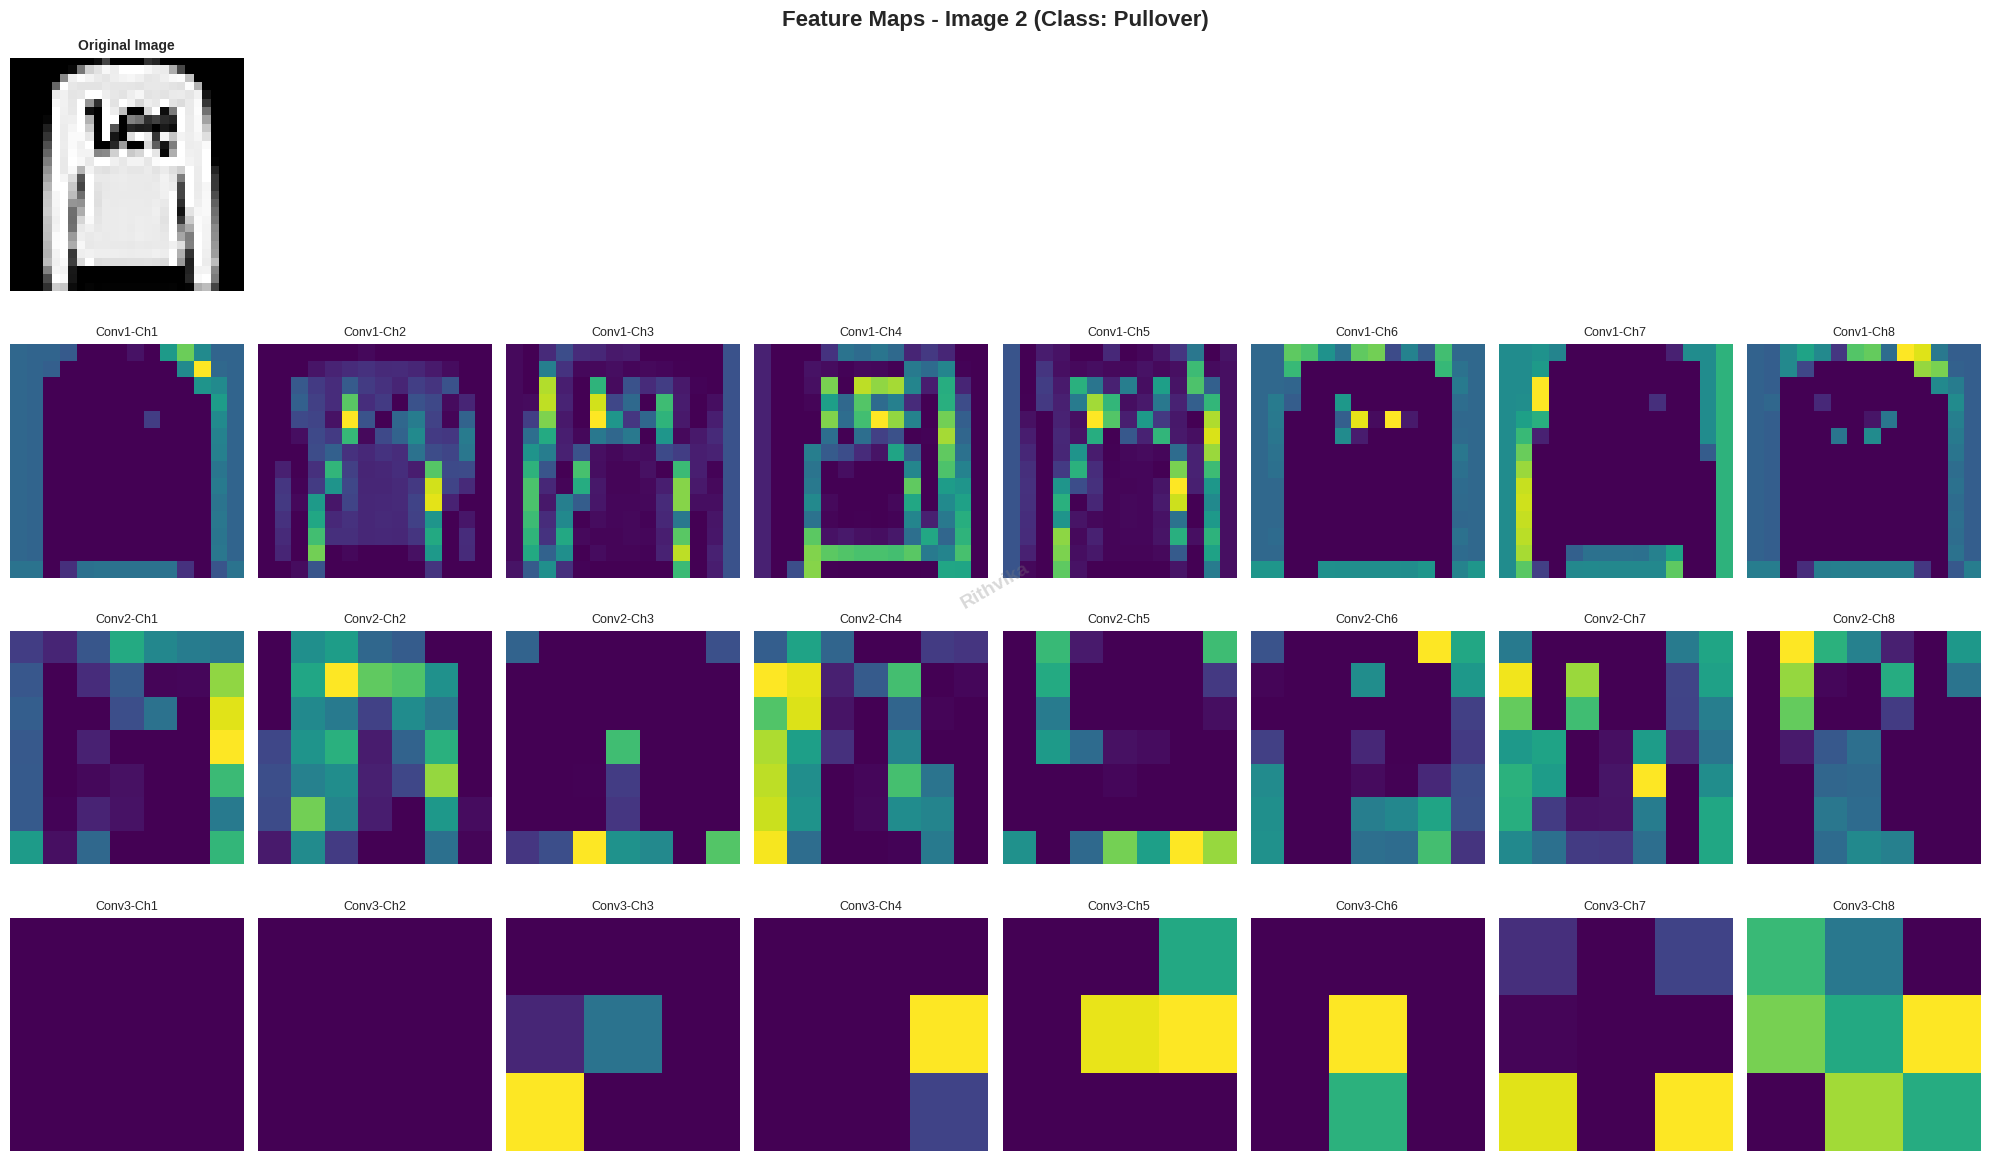

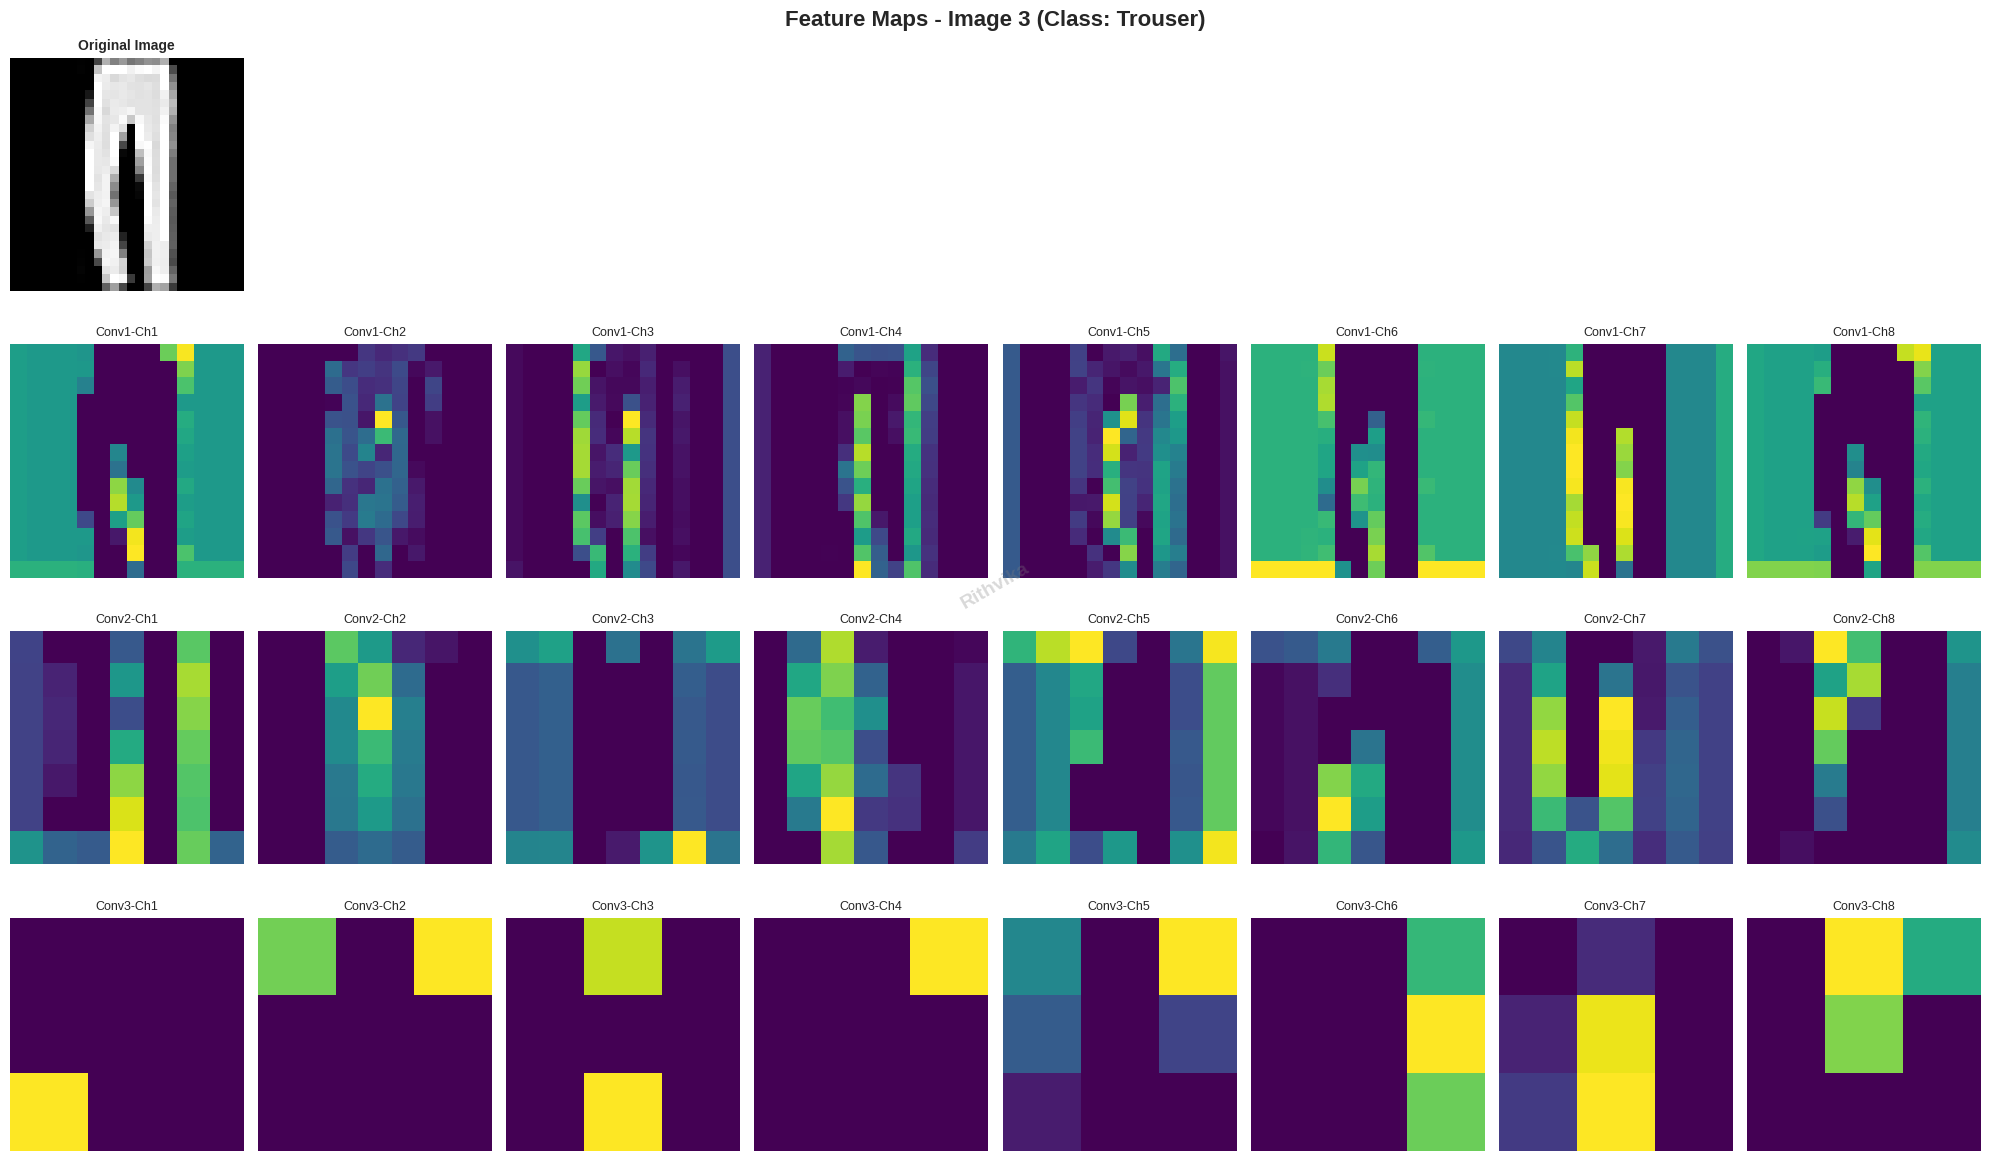


 Feature map visualizations completed and logged to wandb'


epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
test/accuracy,▁
test/f1_score,▁
test/loss,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▅▄▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/loss,█▄▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/mse_loss,█▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
+7,...



✓ Experiment 3 completed!


EXPERIMENT 4/8: Regression Focus (0.5:1)
Configuration:
  • Learning Rate: 0.001
  • Optimizer: AdamW
  • Dropout: 0.3
  • Batch Size: 128
  • Lambda1 (Classification): 0.5
  • Lambda2 (Regression): 1.0
  • Channels/Filters: [32, 64, 128] (Blocks: 3)
------------------------------------------------------------------------------------------------------------------------



Using device: cuda
Loading data...
Creating model...
Training...
Epoch 1/30 - Train Loss: 0.4565, Val Loss: 0.2642, Val Acc: 0.8113, Val RMSE: 0.1409
Epoch 2/30 - Train Loss: 0.2901, Val Loss: 0.2227, Val Acc: 0.8358, Val RMSE: 0.0856
Epoch 3/30 - Train Loss: 0.2558, Val Loss: 0.1918, Val Acc: 0.8595, Val RMSE: 0.0677
Epoch 4/30 - Train Loss: 0.2367, Val Loss: 0.1849, Val Acc: 0.8623, Val RMSE: 0.0585
Epoch 5/30 - Train Loss: 0.2219, Val Loss: 0.1687, Val Acc: 0.8757, Val RMSE: 0.0562
Epoch 6/30 - Train Loss: 0.2132, Val Loss: 0.1609, Val Acc: 0.8817, Val RMSE: 0.0422
Epoch 7/30 - Train Loss: 0.2057, Val Loss: 0.1748, Val Acc: 0.8777, Val RMSE: 0.0357
Epoch 8/30 - Train Loss: 0.1984, Val Loss: 0.1636, Val Acc: 0.8828, Val RMSE: 0.0327
Epoch 9/30 - Train Loss: 0.1945, Val Loss: 0.1685, Val Acc: 0.8788, Val RMSE: 0.0351
Epoch 10/30 - Train Loss: 0.1893, Val Loss: 0.1524, Val Acc: 0.8893, Val RMSE: 0.0388
Epoch 11/30 - Train Loss: 0.1880, Val Loss: 0.1517, Val Acc: 0.8877, Val RMSE: 0.034

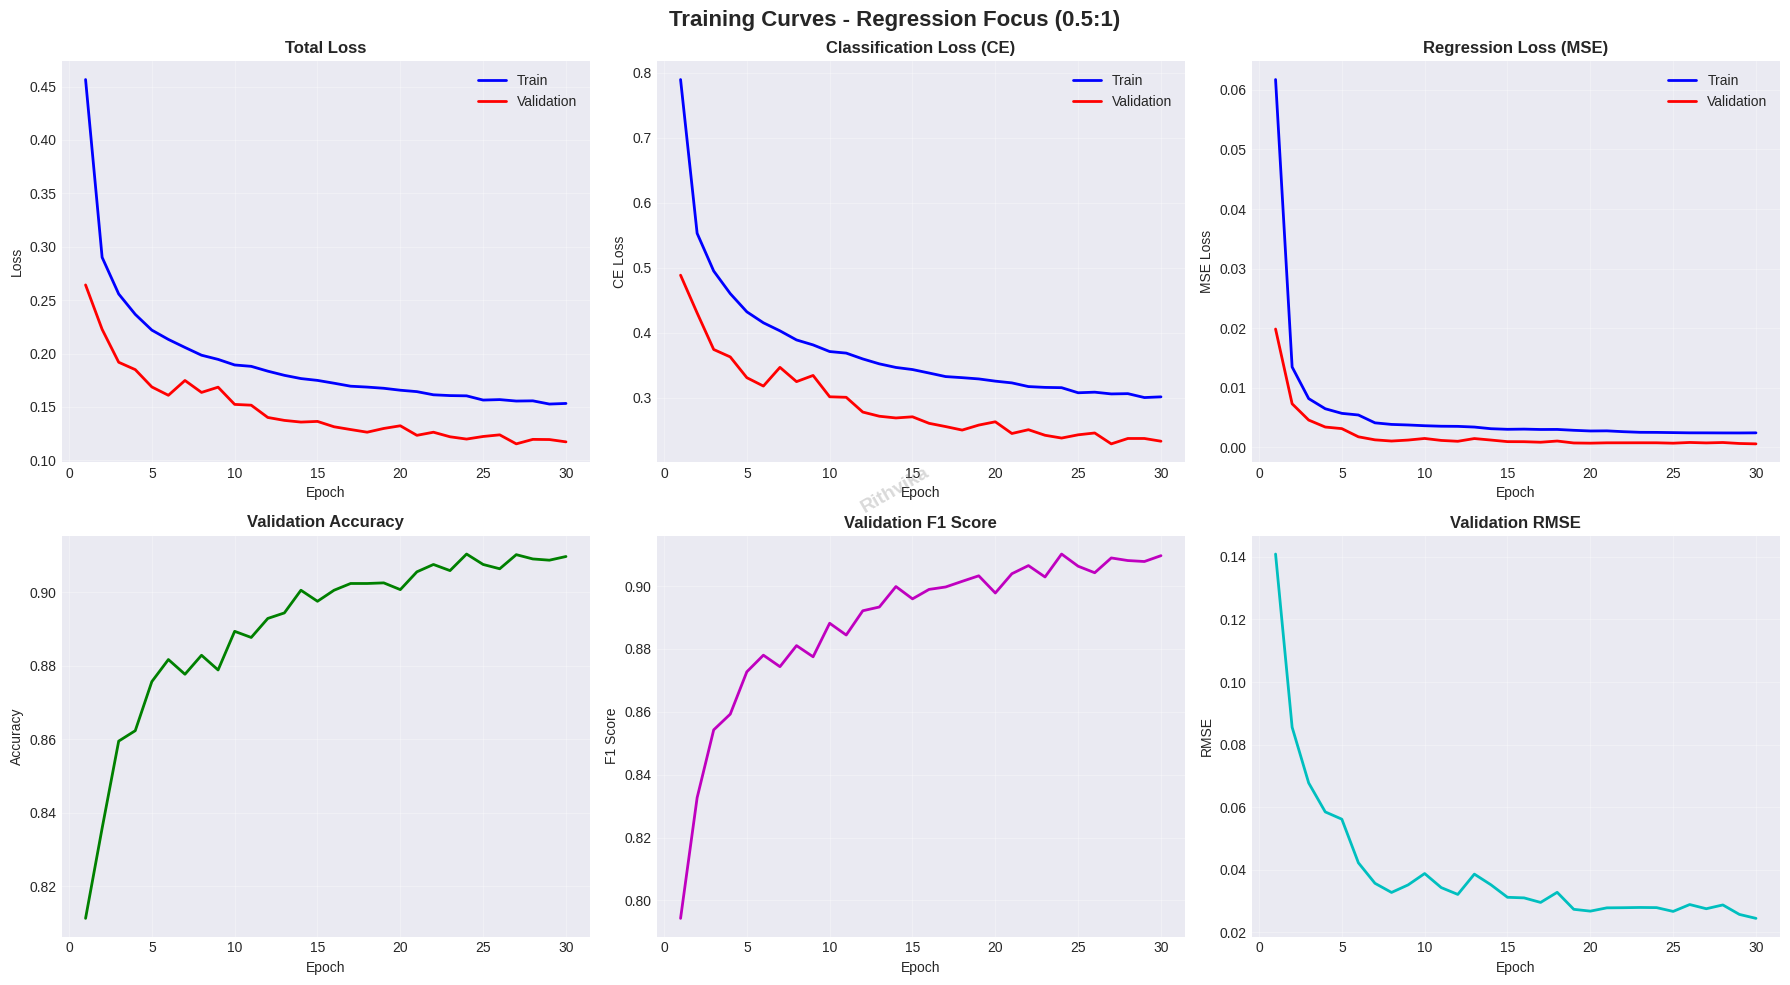


EVALUATING ON TEST SET

✓ Test Results:
  • Accuracy:  0.9146
  • F1 Score:  0.9146
  • MAE:       0.0182
  • RMSE:      0.0242

CONFUSION MATRIX


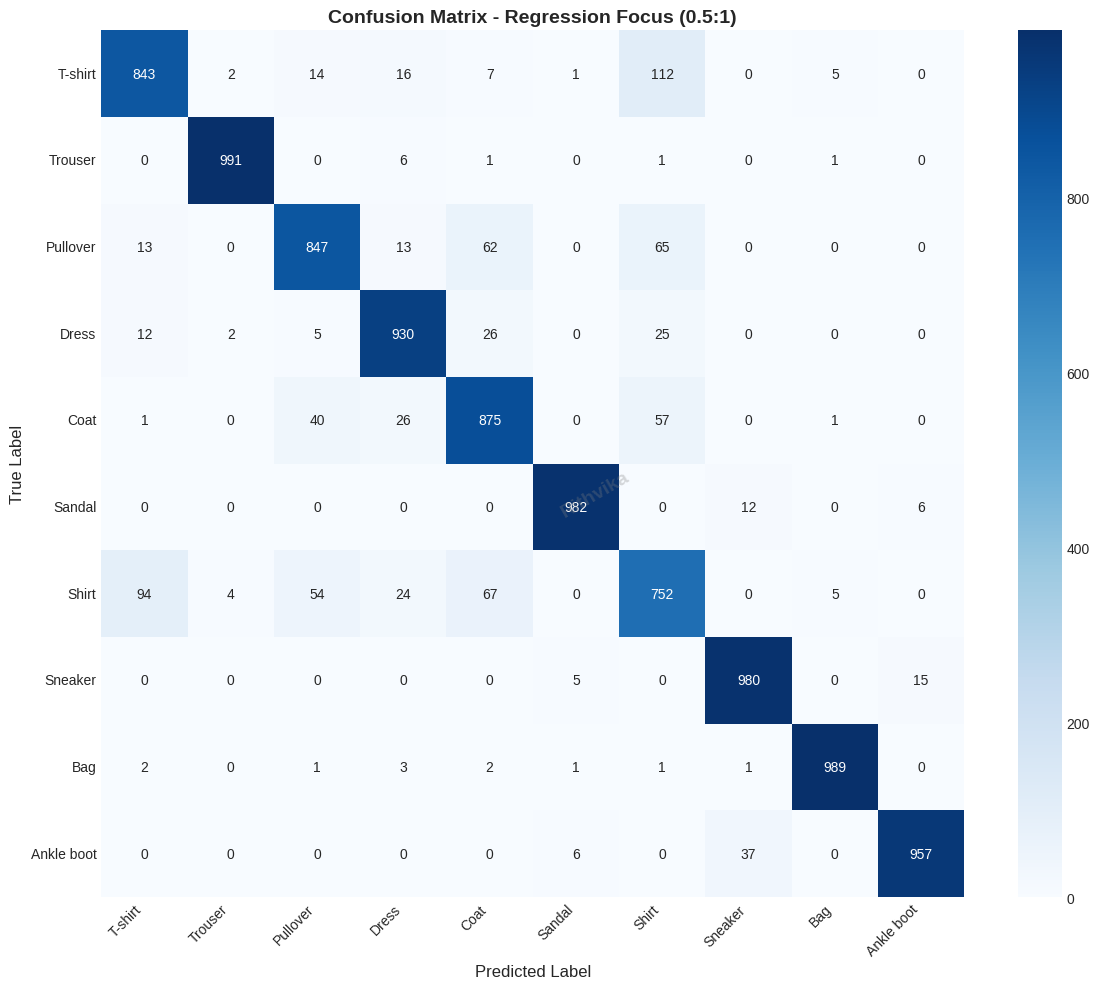


SAMPLE PREDICTIONS


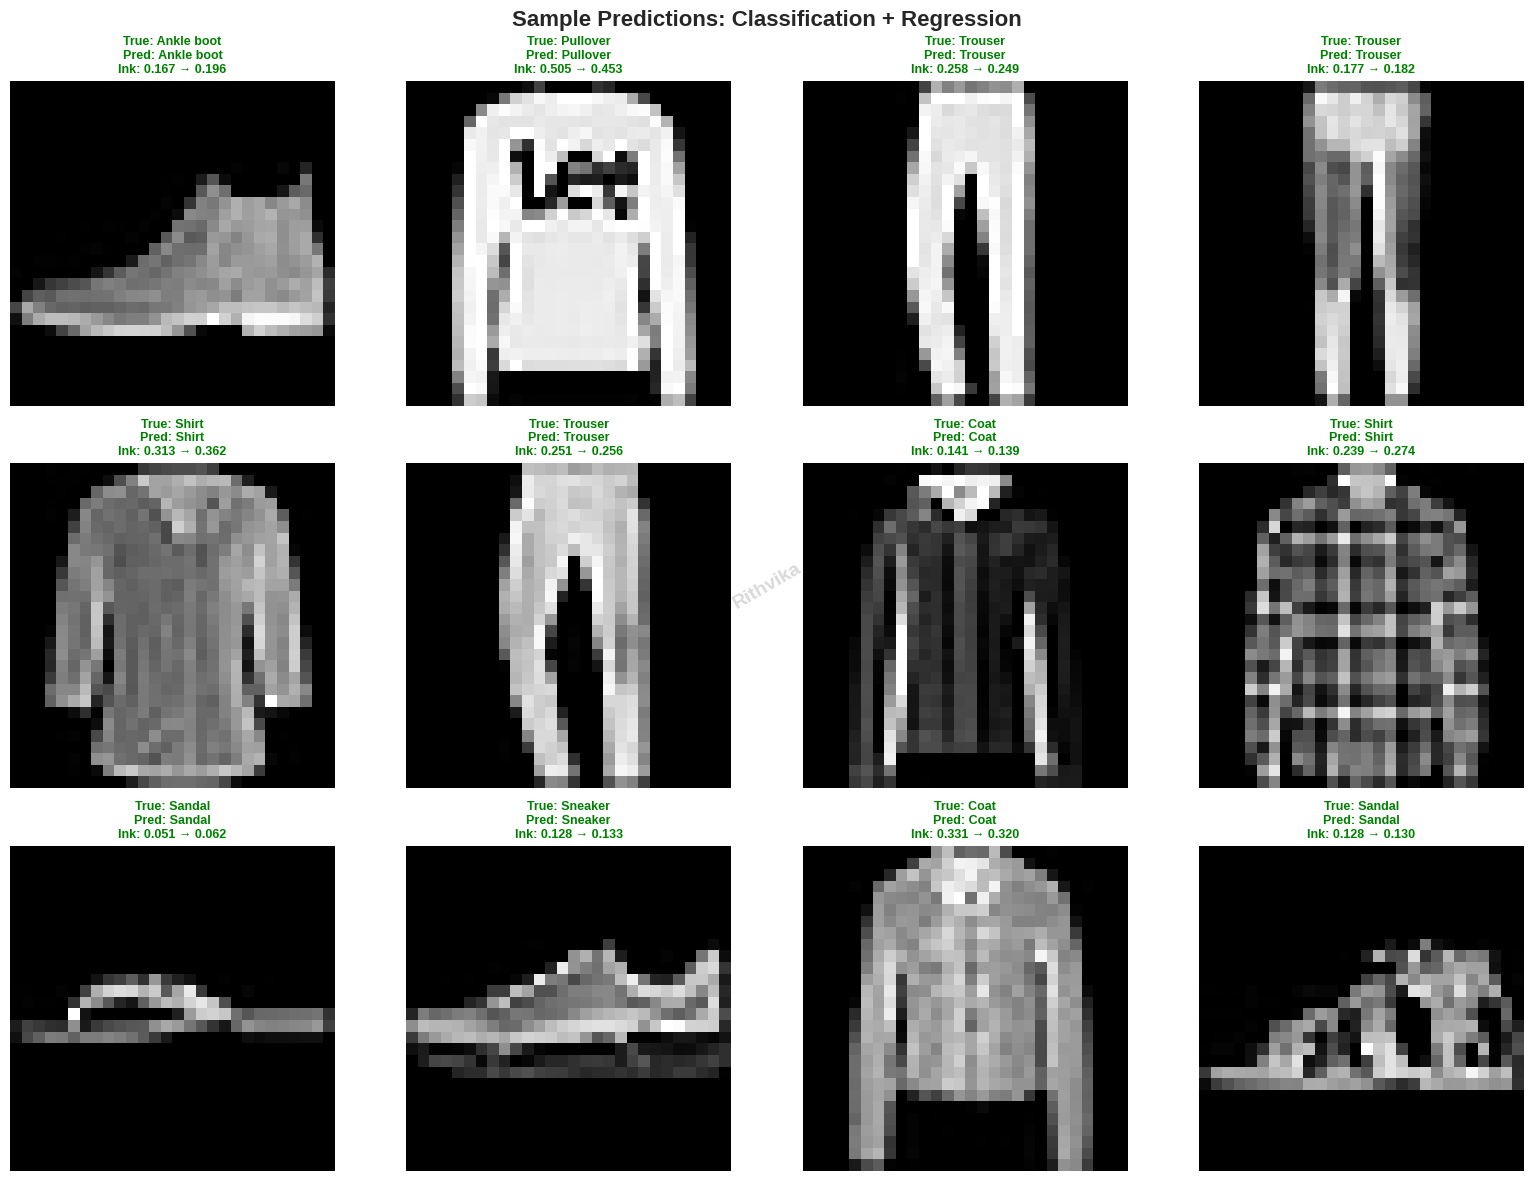


FEATURE MAP VISUALIZATIONS


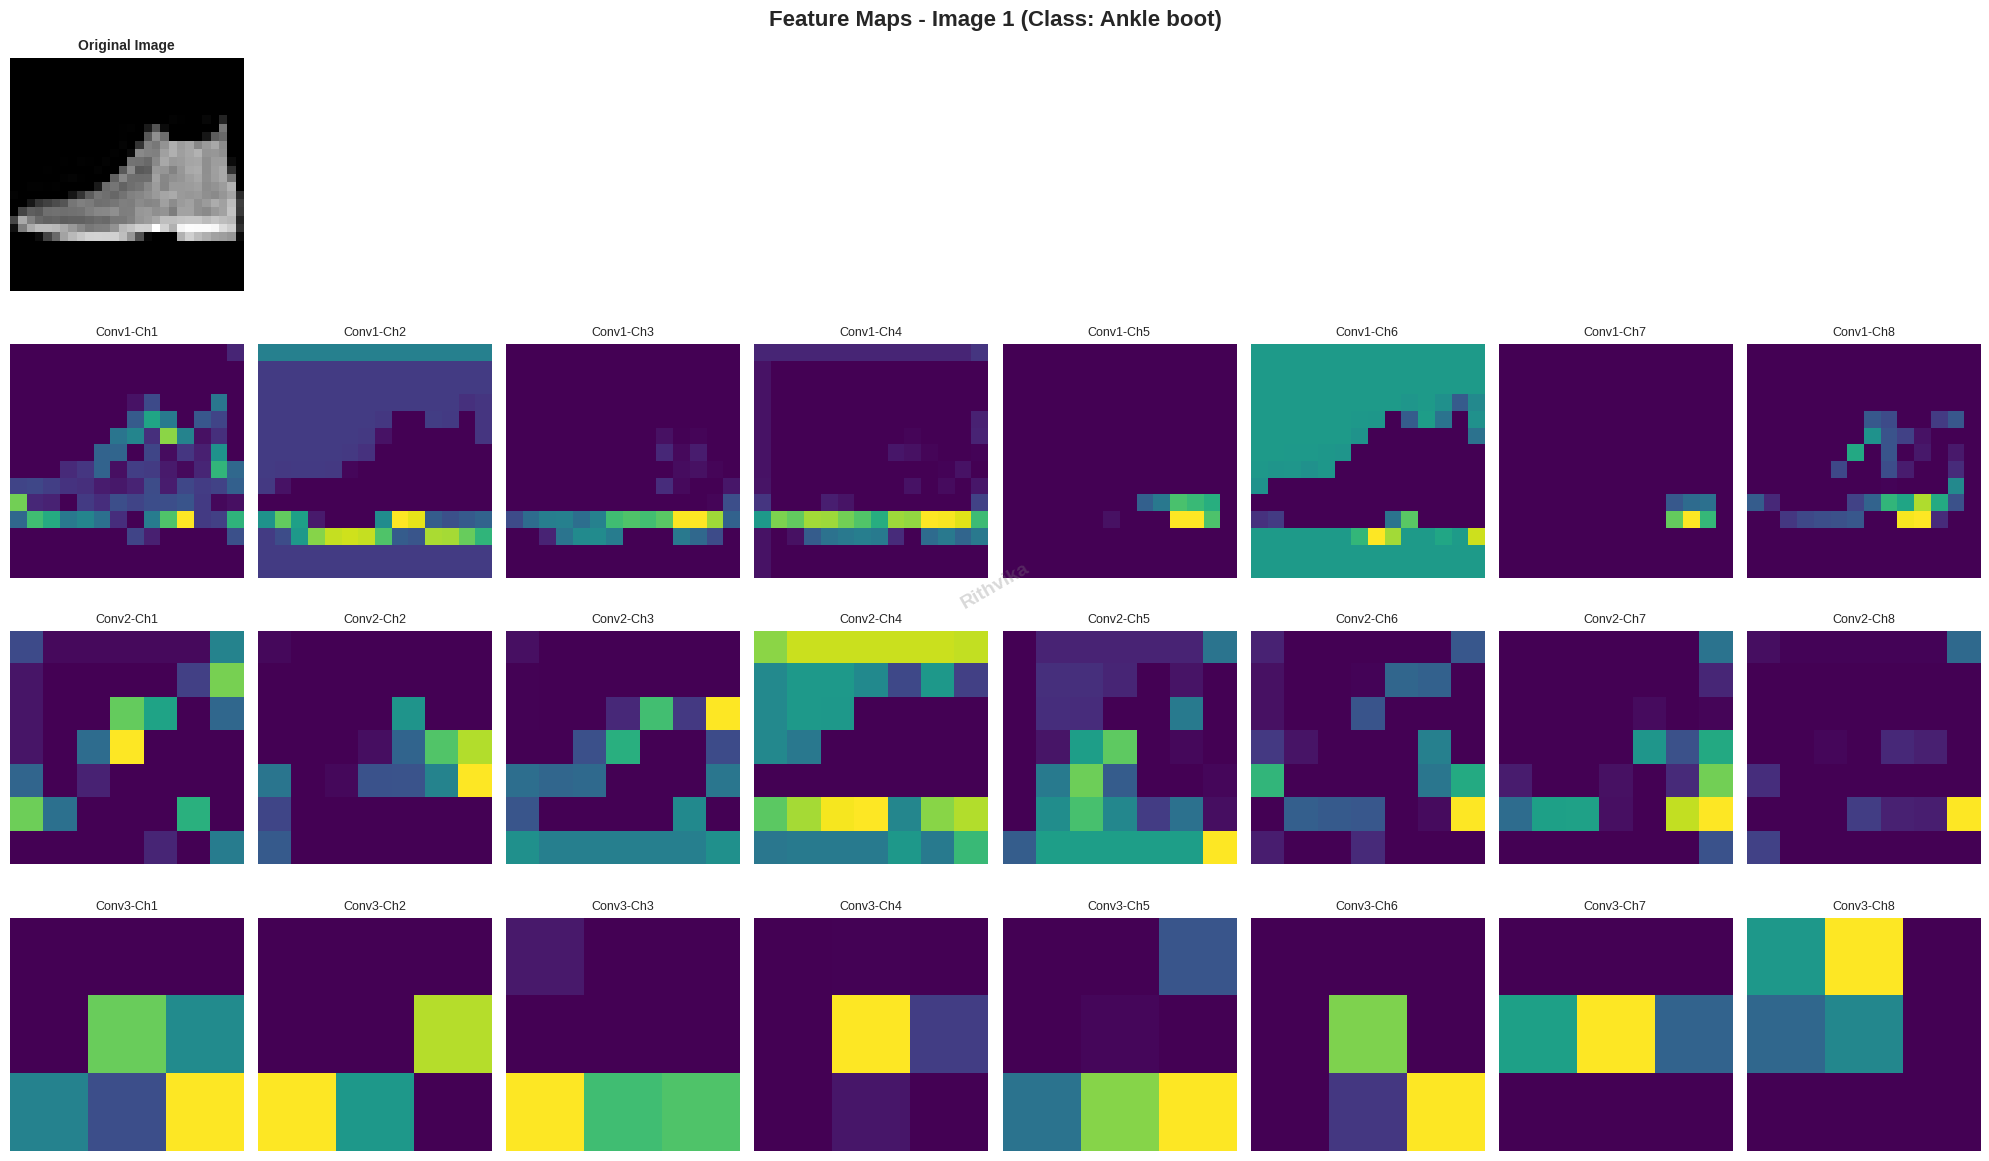

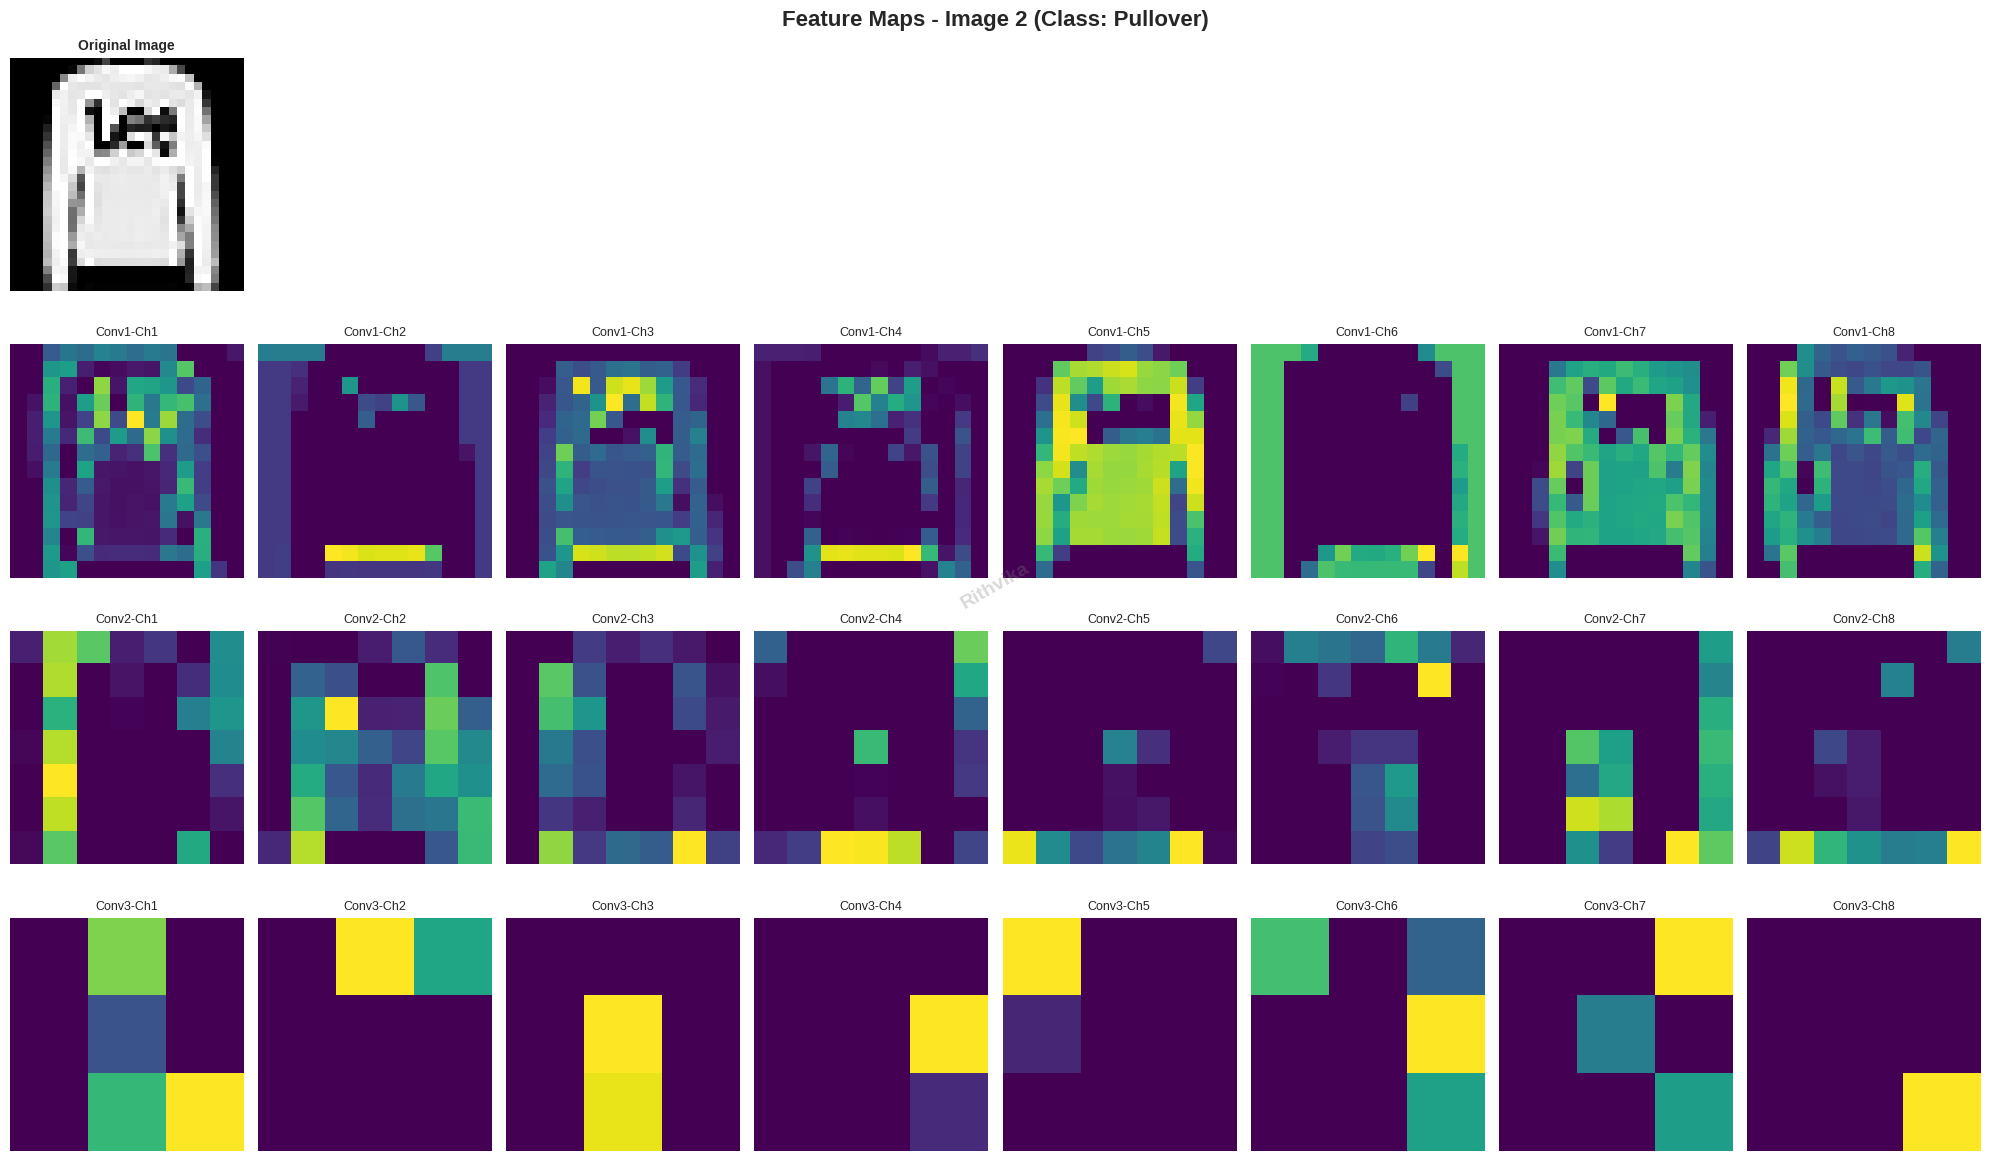

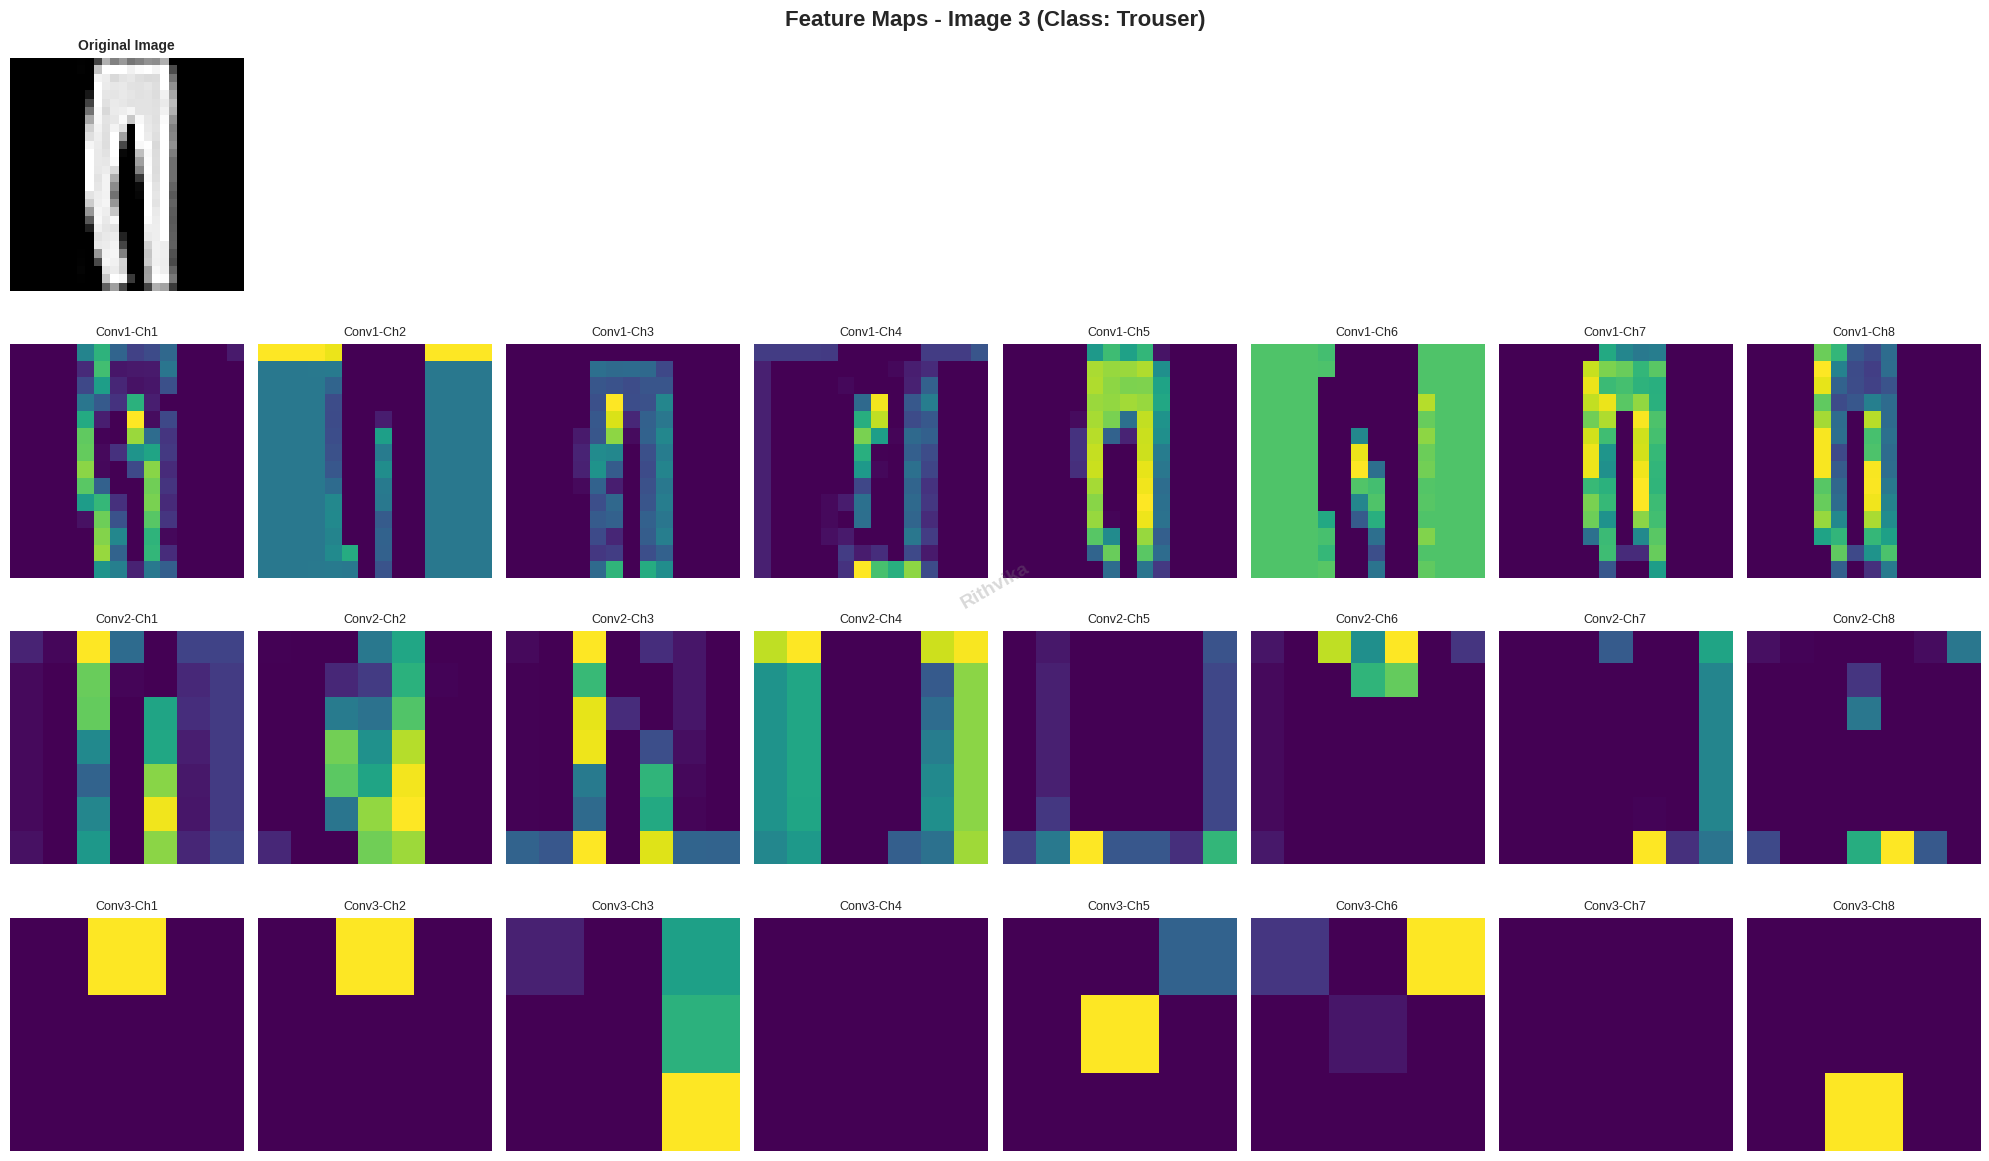


 Feature map visualizations completed and logged to wandb'


epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
test/accuracy,▁
test/f1_score,▁
test/loss,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▅▄▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/loss,█▄▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/mse_loss,█▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
+7,...



✓ Experiment 4 completed!


EXPERIMENT 5/8: Classification Focus(1.5 : 1)
Configuration:
  • Learning Rate: 0.01
  • Optimizer: SGD
  • Dropout: 0.3
  • Batch Size: 64
  • Lambda1 (Classification): 1.5
  • Lambda2 (Regression): 1.0
  • Channels/Filters: [32, 64, 128] (Blocks: 3)
------------------------------------------------------------------------------------------------------------------------



Using device: cuda
Loading data...
Creating model...
Training...
Epoch 1/30 - Train Loss: 1.1345, Val Loss: 0.7991, Val Acc: 0.8023, Val RMSE: 0.0435
Epoch 2/30 - Train Loss: 0.8322, Val Loss: 0.7301, Val Acc: 0.8255, Val RMSE: 0.0430
Epoch 3/30 - Train Loss: 0.7438, Val Loss: 0.5615, Val Acc: 0.8638, Val RMSE: 0.0422
Epoch 4/30 - Train Loss: 0.6943, Val Loss: 0.5271, Val Acc: 0.8715, Val RMSE: 0.0375
Epoch 5/30 - Train Loss: 0.6587, Val Loss: 0.5030, Val Acc: 0.8772, Val RMSE: 0.0334
Epoch 6/30 - Train Loss: 0.6227, Val Loss: 0.4850, Val Acc: 0.8817, Val RMSE: 0.0324
Epoch 7/30 - Train Loss: 0.6082, Val Loss: 0.4689, Val Acc: 0.8847, Val RMSE: 0.0371
Epoch 8/30 - Train Loss: 0.5909, Val Loss: 0.4524, Val Acc: 0.8872, Val RMSE: 0.0362
Epoch 9/30 - Train Loss: 0.5781, Val Loss: 0.4597, Val Acc: 0.8860, Val RMSE: 0.0299
Epoch 10/30 - Train Loss: 0.5641, Val Loss: 0.4379, Val Acc: 0.8933, Val RMSE: 0.0379
Epoch 11/30 - Train Loss: 0.5516, Val Loss: 0.4437, Val Acc: 0.8880, Val RMSE: 0.036

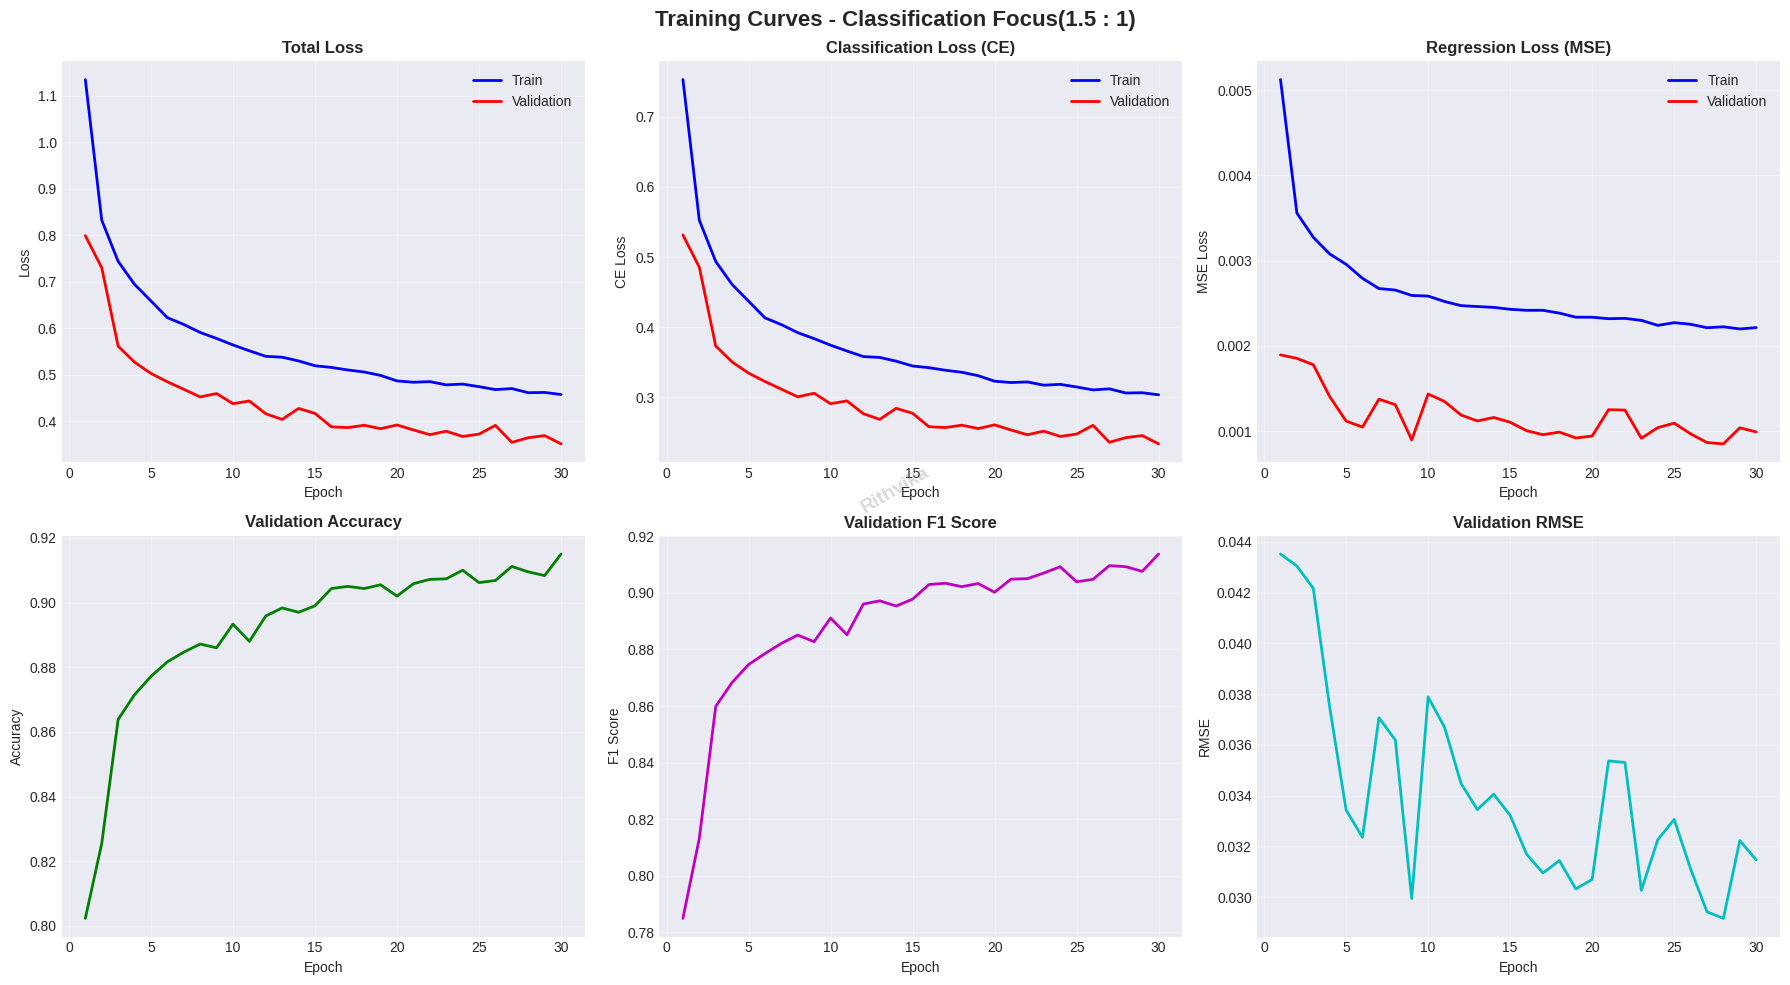


EVALUATING ON TEST SET

✓ Test Results:
  • Accuracy:  0.9136
  • F1 Score:  0.9127
  • MAE:       0.0238
  • RMSE:      0.0307

CONFUSION MATRIX


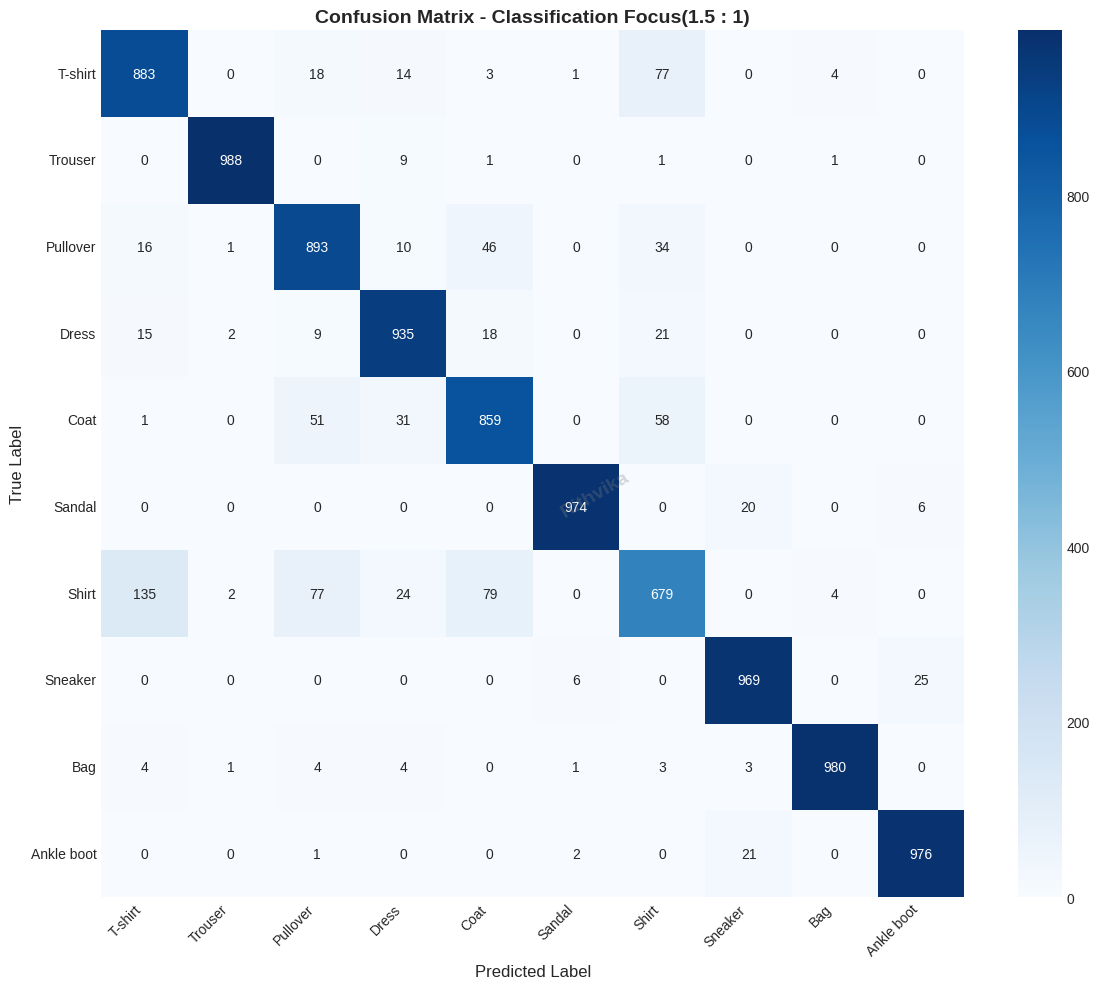


SAMPLE PREDICTIONS


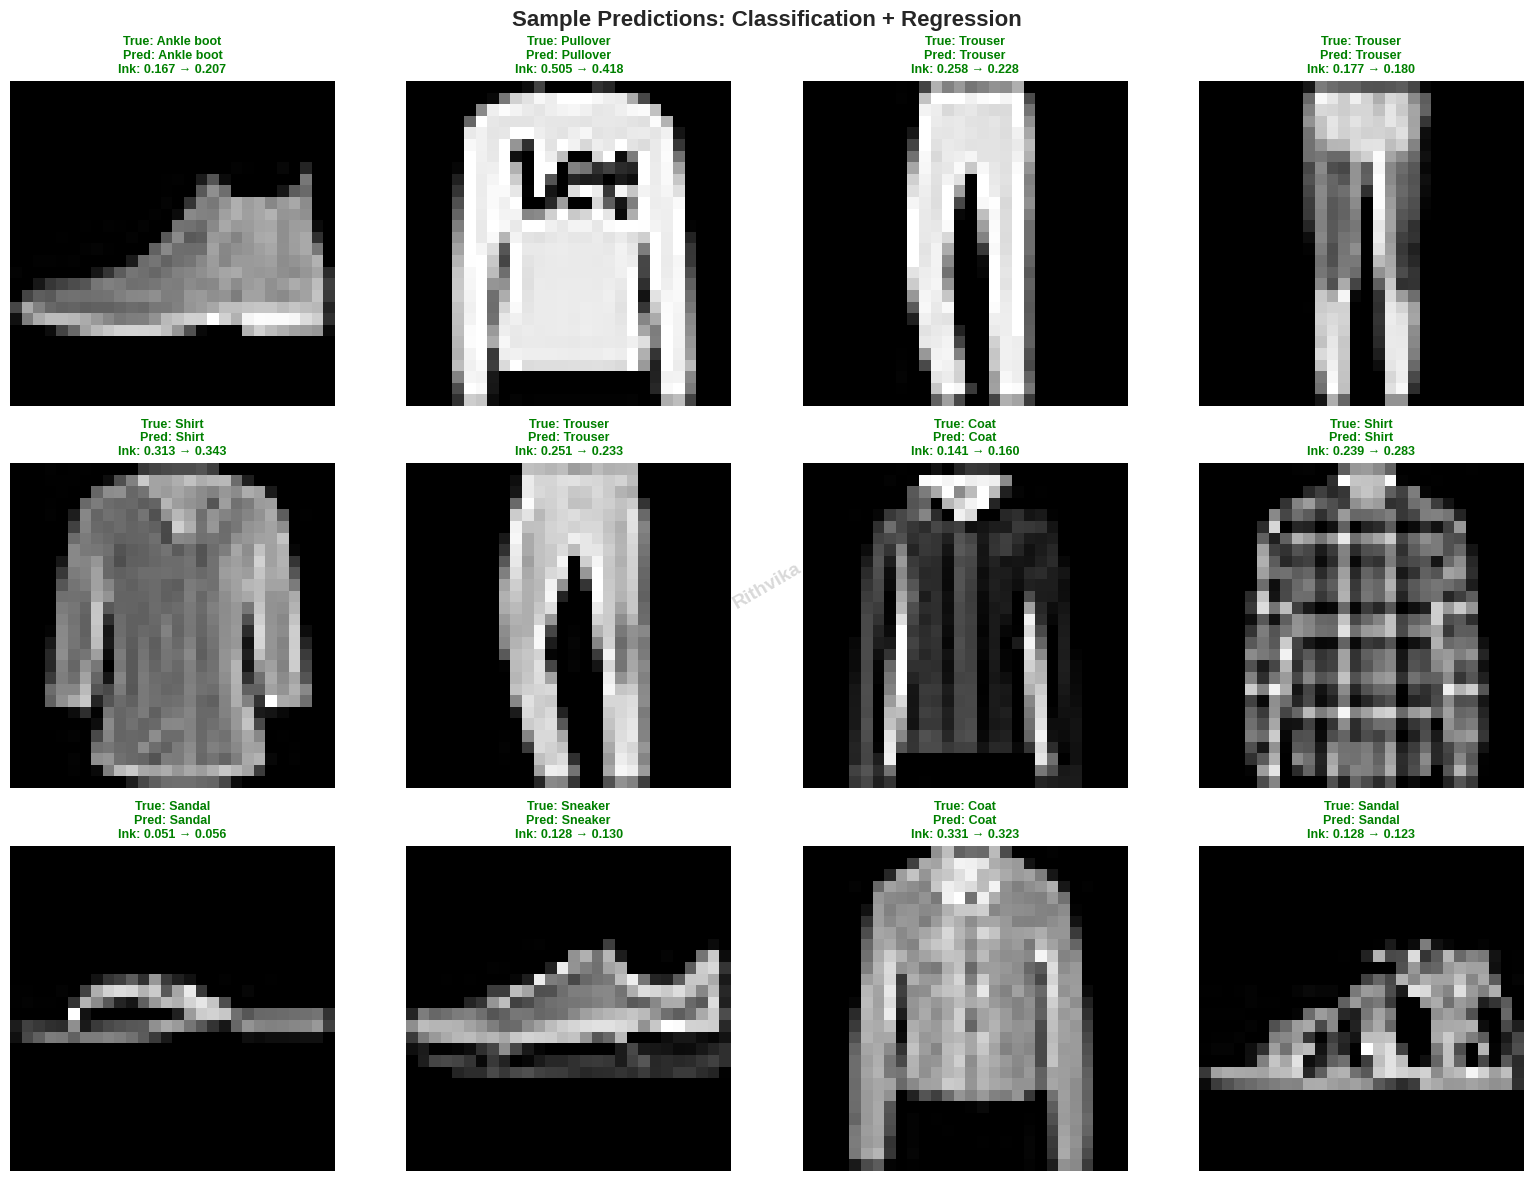


FEATURE MAP VISUALIZATIONS


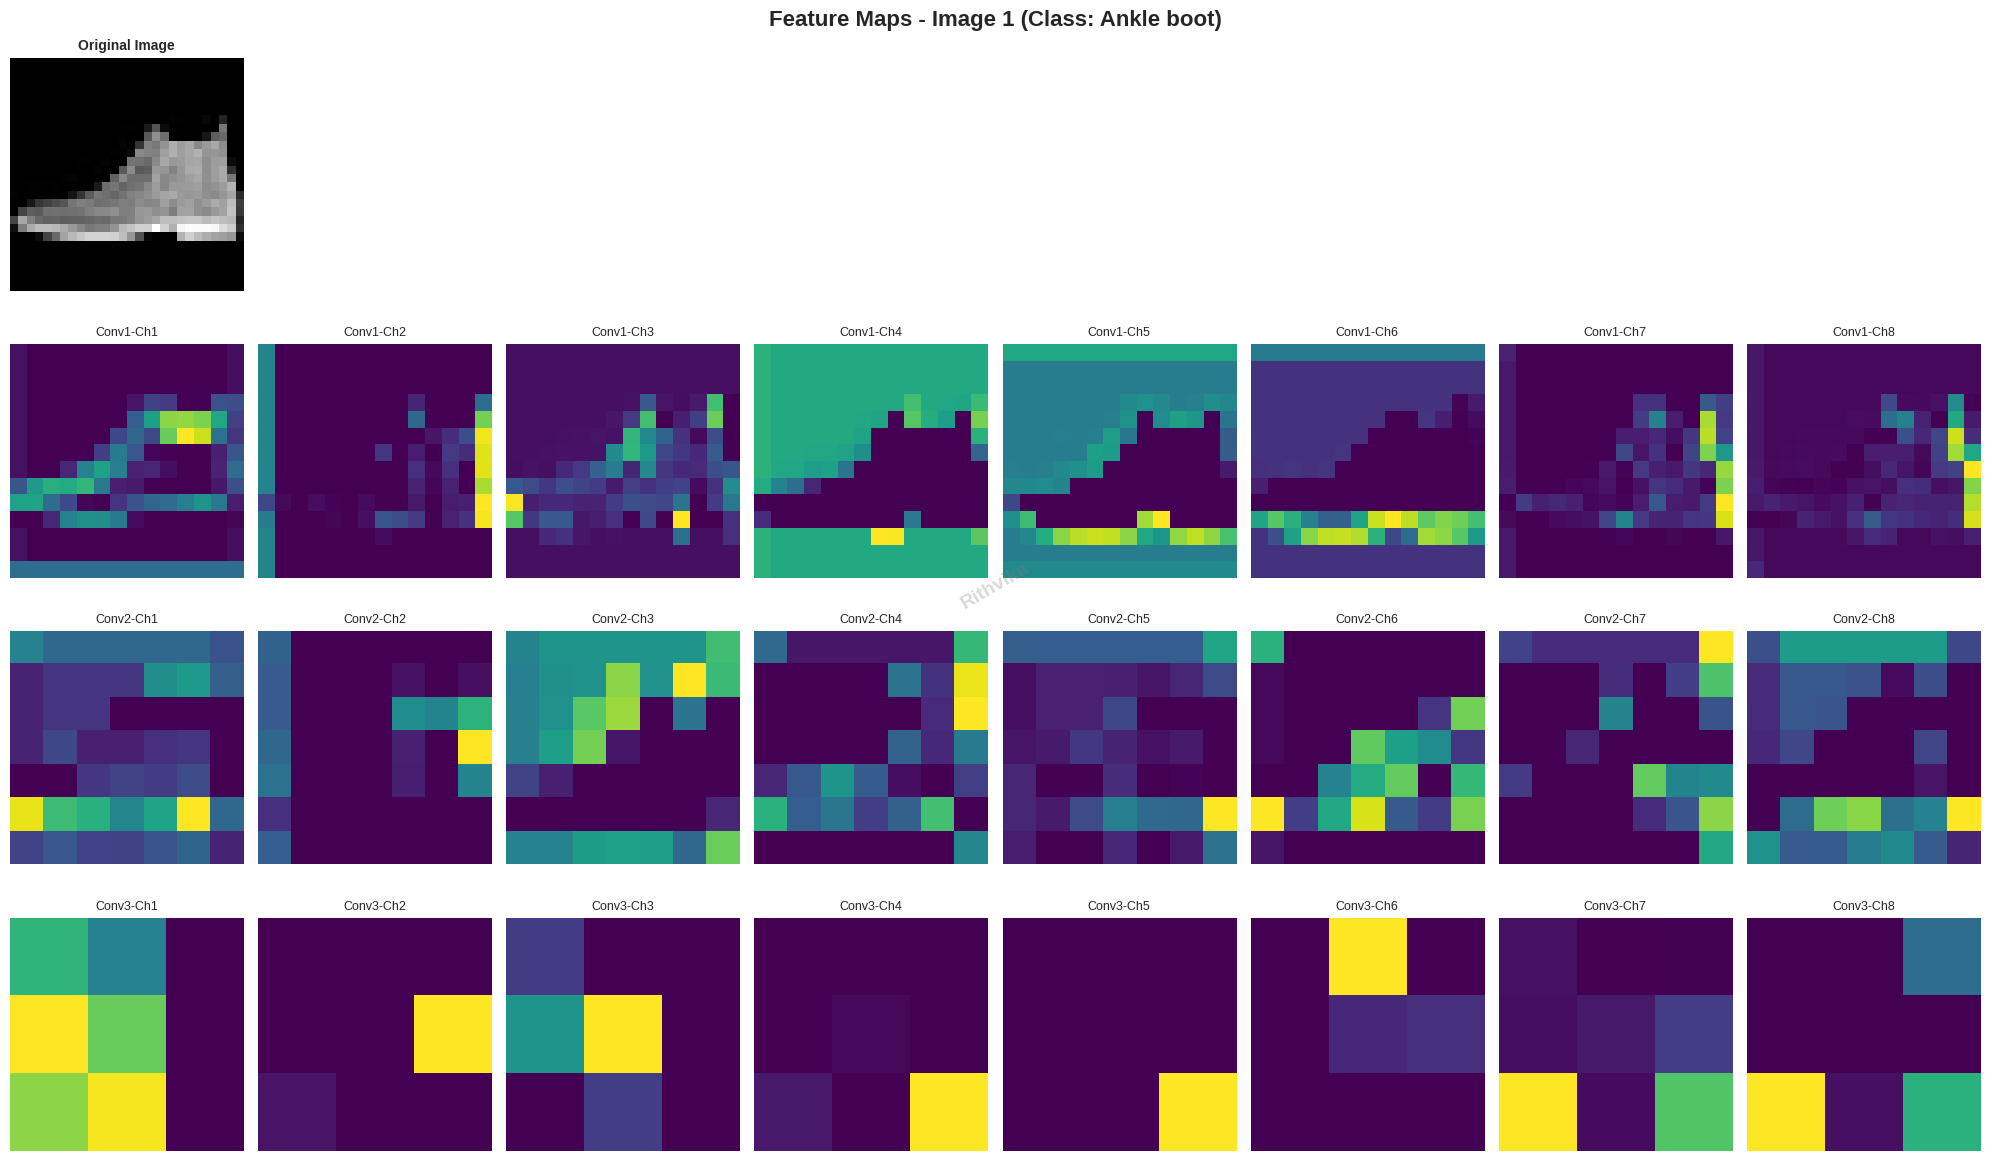

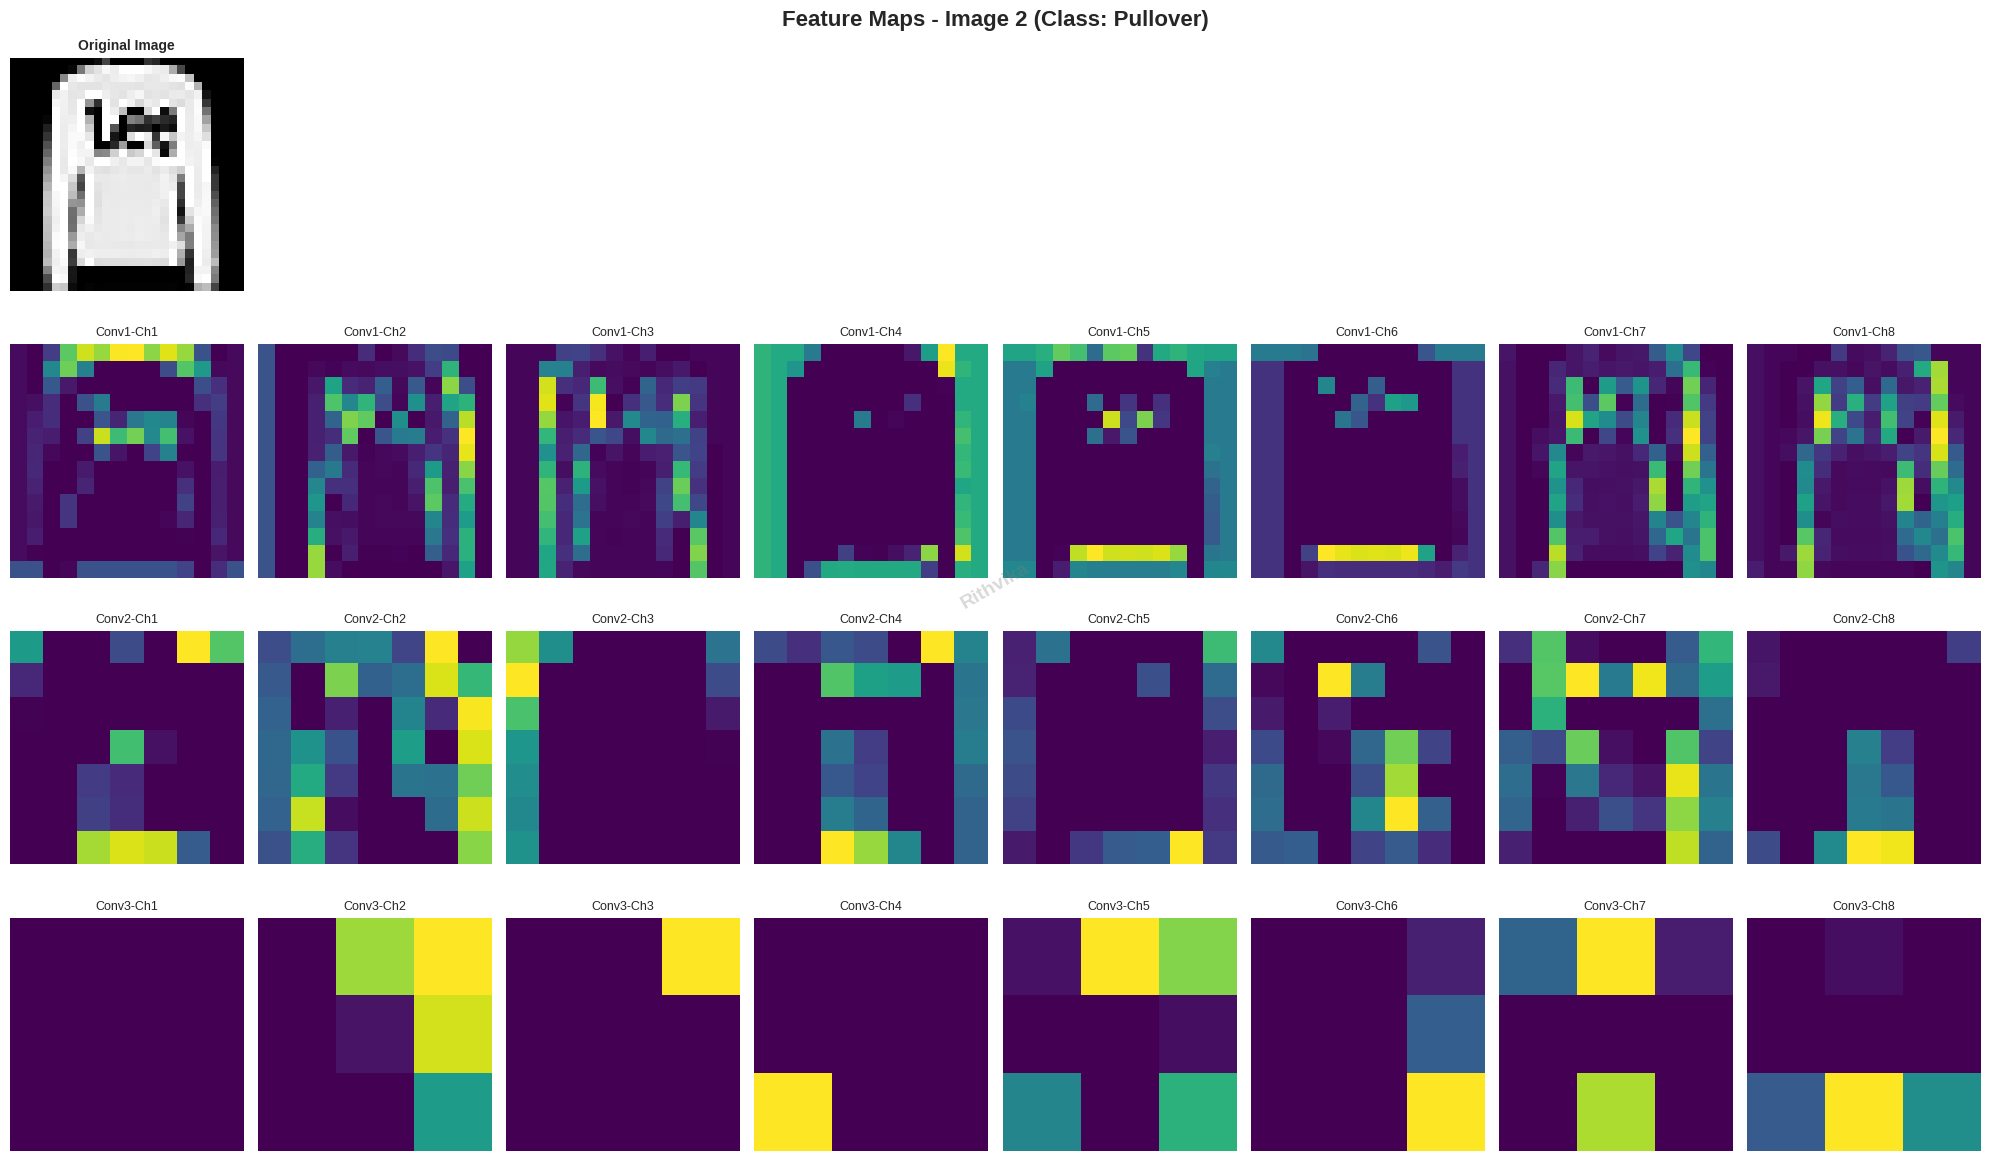

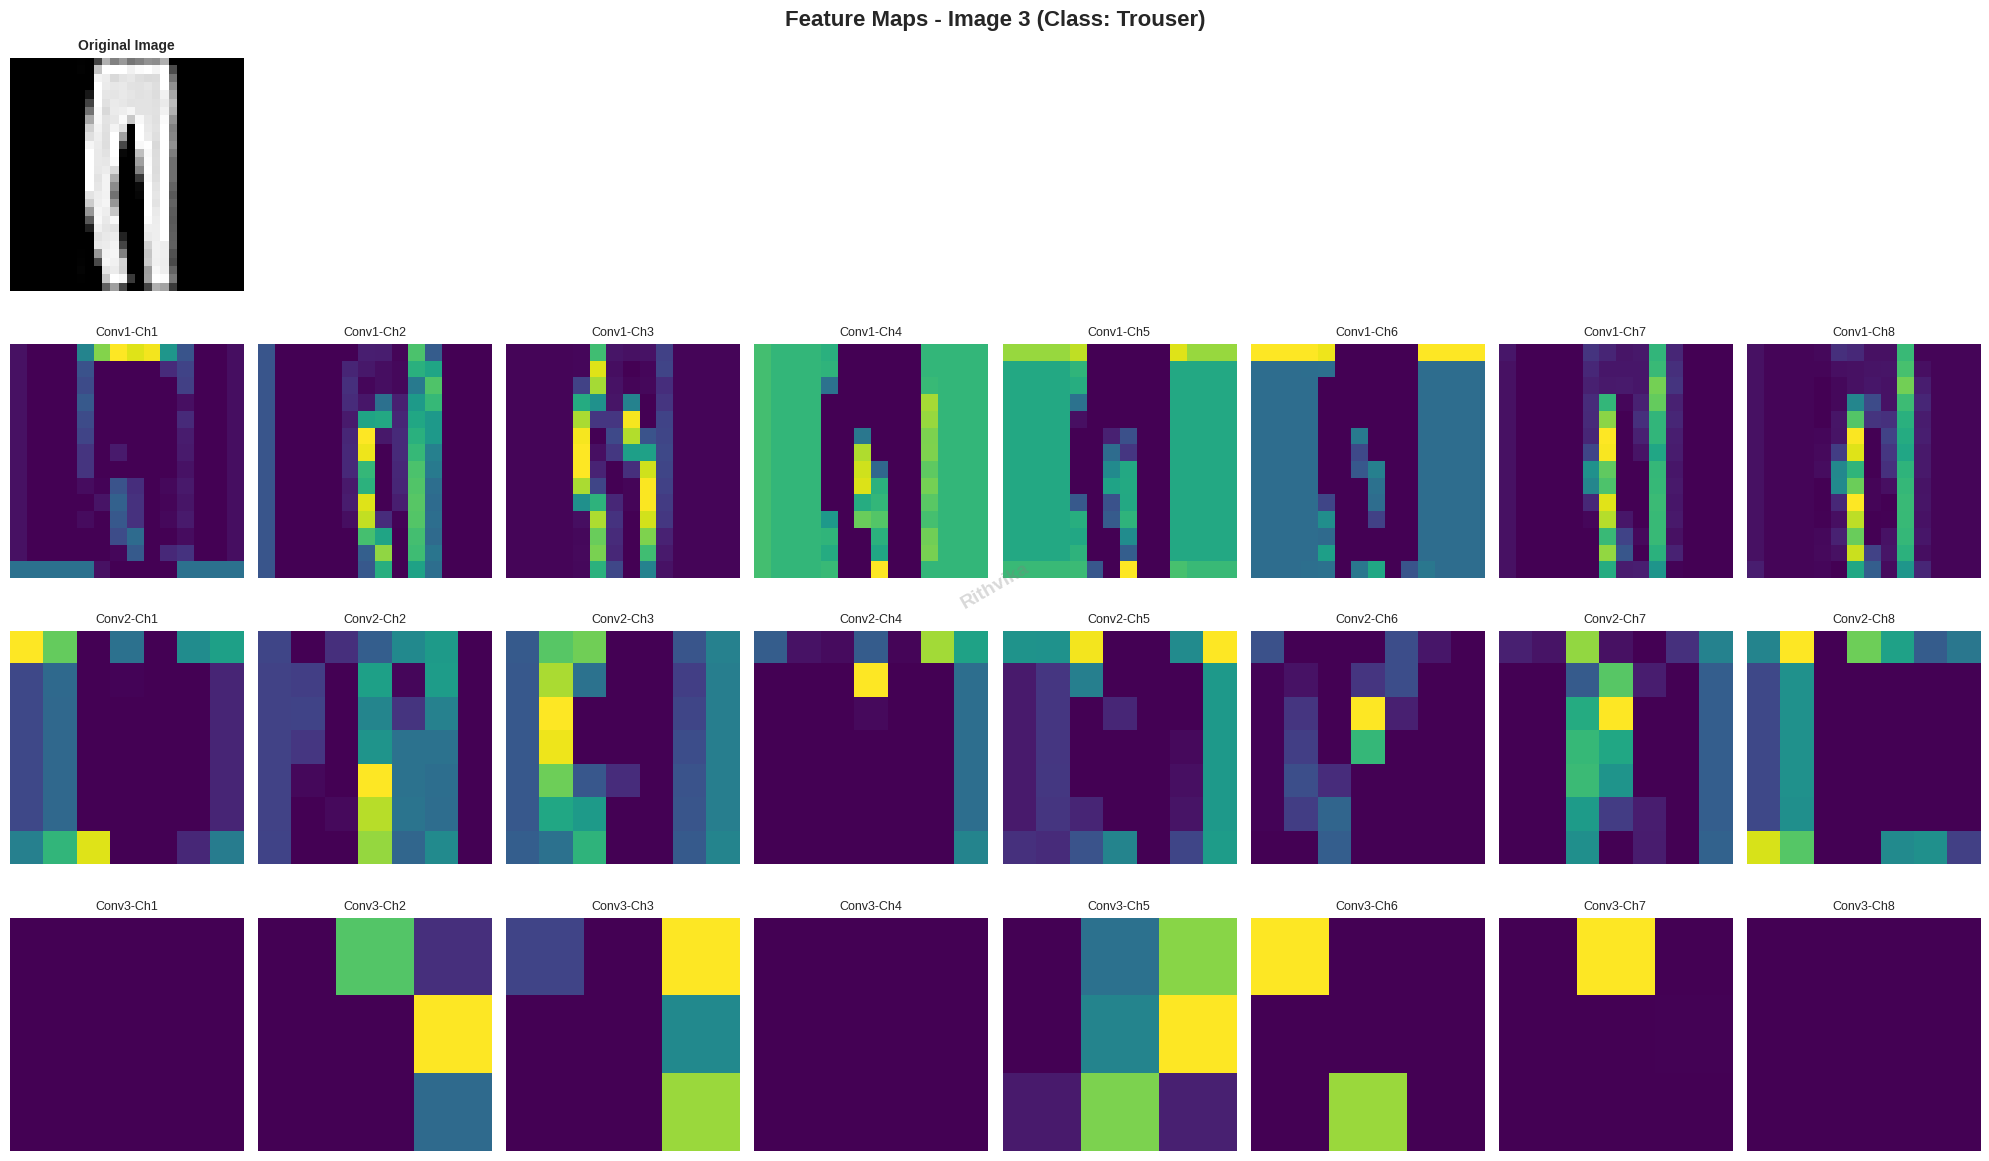


 Feature map visualizations completed and logged to wandb'


epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
test/accuracy,▁
test/f1_score,▁
test/loss,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▅▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
train/loss,█▅▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
train/mse_loss,█▄▄▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
+7,...



✓ Experiment 5 completed!


EXPERIMENT 6/8: High Regularization (1 : 1.5)
Configuration:
  • Learning Rate: 0.0005
  • Optimizer: AdamW
  • Dropout: 0.3
  • Batch Size: 32
  • Lambda1 (Classification): 1.0
  • Lambda2 (Regression): 1.5
  • Channels/Filters: [32, 64, 128] (Blocks: 3)
------------------------------------------------------------------------------------------------------------------------



Using device: cuda
Loading data...
Creating model...
Training...
Epoch 1/30 - Train Loss: 0.7204, Val Loss: 0.4649, Val Acc: 0.8280, Val RMSE: 0.0324
Epoch 2/30 - Train Loss: 0.5195, Val Loss: 0.4015, Val Acc: 0.8542, Val RMSE: 0.0371
Epoch 3/30 - Train Loss: 0.4744, Val Loss: 0.3534, Val Acc: 0.8735, Val RMSE: 0.0338
Epoch 4/30 - Train Loss: 0.4399, Val Loss: 0.3380, Val Acc: 0.8758, Val RMSE: 0.0335
Epoch 5/30 - Train Loss: 0.4198, Val Loss: 0.3252, Val Acc: 0.8780, Val RMSE: 0.0357
Epoch 6/30 - Train Loss: 0.4047, Val Loss: 0.3145, Val Acc: 0.8818, Val RMSE: 0.0395
Epoch 7/30 - Train Loss: 0.3917, Val Loss: 0.2983, Val Acc: 0.8895, Val RMSE: 0.0320
Epoch 8/30 - Train Loss: 0.3790, Val Loss: 0.3066, Val Acc: 0.8875, Val RMSE: 0.0316
Epoch 9/30 - Train Loss: 0.3704, Val Loss: 0.3121, Val Acc: 0.8835, Val RMSE: 0.0306
Epoch 10/30 - Train Loss: 0.3677, Val Loss: 0.2850, Val Acc: 0.8938, Val RMSE: 0.0298
Epoch 11/30 - Train Loss: 0.3583, Val Loss: 0.2833, Val Acc: 0.8967, Val RMSE: 0.030

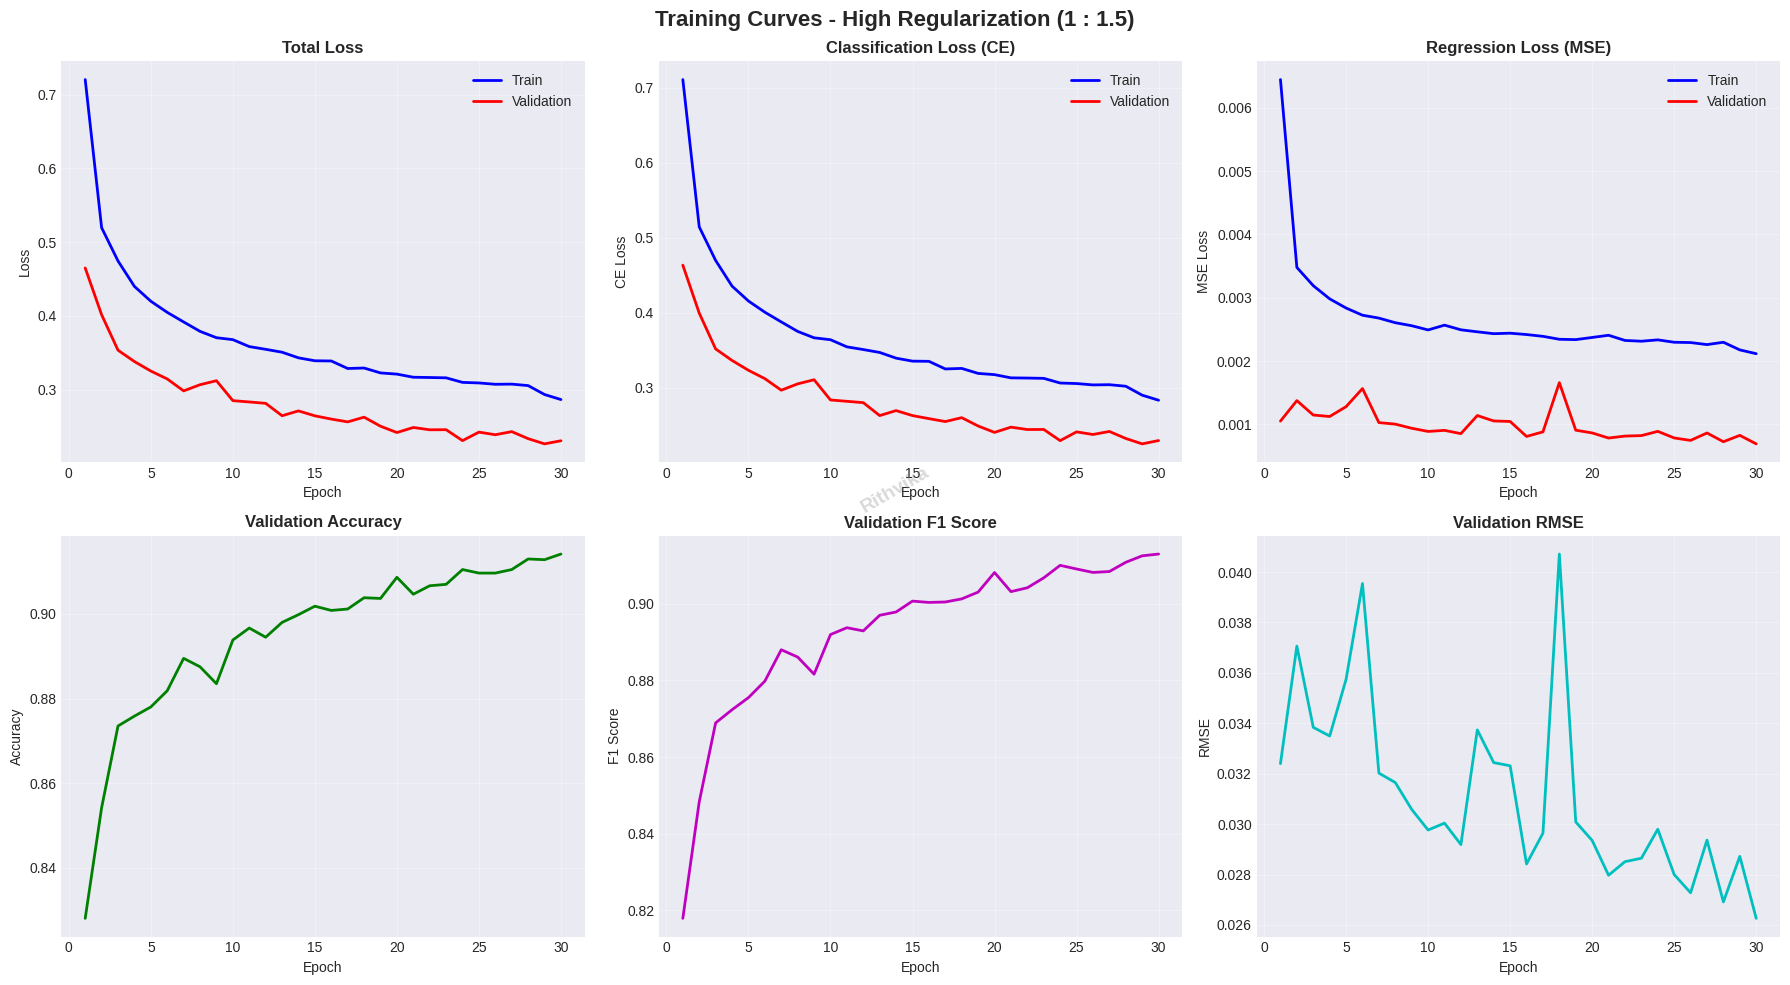


EVALUATING ON TEST SET

✓ Test Results:
  • Accuracy:  0.9130
  • F1 Score:  0.9123
  • MAE:       0.0193
  • RMSE:      0.0260

CONFUSION MATRIX


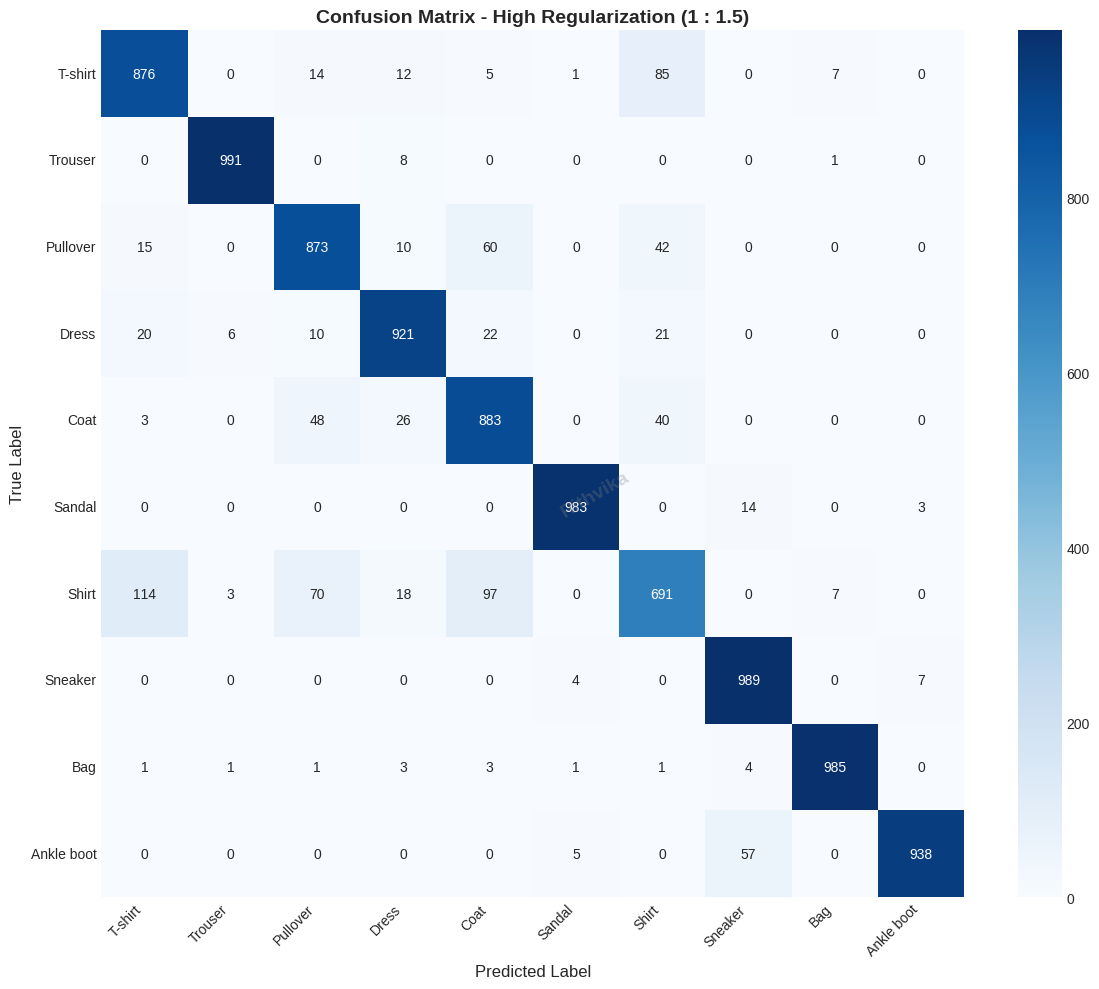


SAMPLE PREDICTIONS


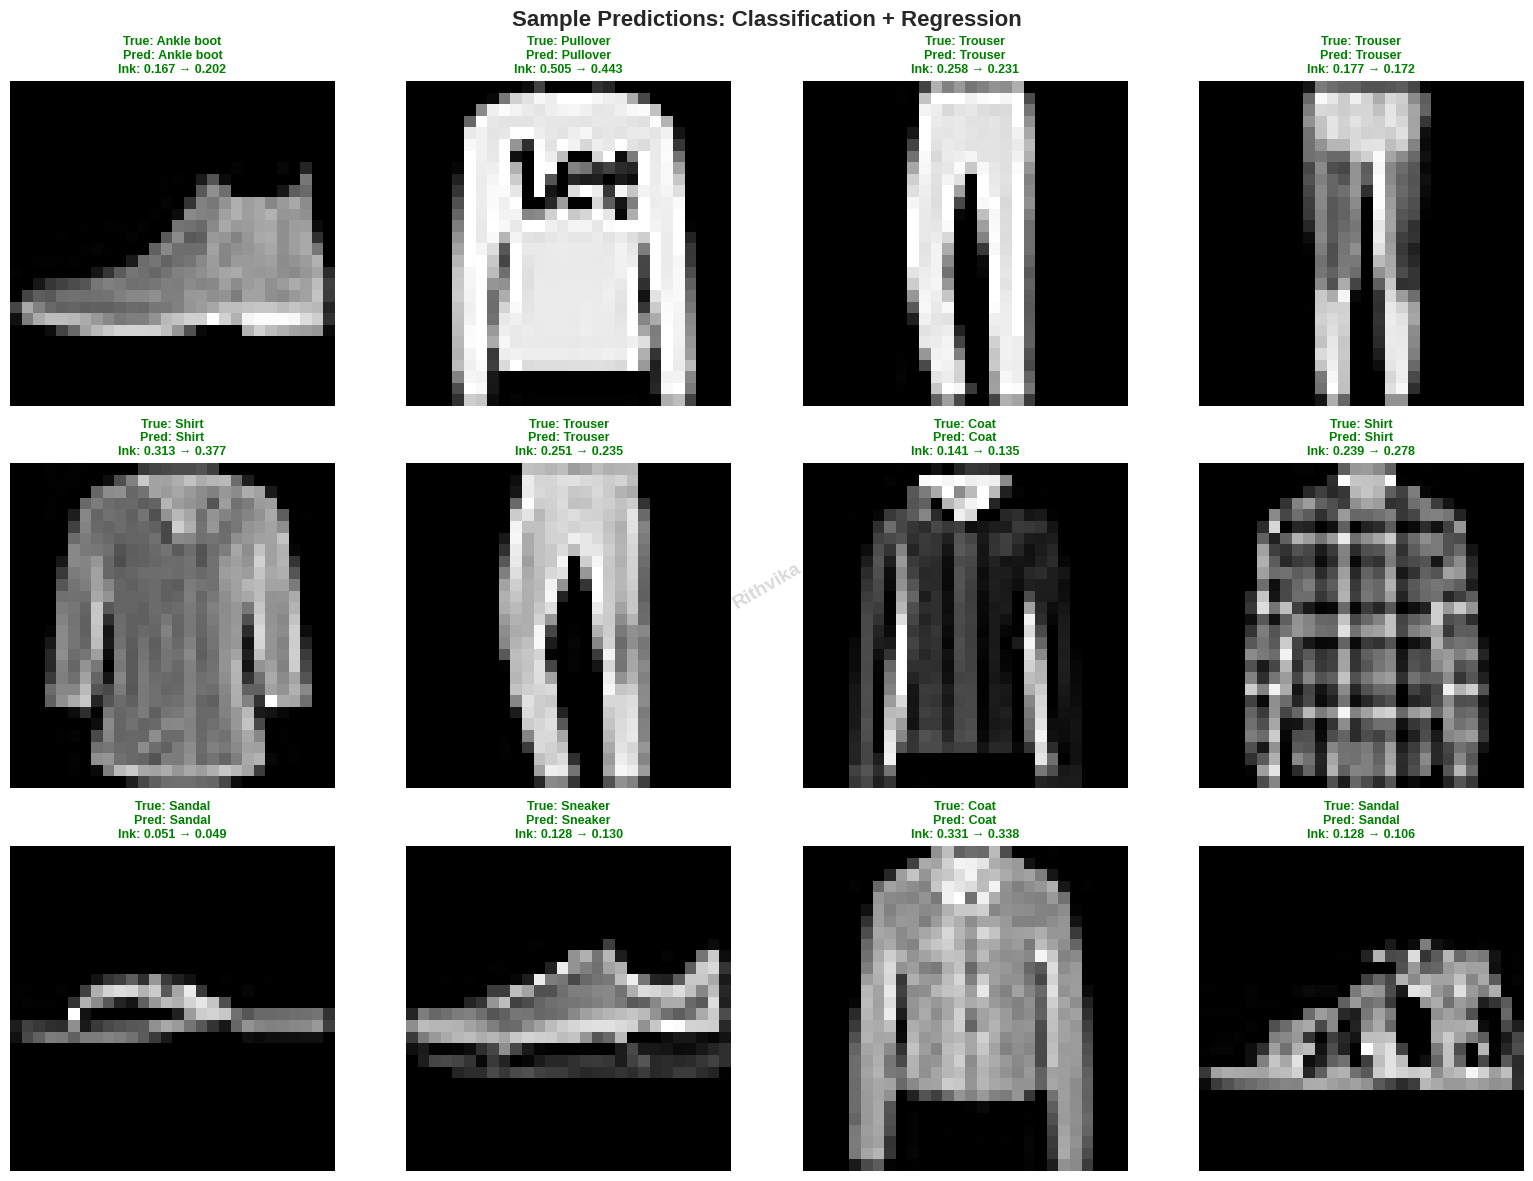


FEATURE MAP VISUALIZATIONS


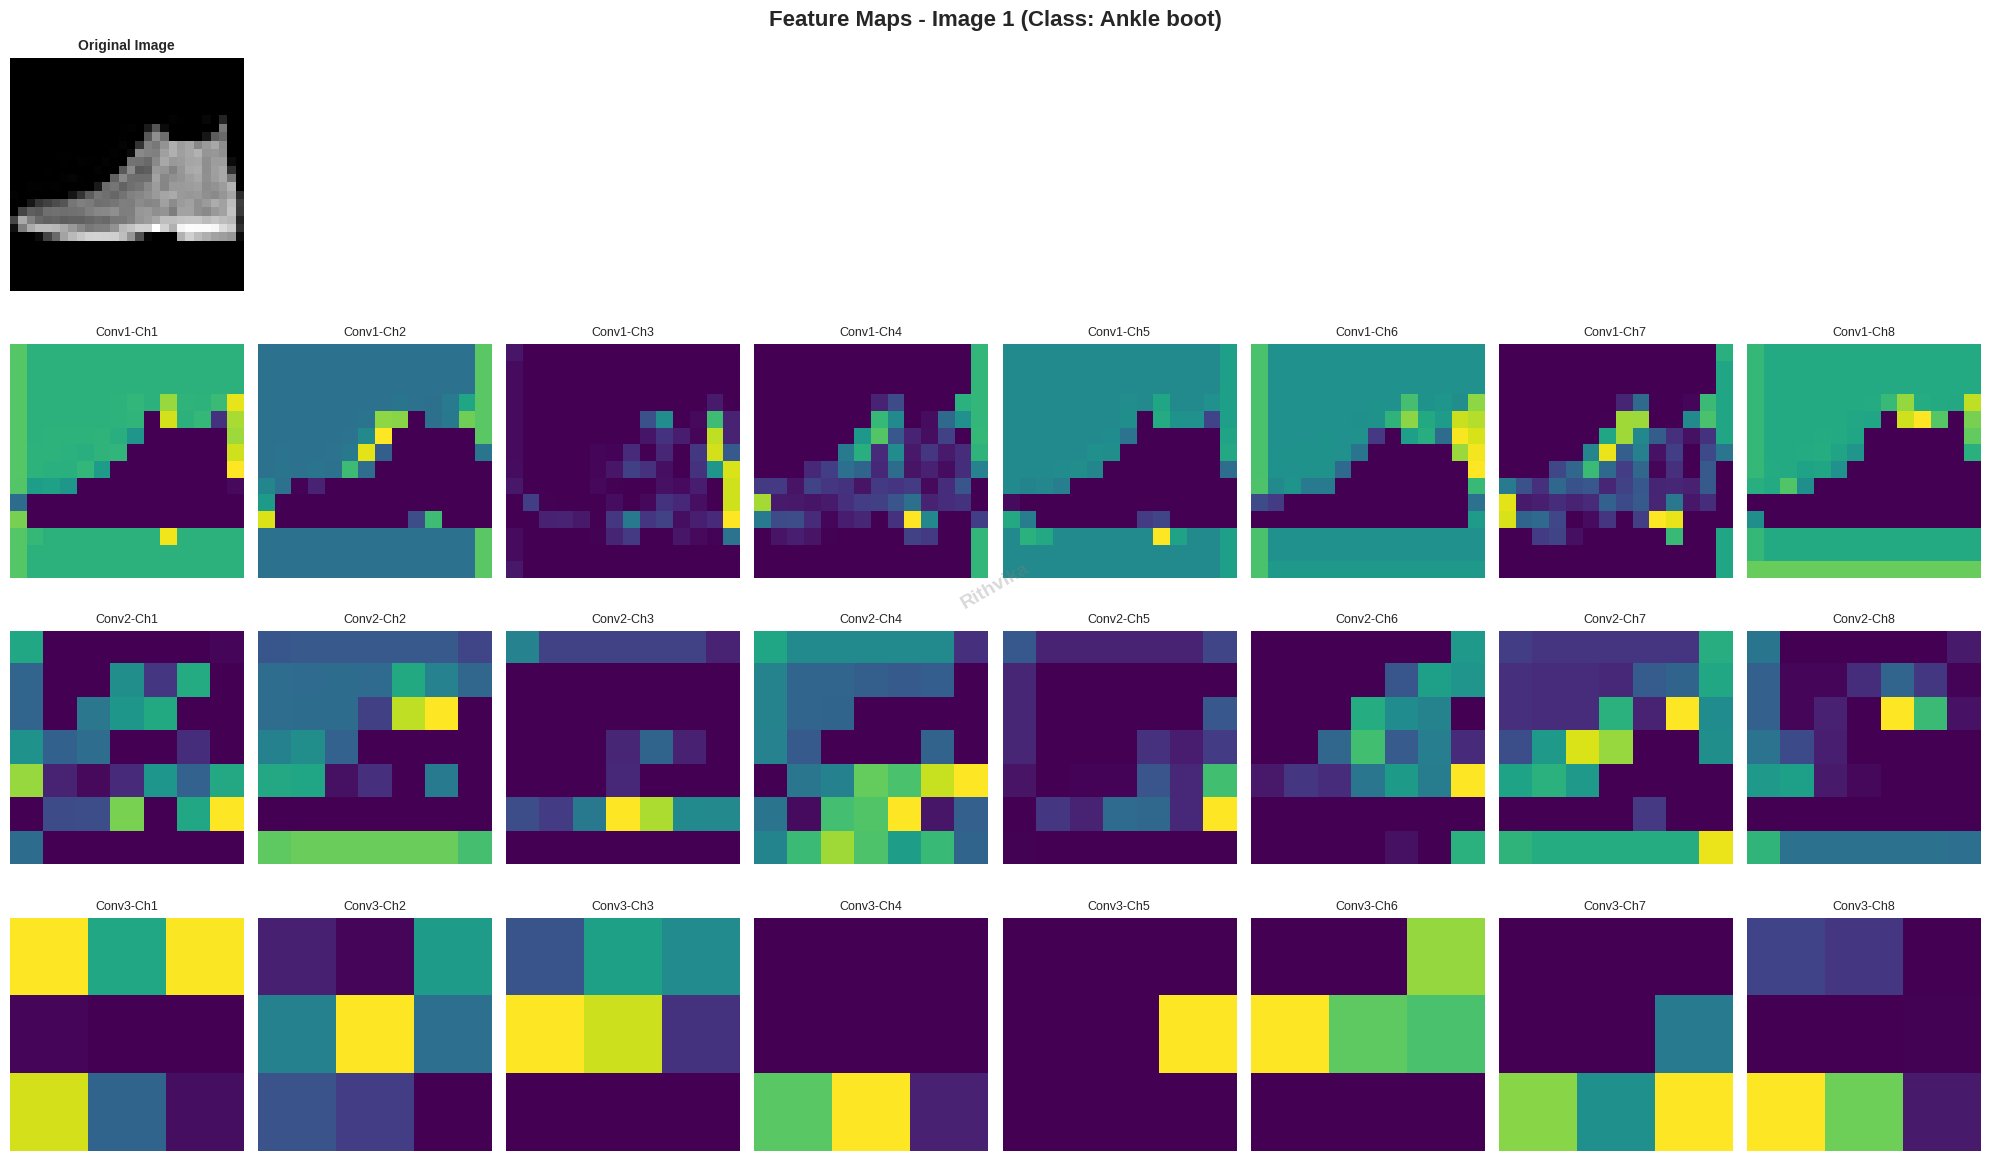

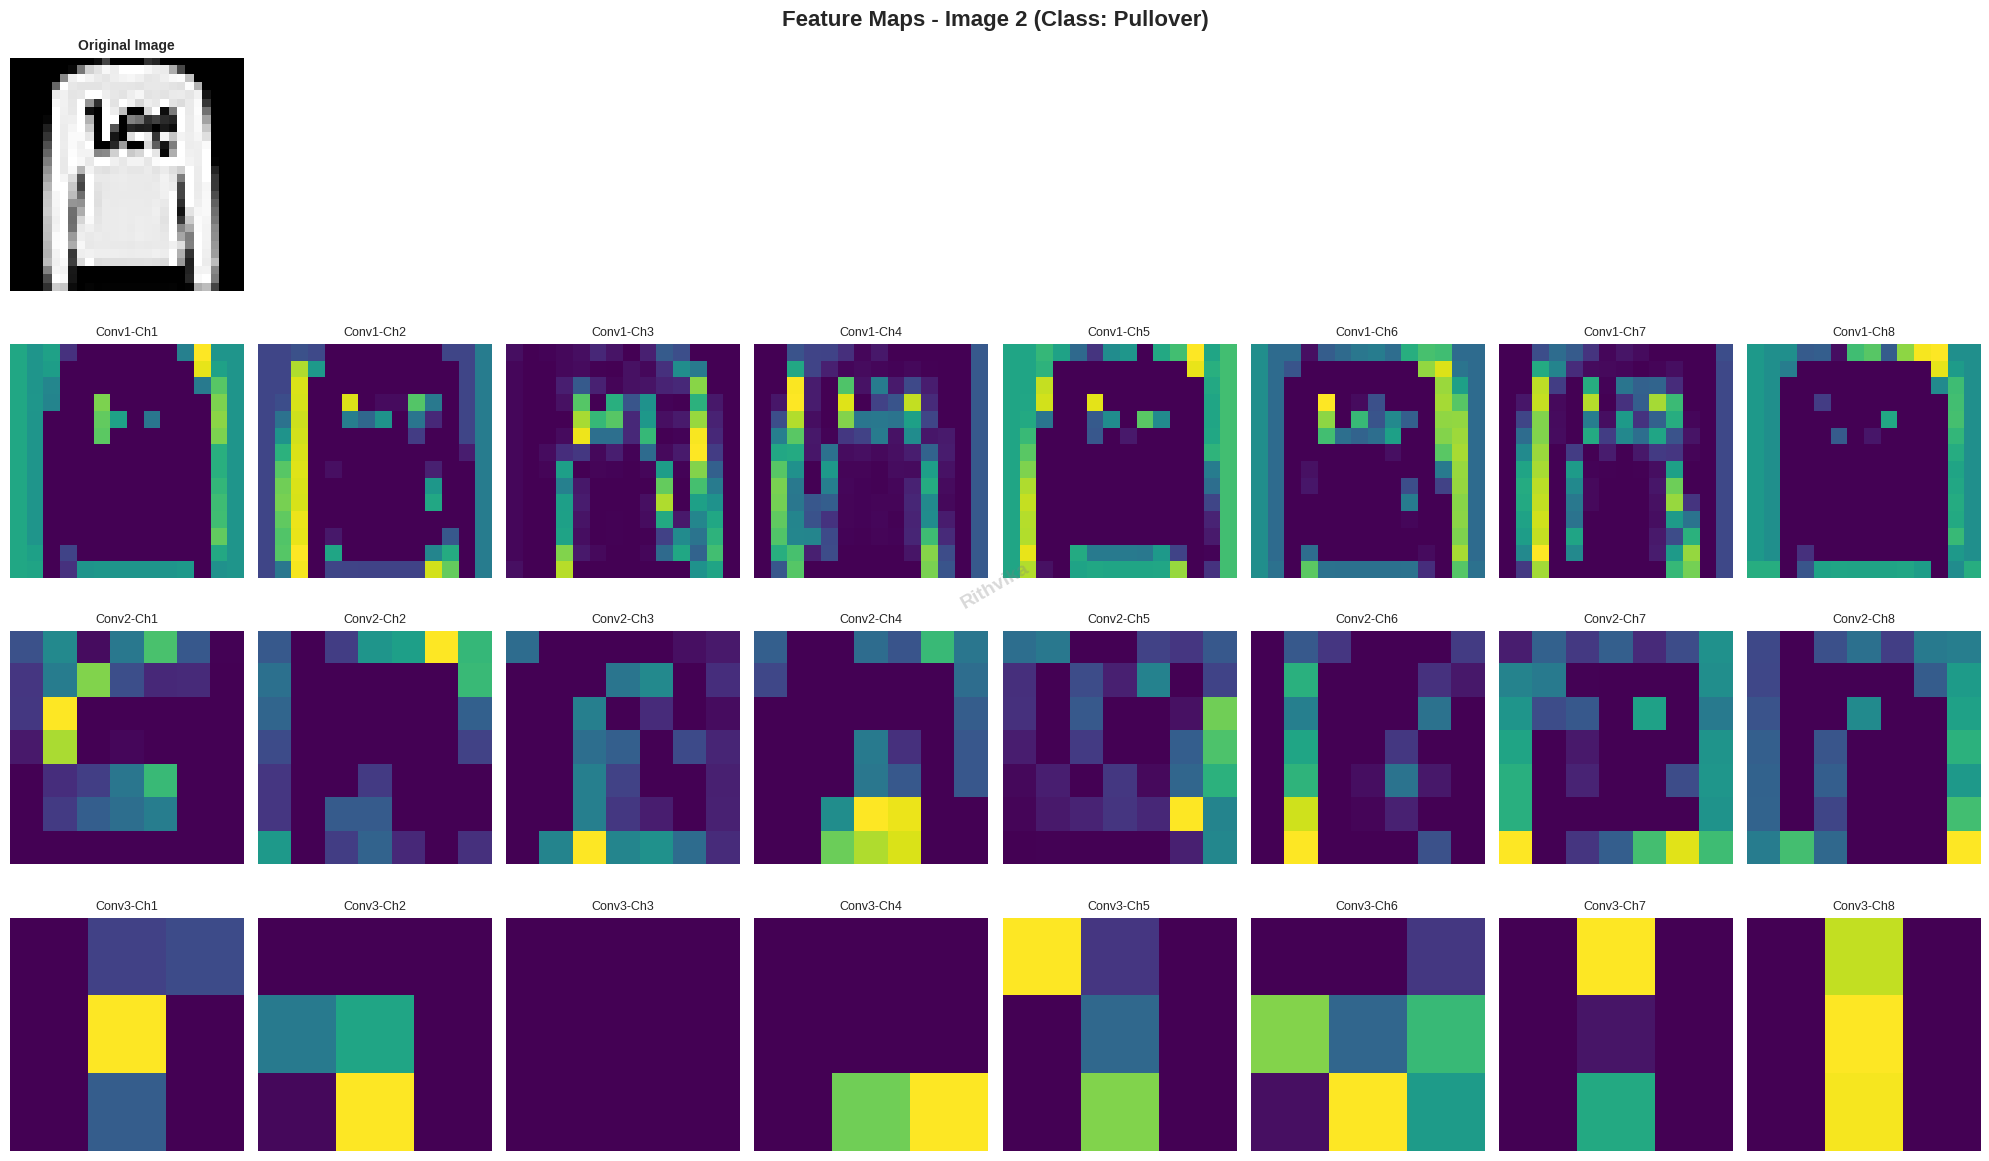

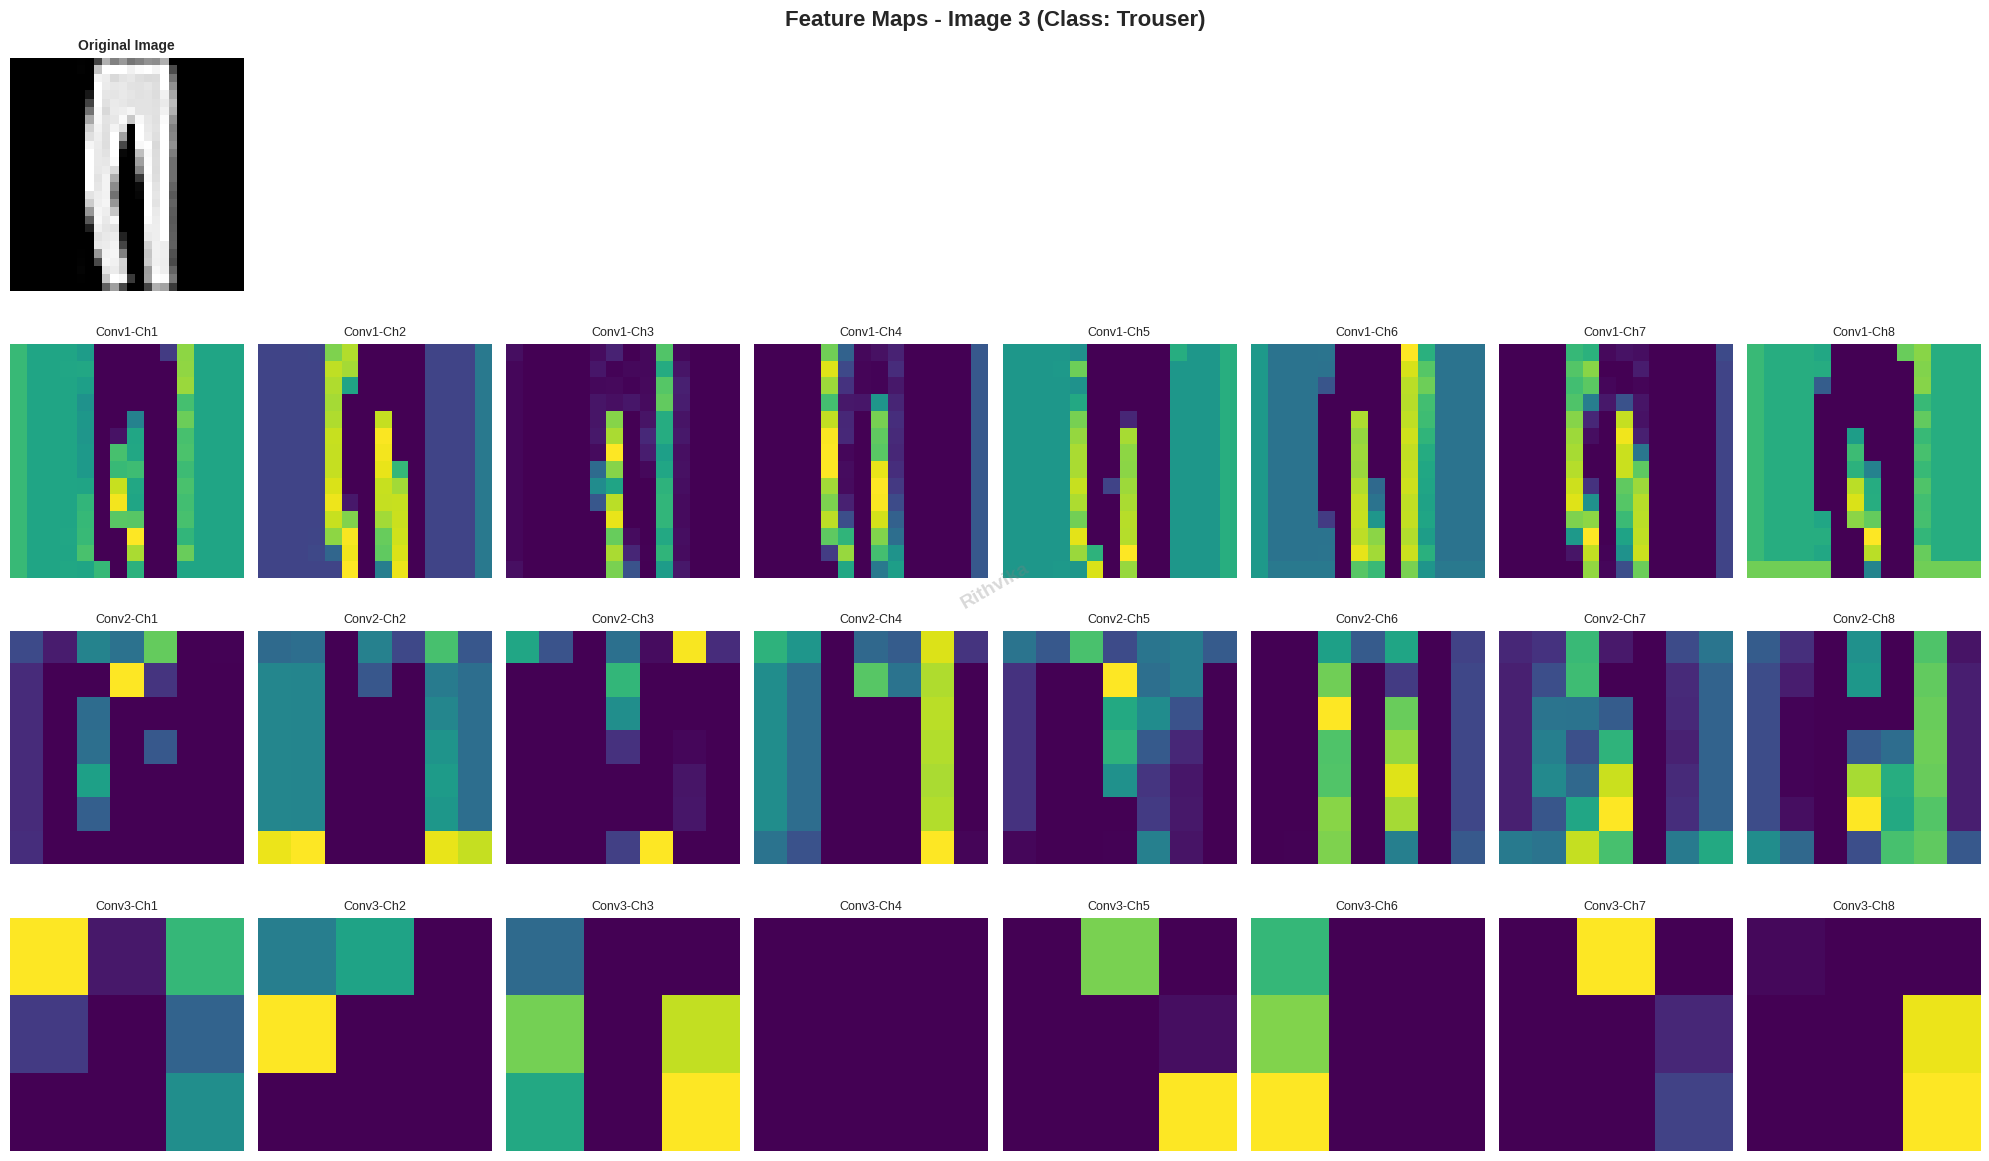


 Feature map visualizations completed and logged to wandb'


epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
learning_rate,███████████████████████████▁▁▁
test/accuracy,▁
test/f1_score,▁
test/loss,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▅▄▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁
train/loss,█▅▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁
train/mse_loss,█▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
+7,...



✓ Experiment 6 completed!


EXPERIMENT 7/8: Smaller Filters (16-32-64)
Configuration:
  • Learning Rate: 0.001
  • Optimizer: Adam
  • Dropout: 0.3
  • Batch Size: 128
  • Lambda1 (Classification): 1.0
  • Lambda2 (Regression): 1.0
  • Channels/Filters: [16, 32, 64] (Blocks: 3)
------------------------------------------------------------------------------------------------------------------------



Using device: cuda
Loading data...
Creating model...
Training...
Epoch 1/30 - Train Loss: 0.8515, Val Loss: 0.5158, Val Acc: 0.8063, Val RMSE: 0.0529
Epoch 2/30 - Train Loss: 0.6022, Val Loss: 0.4675, Val Acc: 0.8218, Val RMSE: 0.0422
Epoch 3/30 - Train Loss: 0.5407, Val Loss: 0.4388, Val Acc: 0.8382, Val RMSE: 0.0404
Epoch 4/30 - Train Loss: 0.5085, Val Loss: 0.3907, Val Acc: 0.8533, Val RMSE: 0.0412
Epoch 5/30 - Train Loss: 0.4893, Val Loss: 0.3879, Val Acc: 0.8558, Val RMSE: 0.0425
Epoch 6/30 - Train Loss: 0.4704, Val Loss: 0.3586, Val Acc: 0.8678, Val RMSE: 0.0412
Epoch 7/30 - Train Loss: 0.4567, Val Loss: 0.3651, Val Acc: 0.8655, Val RMSE: 0.0396
Epoch 8/30 - Train Loss: 0.4450, Val Loss: 0.3425, Val Acc: 0.8700, Val RMSE: 0.0356
Epoch 9/30 - Train Loss: 0.4384, Val Loss: 0.3325, Val Acc: 0.8805, Val RMSE: 0.0384
Epoch 10/30 - Train Loss: 0.4291, Val Loss: 0.3286, Val Acc: 0.8767, Val RMSE: 0.0443
Epoch 11/30 - Train Loss: 0.4230, Val Loss: 0.3227, Val Acc: 0.8772, Val RMSE: 0.040

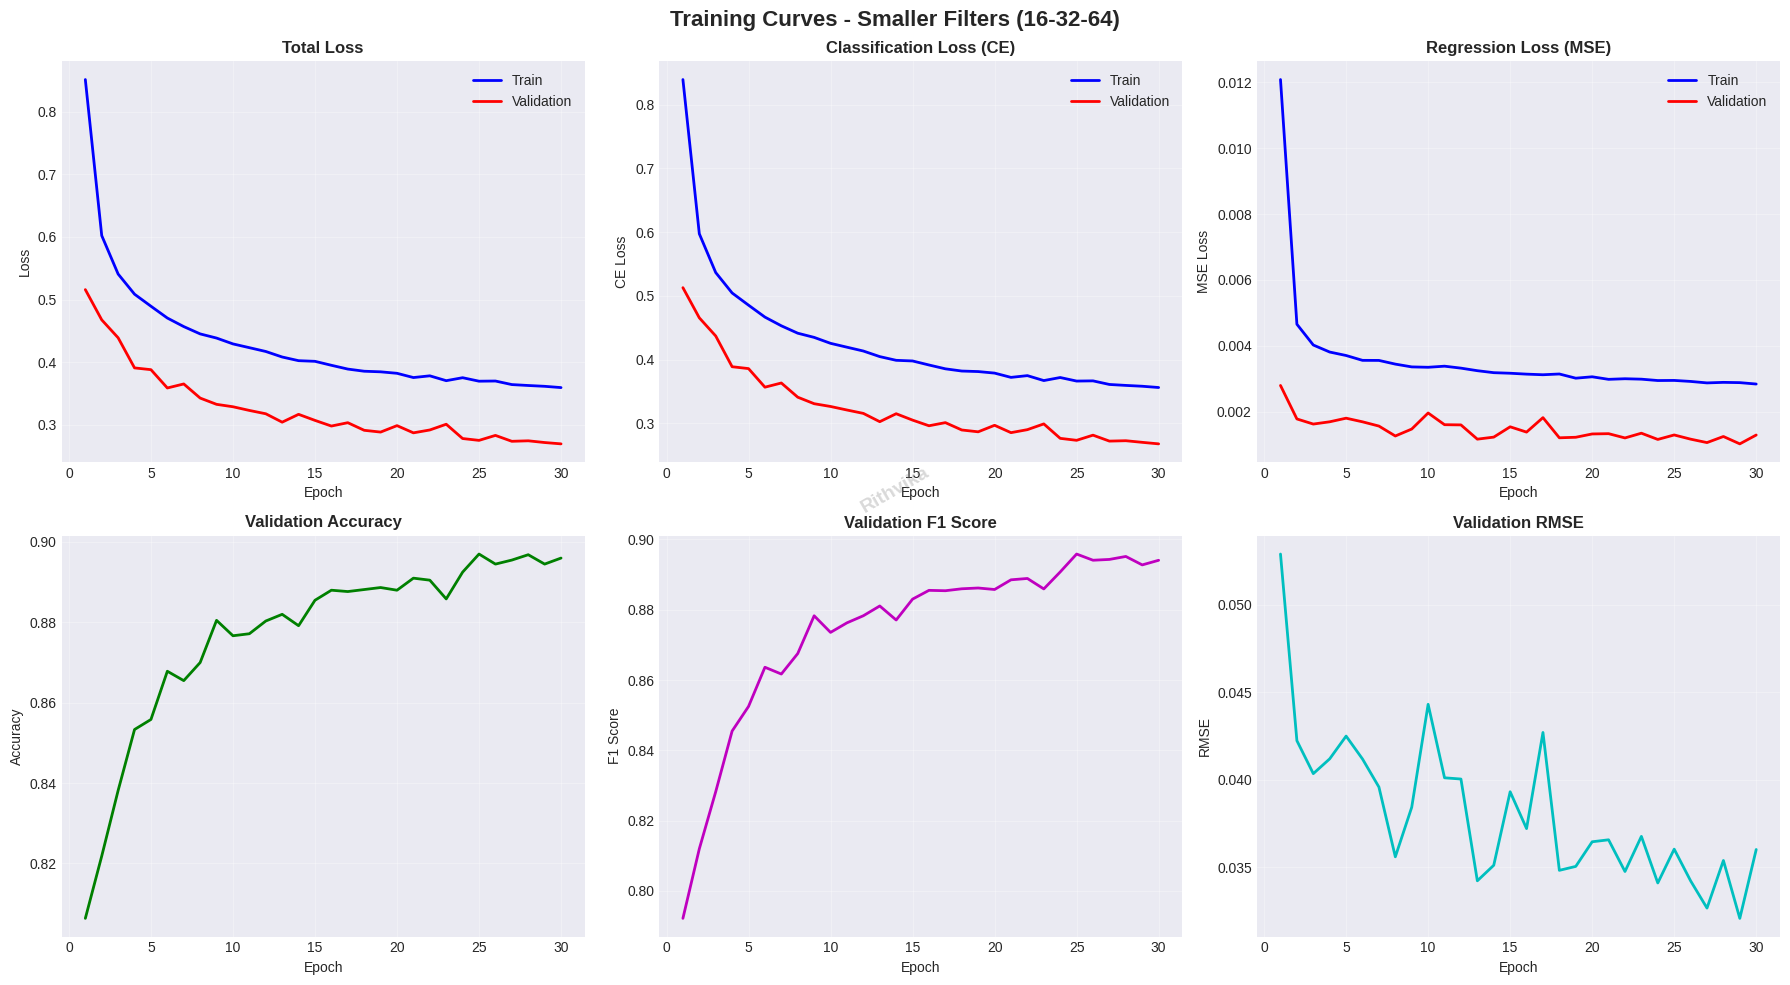


EVALUATING ON TEST SET

✓ Test Results:
  • Accuracy:  0.9020
  • F1 Score:  0.9009
  • MAE:       0.0272
  • RMSE:      0.0353

CONFUSION MATRIX


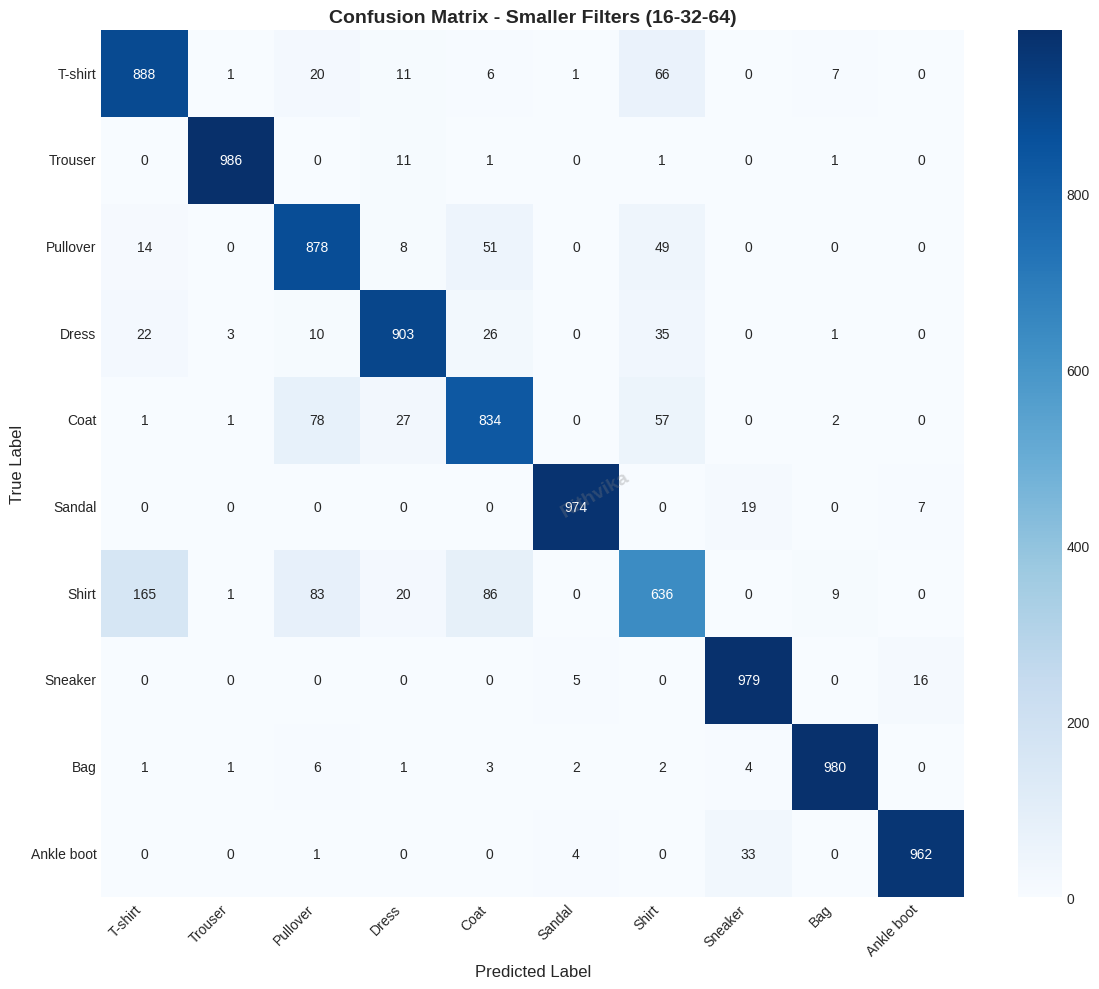


SAMPLE PREDICTIONS


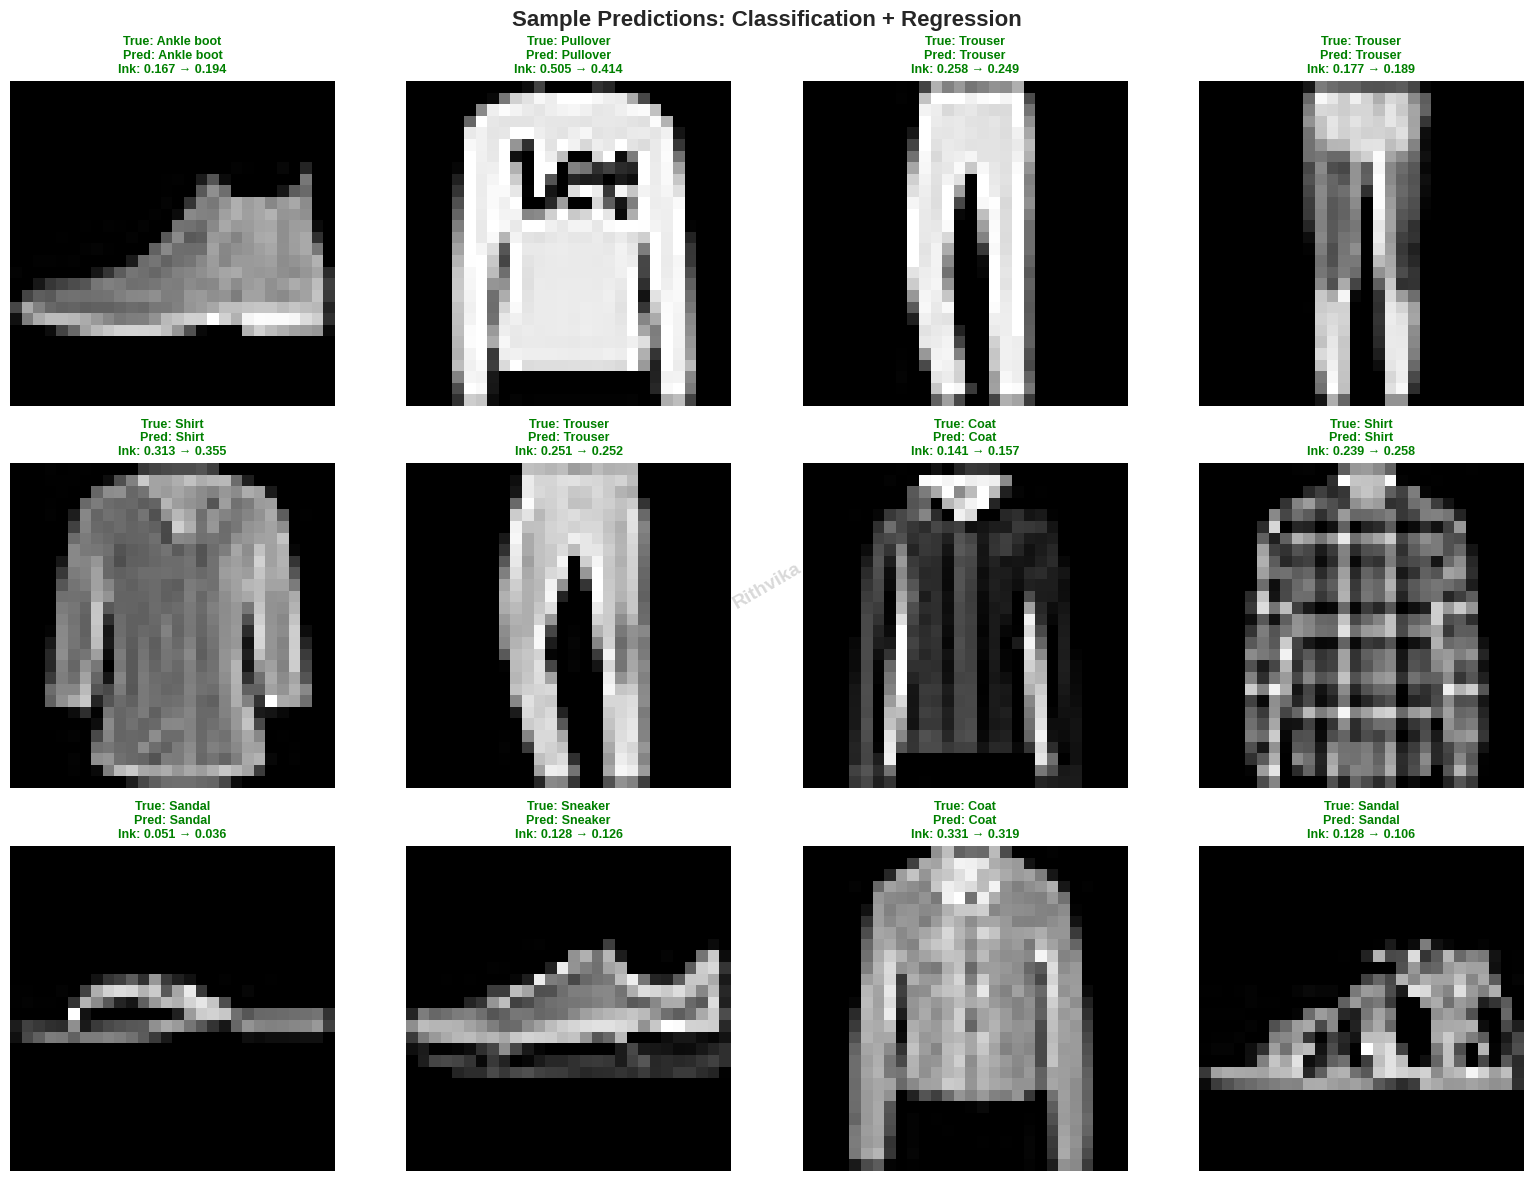


FEATURE MAP VISUALIZATIONS


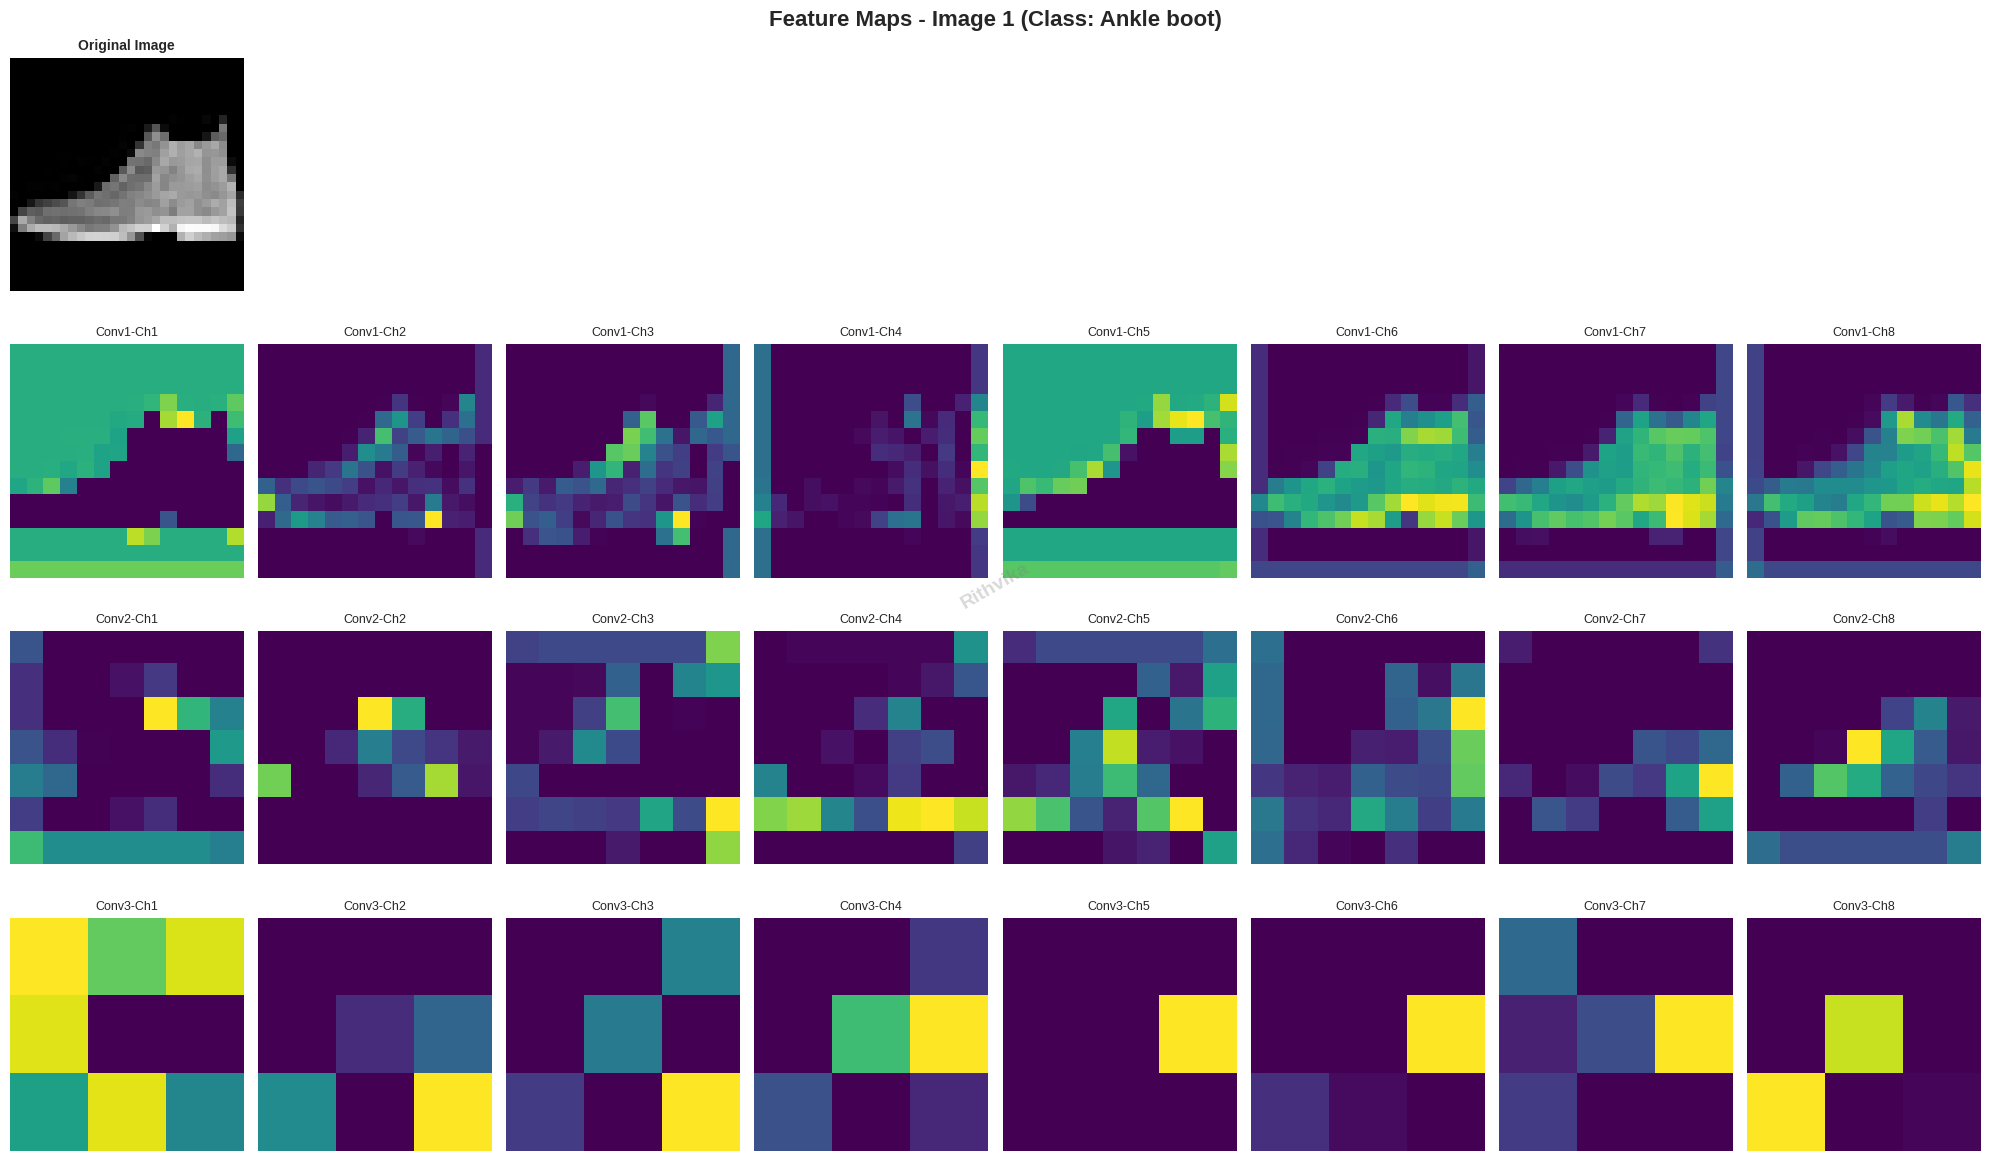

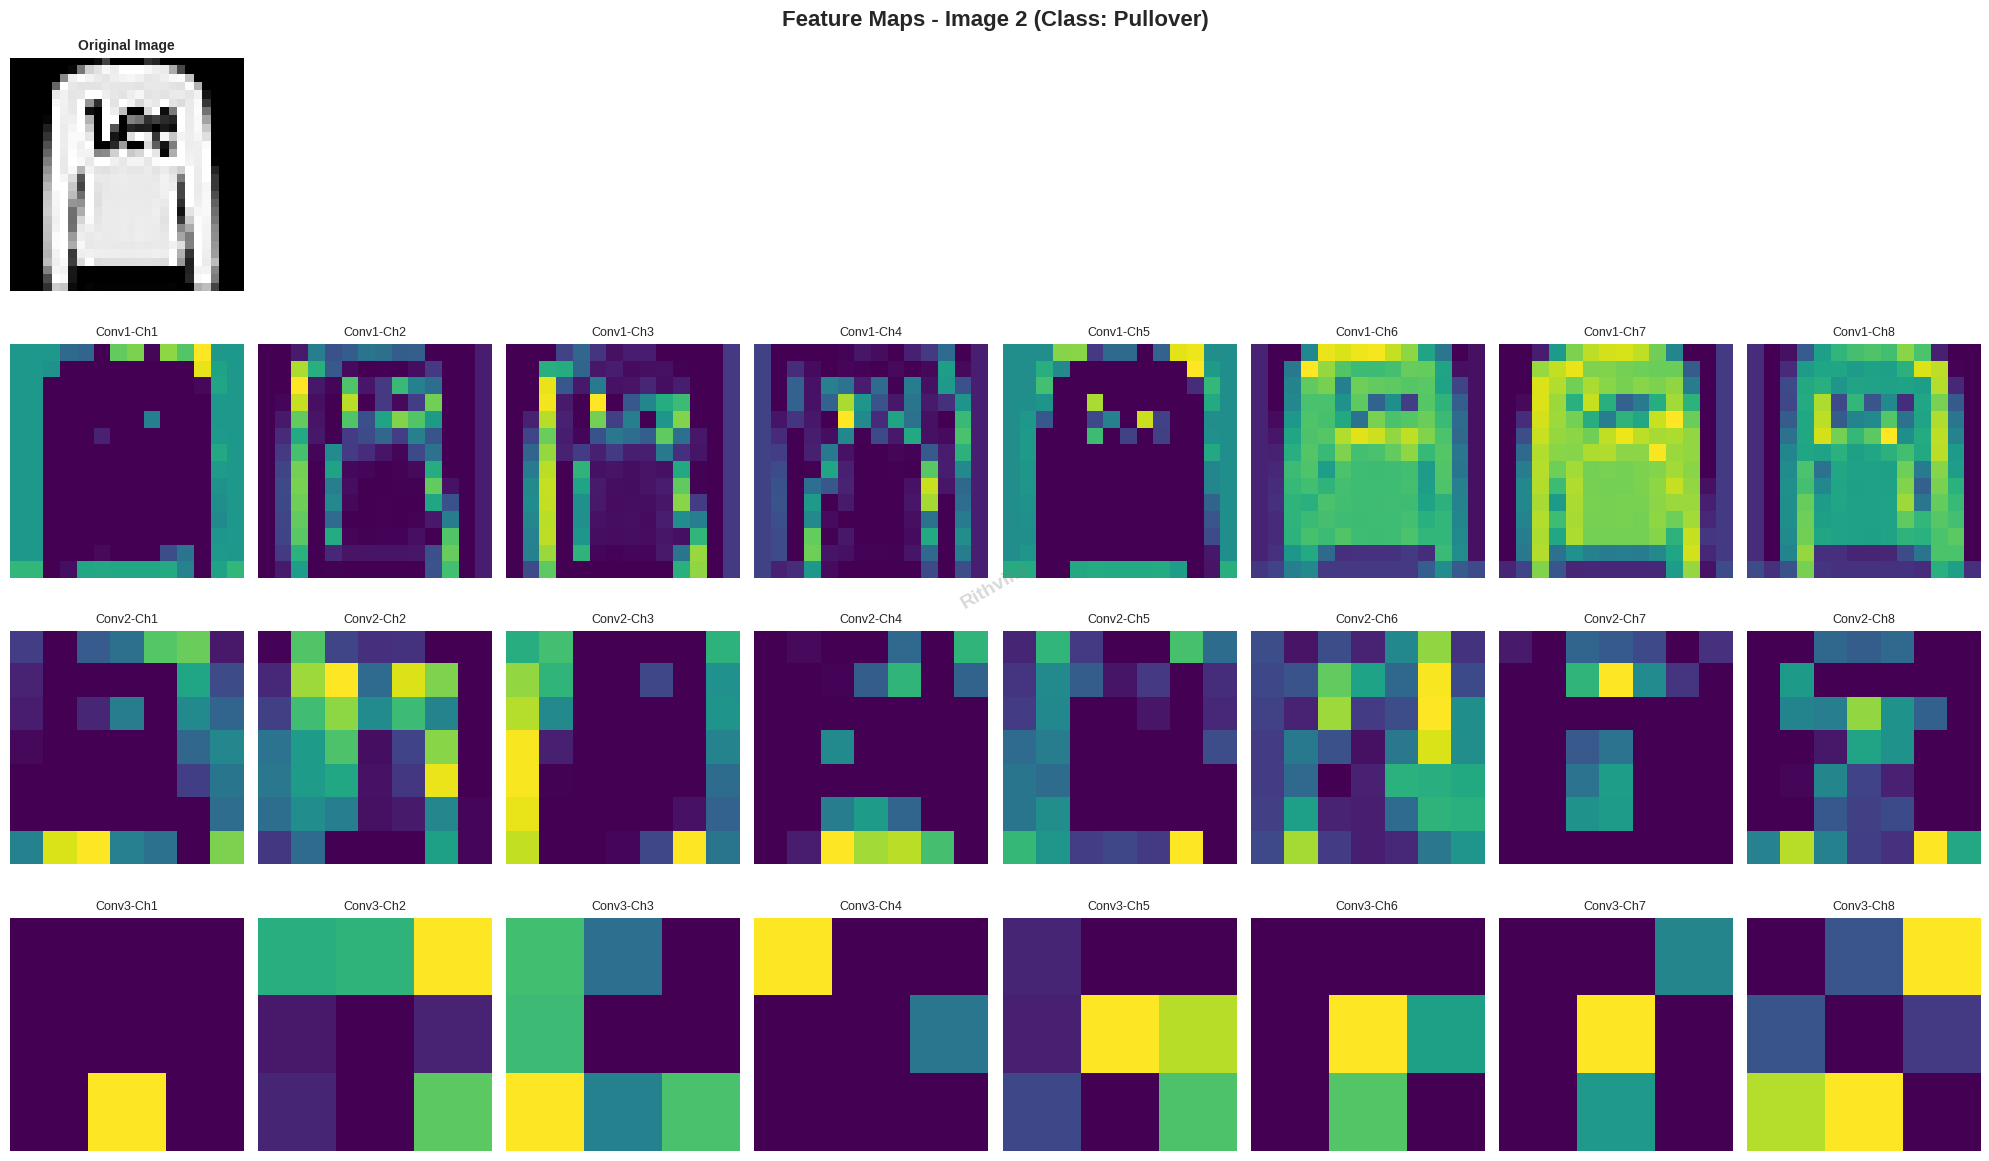

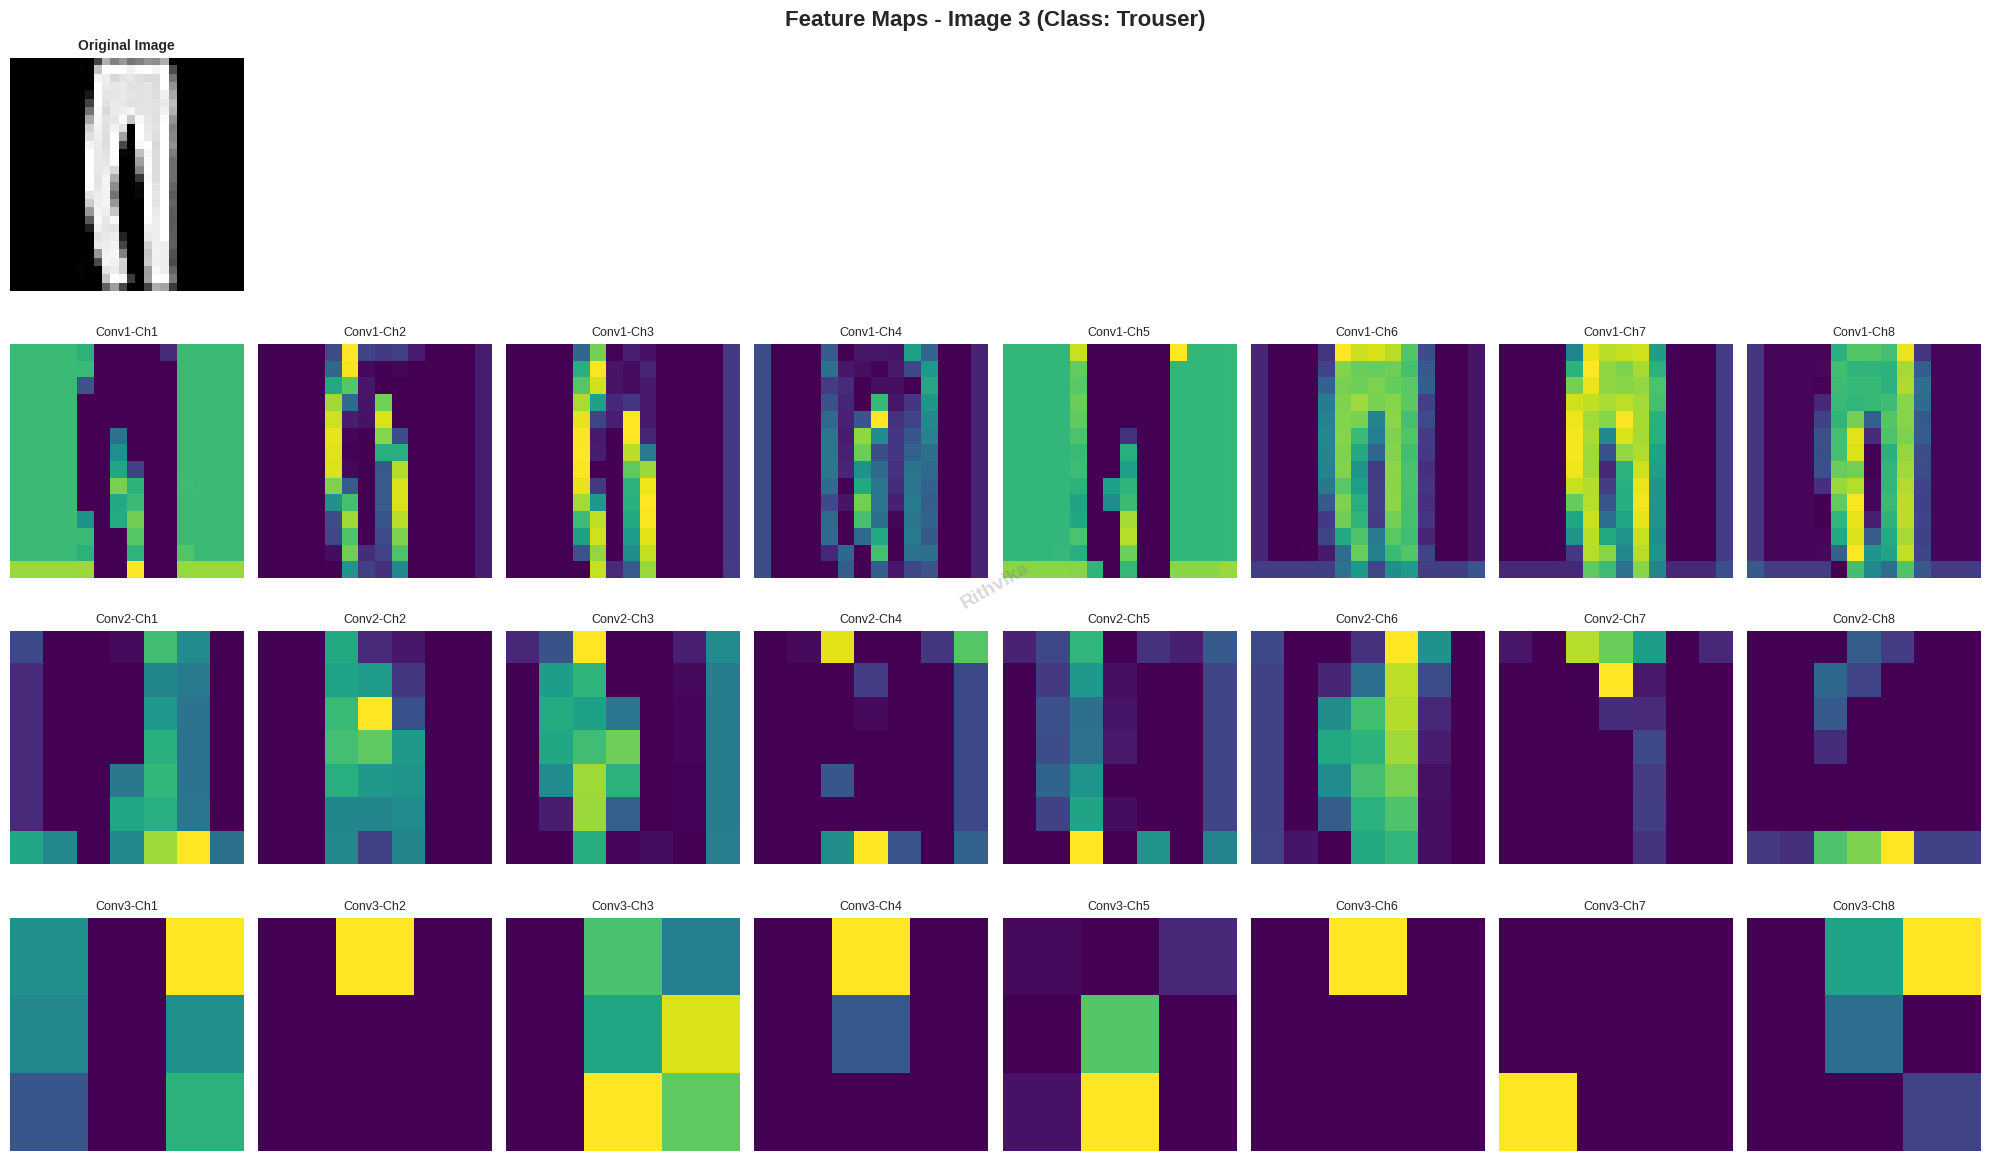


 Feature map visualizations completed and logged to wandb'


epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
test/accuracy,▁
test/f1_score,▁
test/loss,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▄▄▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/loss,█▄▄▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/mse_loss,█▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
+7,...



✓ Experiment 7 completed!


EXPERIMENT 8/8: Shallow 2-Blocks (32-64)
Configuration:
  • Learning Rate: 0.001
  • Optimizer: Adam
  • Dropout: 0.3
  • Batch Size: 128
  • Lambda1 (Classification): 1.0
  • Lambda2 (Regression): 1.0
  • Channels/Filters: [32, 64] (Blocks: 2)
------------------------------------------------------------------------------------------------------------------------



Using device: cuda
Loading data...
Creating model...
Training...
Epoch 1/30 - Train Loss: 0.9060, Val Loss: 0.5295, Val Acc: 0.8140, Val RMSE: 0.1679
Epoch 2/30 - Train Loss: 0.5886, Val Loss: 0.4359, Val Acc: 0.8403, Val RMSE: 0.1290
Epoch 3/30 - Train Loss: 0.5346, Val Loss: 0.3898, Val Acc: 0.8588, Val RMSE: 0.1270
Epoch 4/30 - Train Loss: 0.4975, Val Loss: 0.3673, Val Acc: 0.8728, Val RMSE: 0.1269
Epoch 5/30 - Train Loss: 0.4826, Val Loss: 0.3505, Val Acc: 0.8792, Val RMSE: 0.1269
Epoch 6/30 - Train Loss: 0.4629, Val Loss: 0.3609, Val Acc: 0.8732, Val RMSE: 0.1269
Epoch 7/30 - Train Loss: 0.4478, Val Loss: 0.3328, Val Acc: 0.8855, Val RMSE: 0.1268
Epoch 8/30 - Train Loss: 0.4349, Val Loss: 0.3303, Val Acc: 0.8808, Val RMSE: 0.1269
Epoch 9/30 - Train Loss: 0.4206, Val Loss: 0.2984, Val Acc: 0.8932, Val RMSE: 0.1268
Epoch 10/30 - Train Loss: 0.4140, Val Loss: 0.3181, Val Acc: 0.8882, Val RMSE: 0.1269
Epoch 11/30 - Train Loss: 0.4015, Val Loss: 0.3017, Val Acc: 0.8948, Val RMSE: 0.127

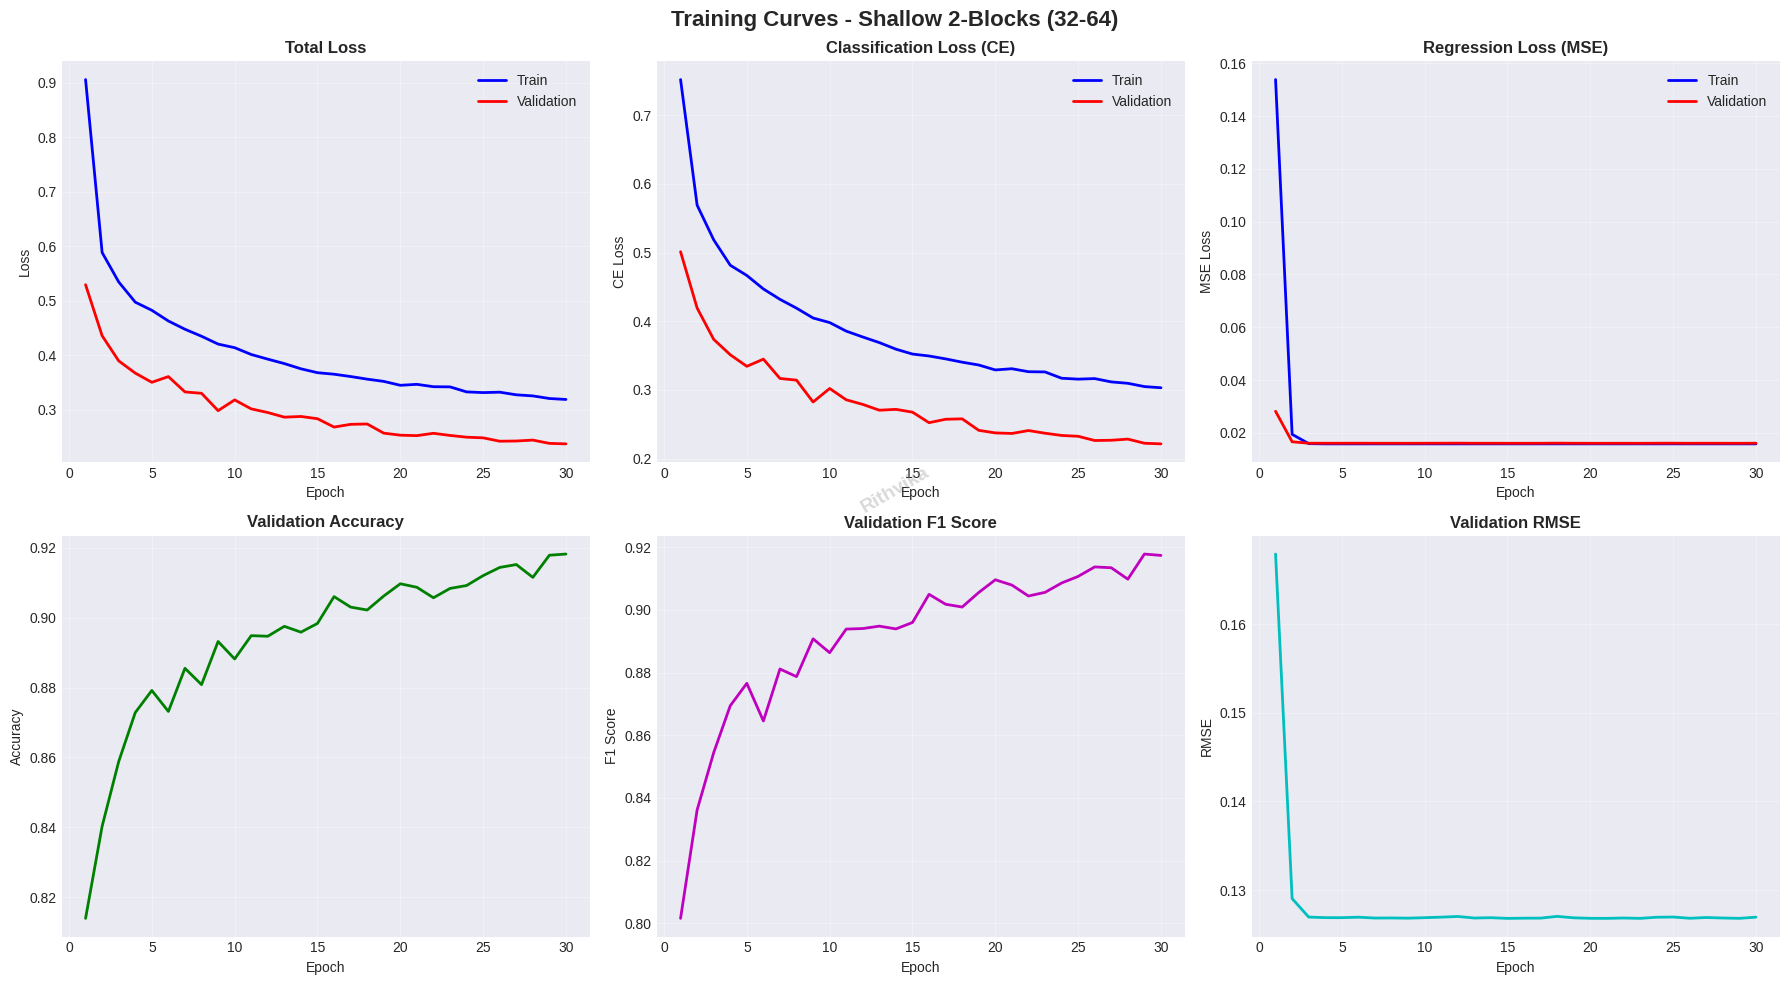


EVALUATING ON TEST SET

✓ Test Results:
  • Accuracy:  0.9158
  • F1 Score:  0.9151
  • MAE:       0.1050
  • RMSE:      0.1258

CONFUSION MATRIX


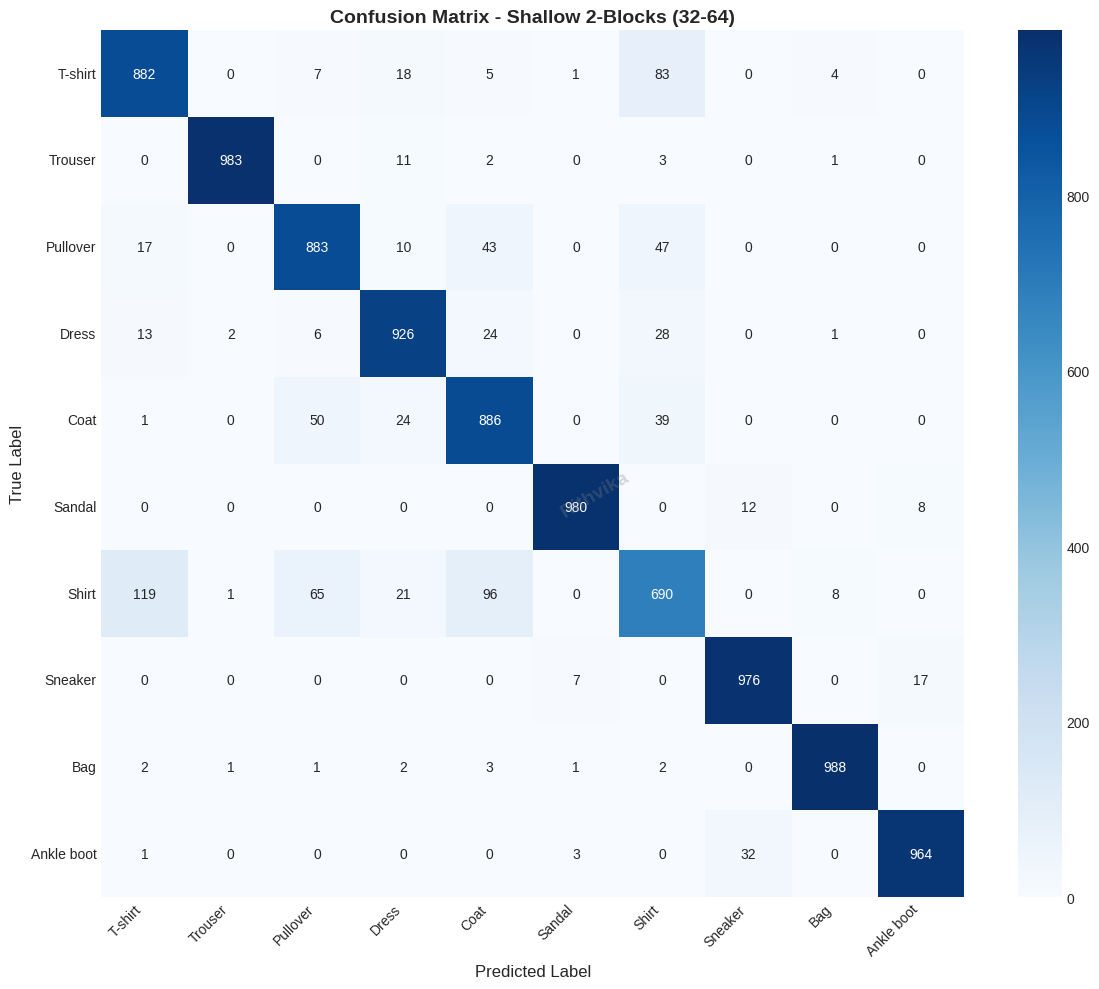


SAMPLE PREDICTIONS


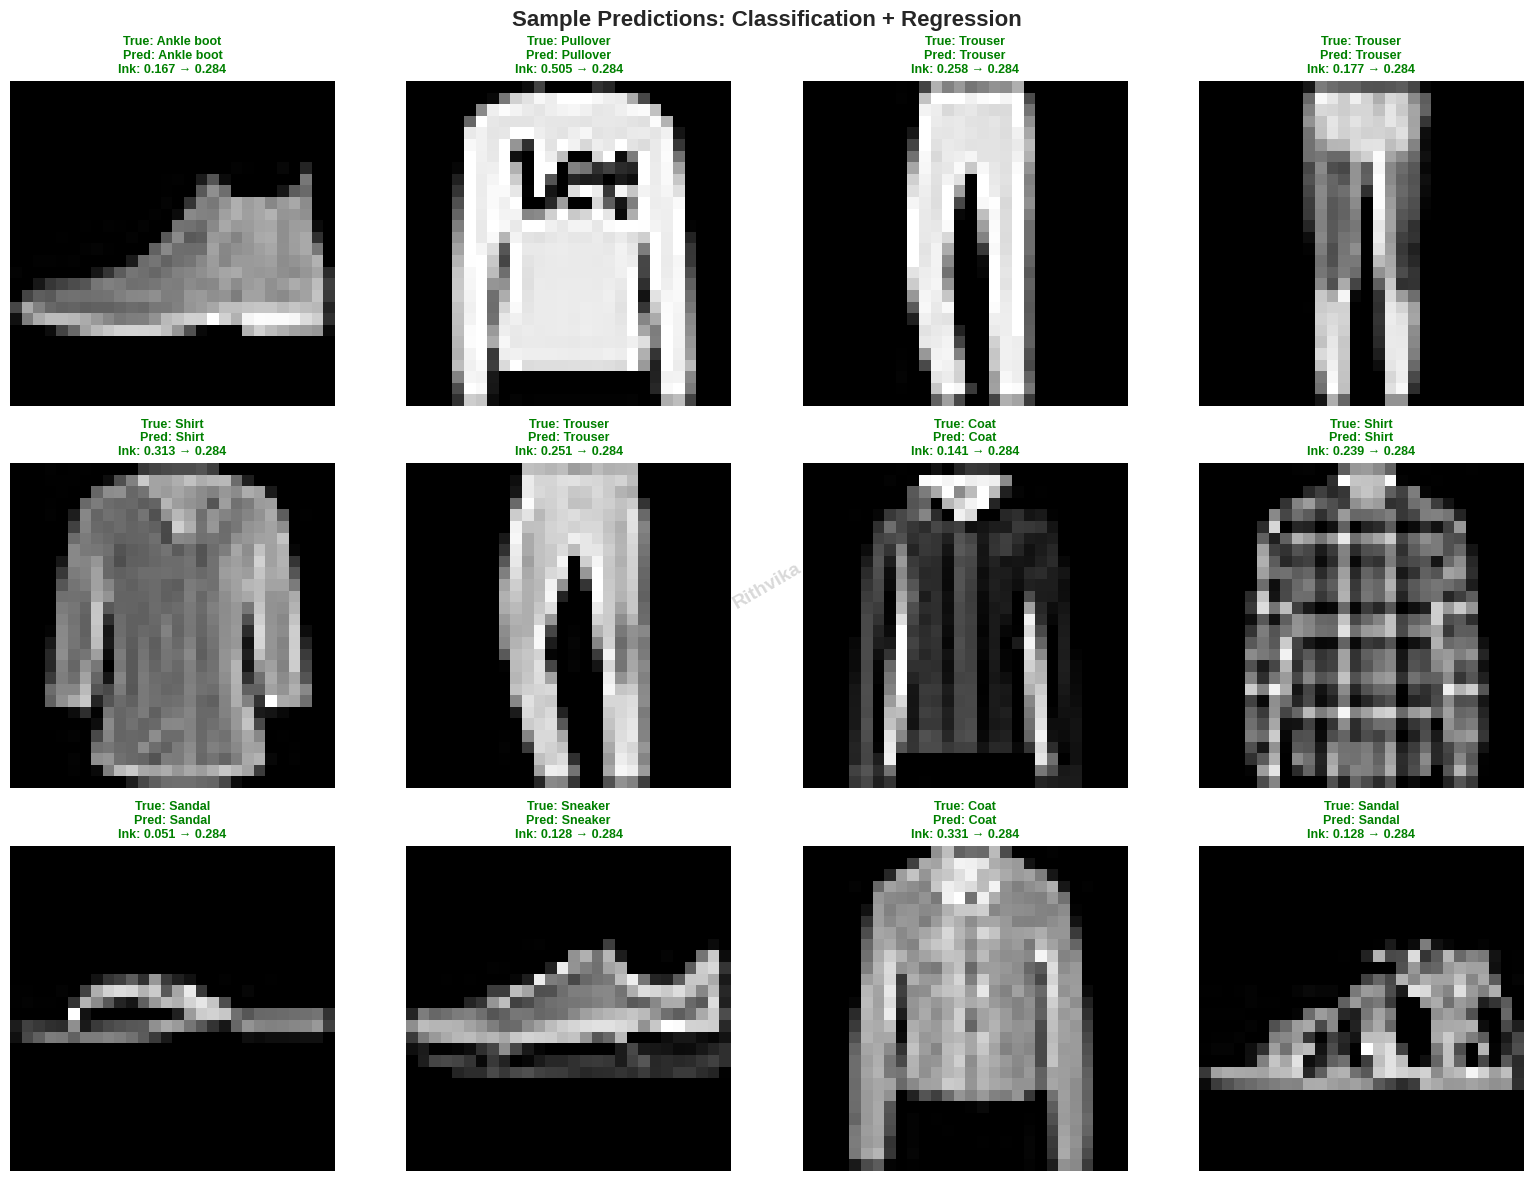


FEATURE MAP VISUALIZATIONS


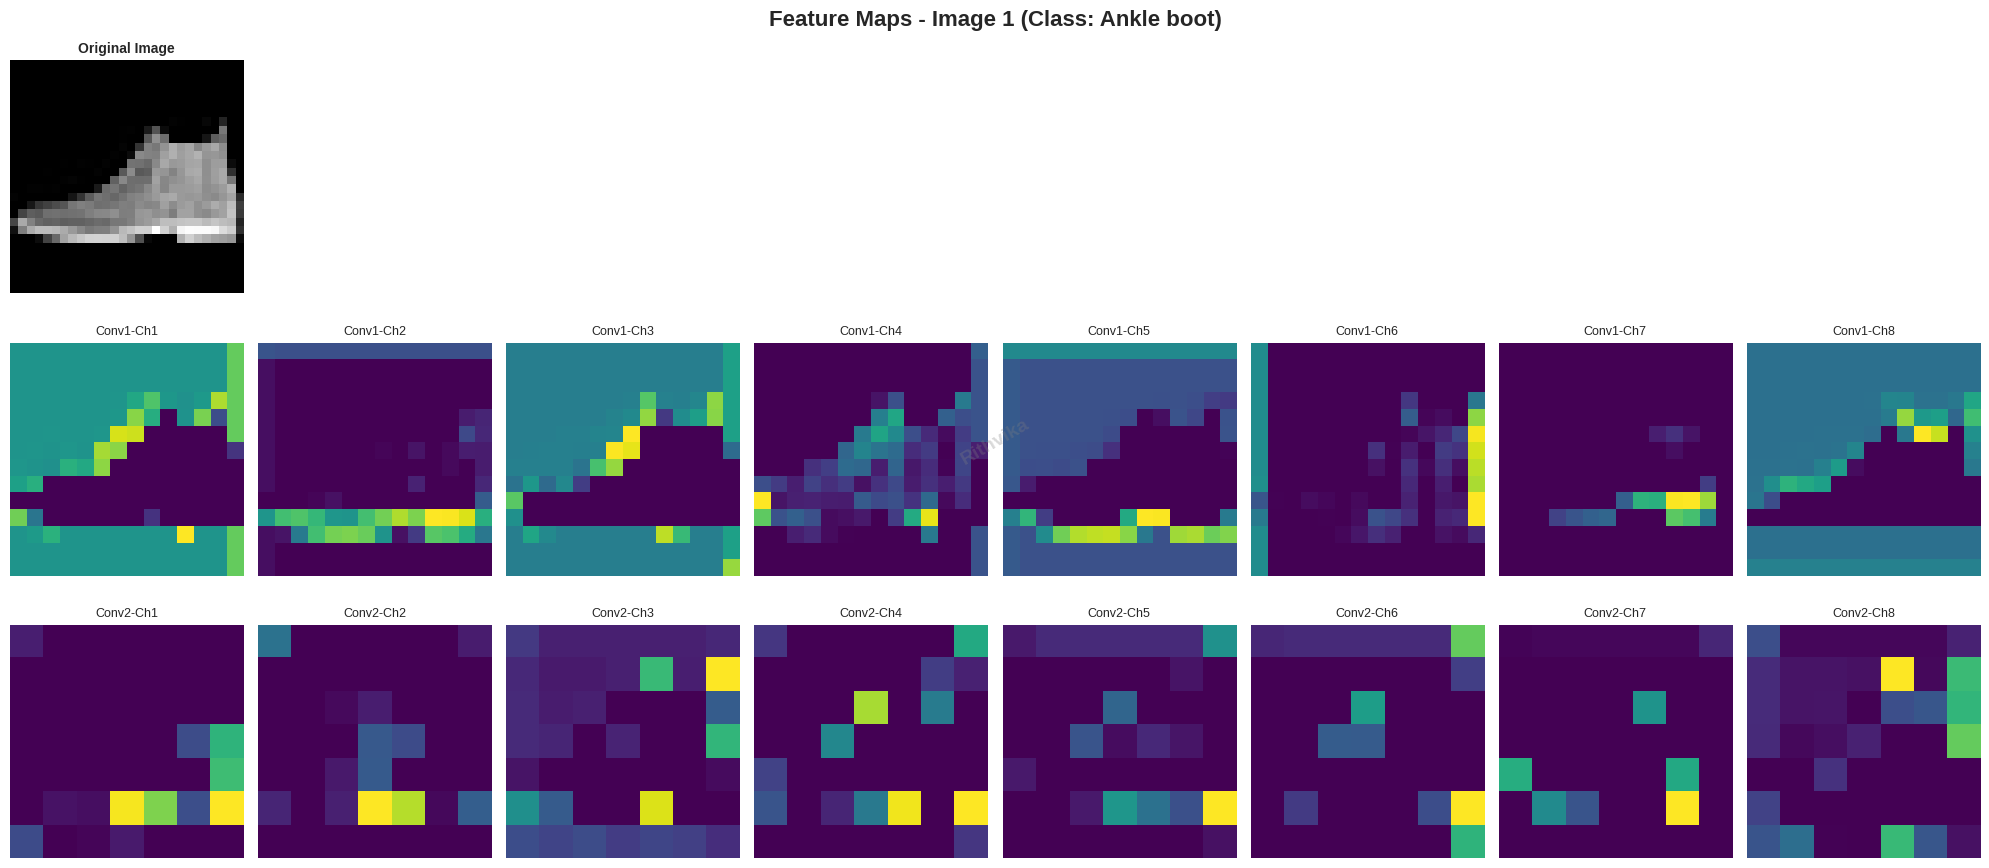

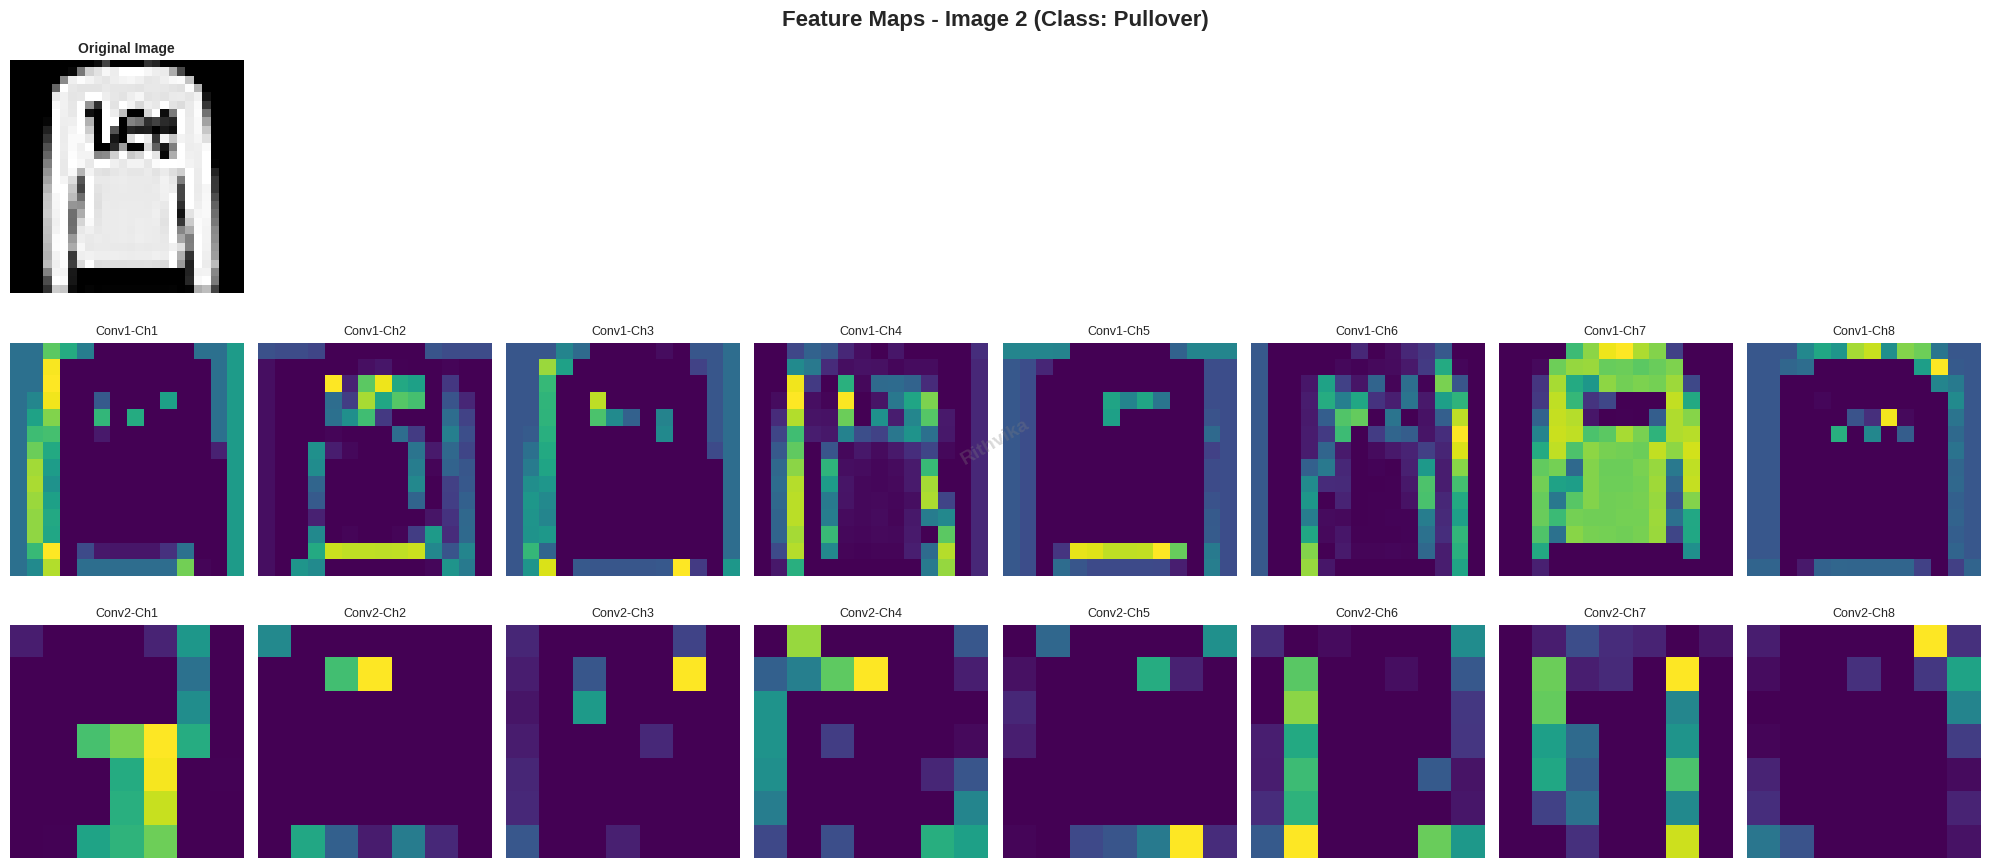

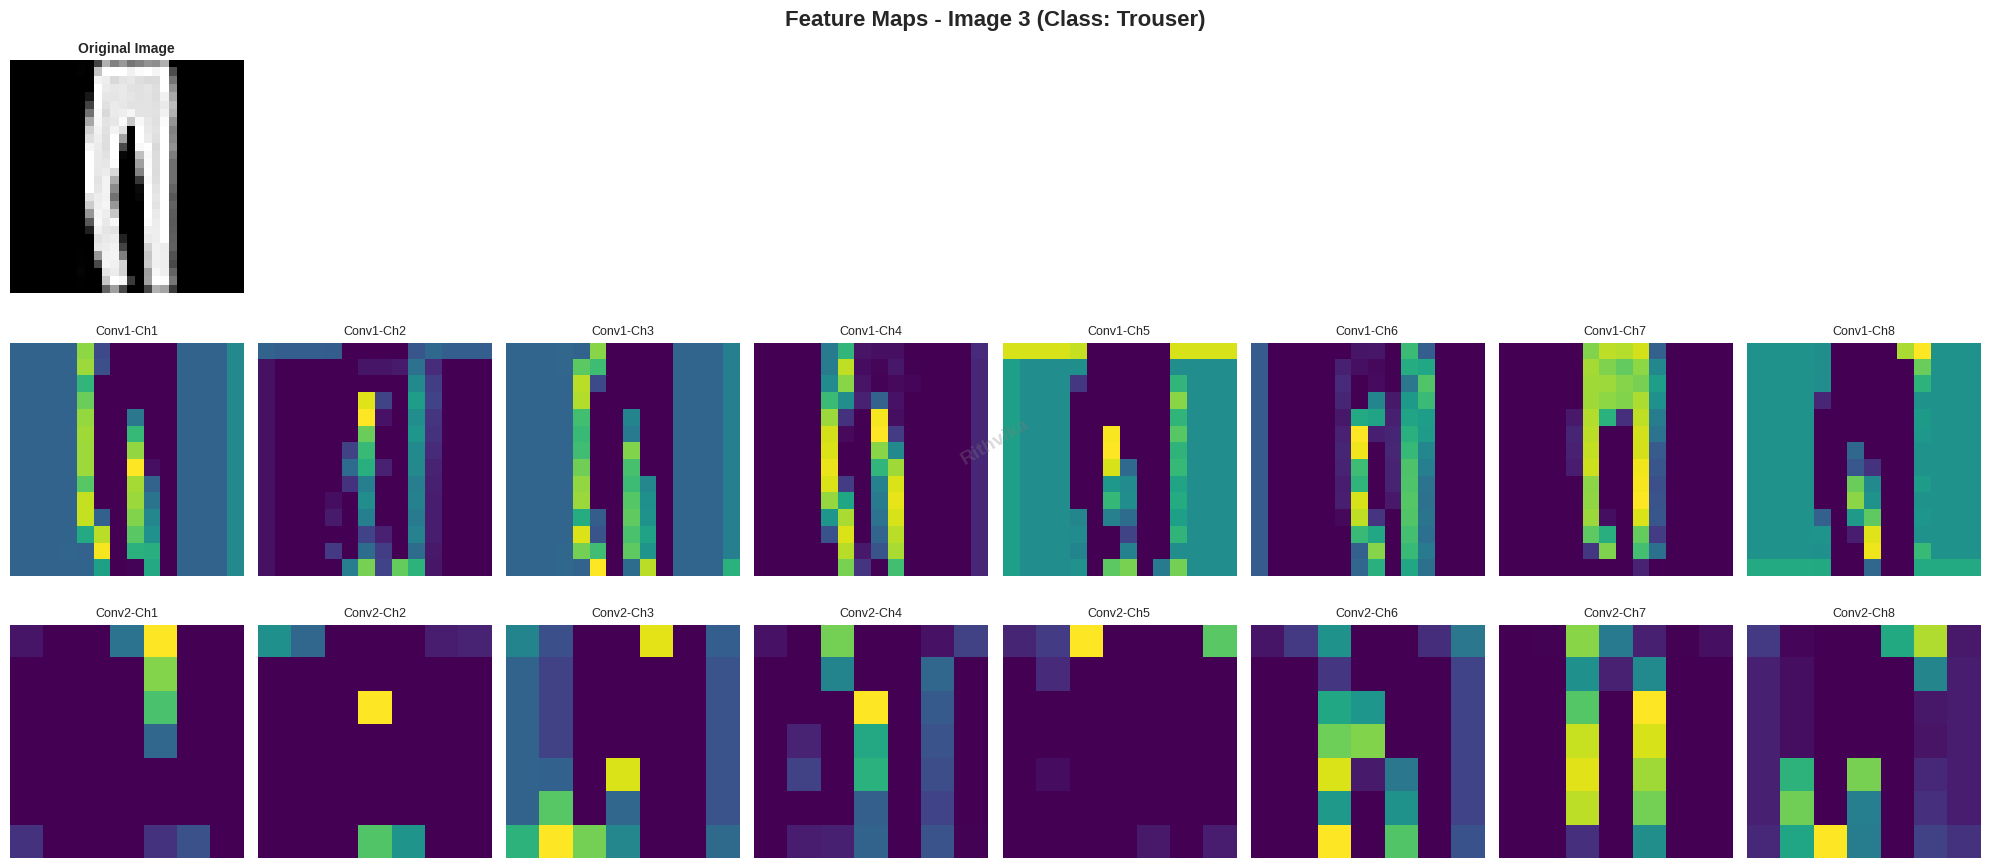


 Feature map visualizations completed and logged to wandb'


epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
test/accuracy,▁
test/f1_score,▁
test/loss,▁
test/mae,▁
test/rmse,▁
train/ce_loss,█▅▄▄▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁
train/loss,█▄▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
train/mse_loss,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
+7,...



✓ Experiment 8 completed!


COMPREHENSIVE RESULTS SUMMARY TABLE
Experiment                λ1     λ2     Accuracy   F1-Score   MAE        RMSE      
------------------------------------------------------------------------------------------------------------------------
Balanced (1:1)            1.00   1.00   0.9110     0.9109     0.0182     0.0239    
Classification Focus (2:1) 2.00   1.00   0.9120     0.9104     0.0226     0.0293    
Regression Focus (1:2)    1.00   2.00   0.9099     0.9102     0.0209     0.0264    
Regression Focus (0.5:1)  0.50   1.00   0.9146     0.9146     0.0182     0.0242    
Classification Focus(1.5 : 1) 1.50   1.00   0.9136     0.9127     0.0238     0.0307    
High Regularization (1 : 1.5) 1.00   1.50   0.9130     0.9123     0.0193     0.0260    
Smaller Filters (16-32-64) 1.00   1.00   0.9020     0.9009     0.0272     0.0353    
Shallow 2-Blocks (32-64)  1.00   1.00   0.9158     0.9151     0.1050     0.1258    

BEST MODELS

Best Classification Accuracy: Shal

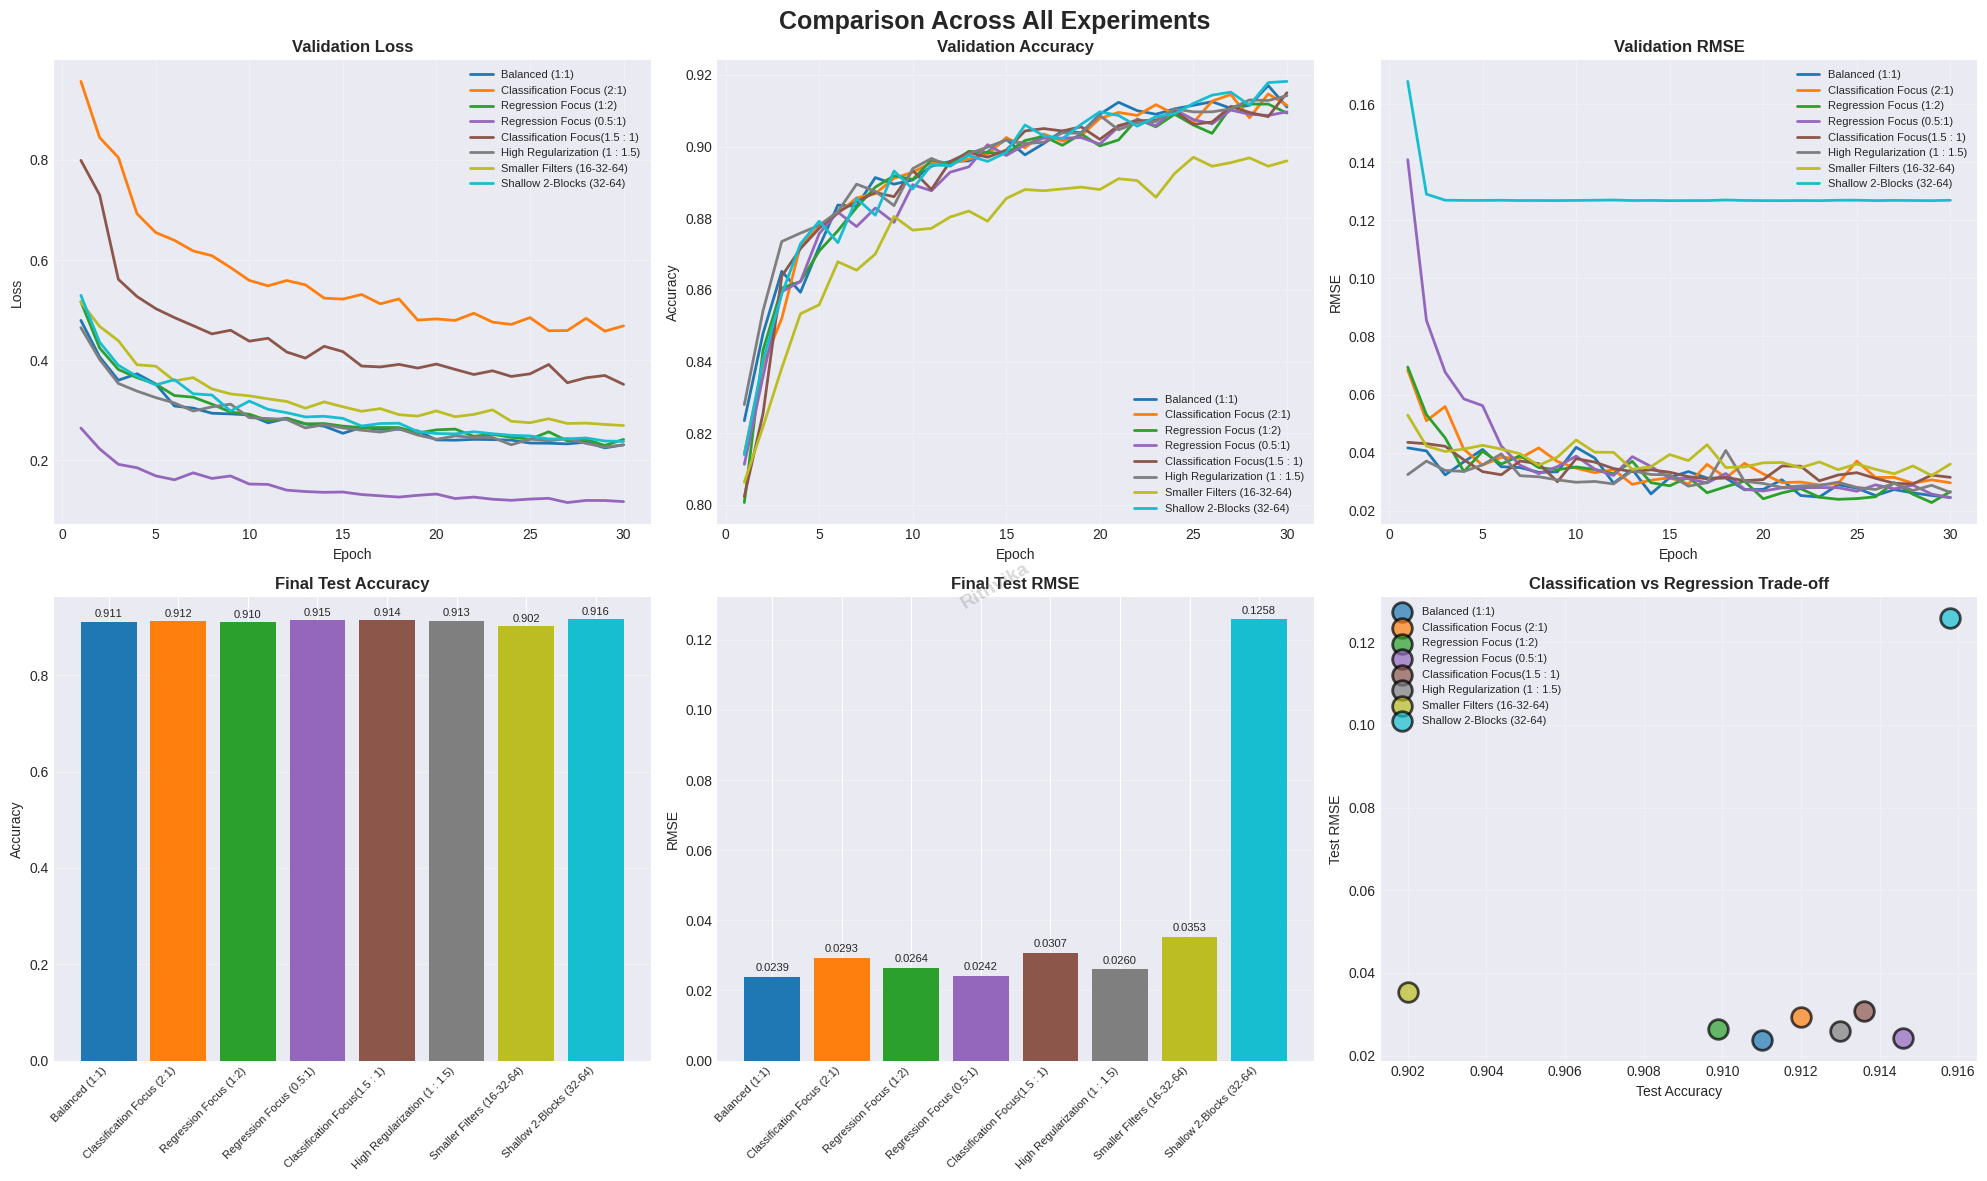

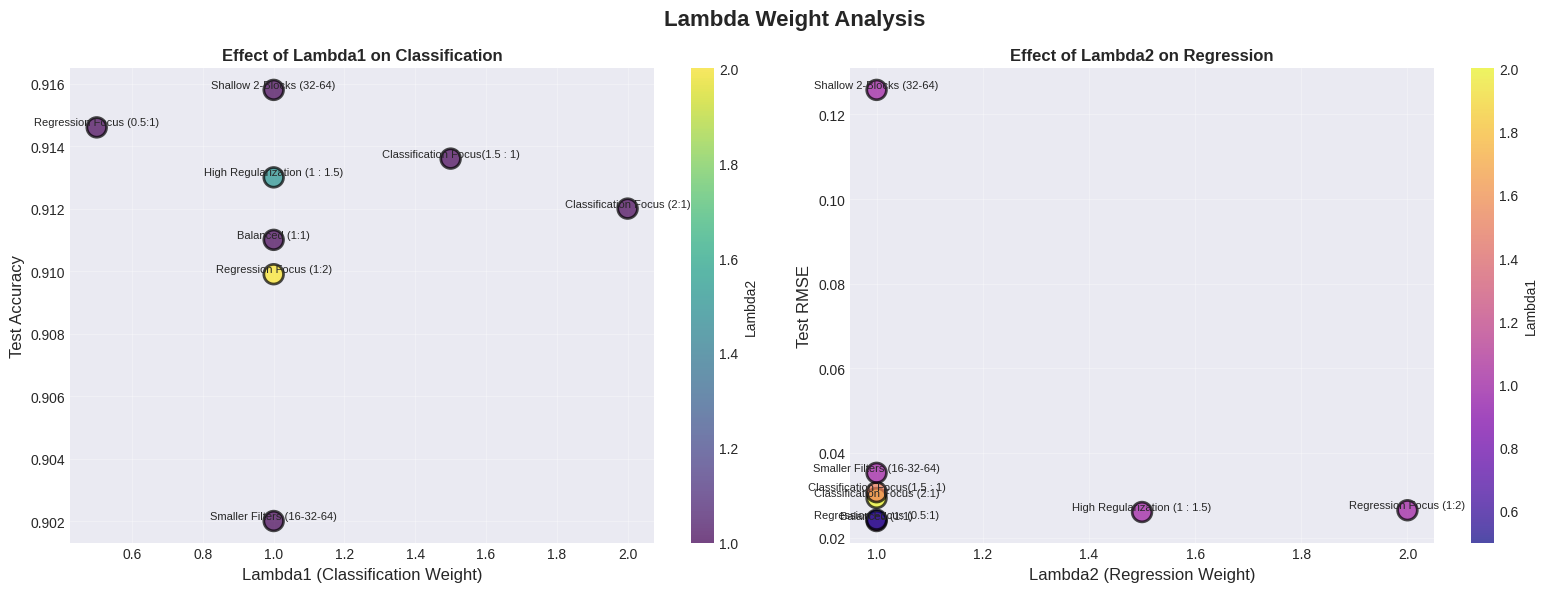


✓ ALL EXPERIMENTS COMPLETED!


In [ ]:

# ============================================================================
# 7. MAIN EXECUTION - MULTIPLE EXPERIMENTS
# ============================================================================


def main():
    """
    Run multiple experiments with different hyperparameters
    """
    # Define configurations (now include channels/filters)
    experiments = [
        {
            'name': 'Balanced (1:1)',
            'learning_rate': 0.001,
            'dropout_rate': 0.3,
            'optimizer': 'Adam',
            'batch_size': 128,
            'epochs': 30,
            'lambda1': 1.0,
            'lambda2': 1.0,
            'channels': [32, 64, 128]
        },
        {
            'name': 'Classification Focus (2:1)',
            'learning_rate': 0.001,
            'dropout_rate': 0.3,
            'optimizer': 'Adam',
            'batch_size': 128,
            'epochs': 30,
            'lambda1': 2.0,
            'lambda2': 1.0,
            'channels': [32, 64, 128]
        },
        {
            'name': 'Regression Focus (1:2)',
            'learning_rate': 0.001,
            'dropout_rate': 0.3,
            'optimizer': 'Adam',
            'batch_size': 128,
            'epochs': 30,
            'lambda1': 1.0,
            'lambda2': 2.0,
            'channels': [32, 64, 128]
        },
        {
            'name': 'Regression Focus (0.5:1)',
            'learning_rate': 0.001,
            'dropout_rate': 0.3,
            'optimizer': 'AdamW',
            'batch_size': 128,
            'epochs': 30,
            'lambda1': 0.5,
            'lambda2': 1.0,
            'channels': [32, 64, 128]
        },
        {
            'name': 'Classification Focus(1.5 : 1)',
            'learning_rate': 0.01,
            'dropout_rate': 0.3,
            'optimizer': 'SGD',
            'batch_size': 64,
            'epochs': 30,
            'lambda1': 1.5,
            'lambda2': 1.0,
            'channels': [32, 64, 128]
        },
        {
            'name': 'High Regularization (1 : 1.5)',
            'learning_rate': 0.0005,
            'dropout_rate': 0.3,
            'optimizer': 'AdamW',
            'batch_size': 32,
            'epochs': 30,
            'lambda1': 1.0,
            'lambda2': 1.5,
            'channels': [32, 64, 128]
        },
        # New: Smaller filters (capacity) to explore filters hyperparameter
        {
            'name': 'Smaller Filters (16-32-64)',
            'learning_rate': 0.001,
            'dropout_rate': 0.3,
            'optimizer': 'Adam',
            'batch_size': 128,
            'epochs': 30,
            'lambda1': 1.0,
            'lambda2': 1.0,
            'channels': [16, 32, 64]
        },
        # New: Larger filters and fewer layers to explore depth vs width
        {
            'name': 'Shallow 2-Blocks (32-64)',
            'learning_rate': 0.001,
            'dropout_rate': 0.3,
            'optimizer': 'Adam',
            'batch_size': 128,
            'epochs': 30,
            'lambda1': 1.0,
            'lambda2': 1.0,
            'channels': [32, 64]
        }
    ]

    all_results = []

    print("="*120)
    print(" "*40 + "MULTI-TASK CNN EXPERIMENTS")
    print("="*120)
    print(f"\nRunning {len(experiments)} experiments with different hyperparameter configurations...\n")

    for i, exp_config in enumerate(experiments):
        print("\n" + "="*120)
        print(f"EXPERIMENT {i+1}/{len(experiments)}: {exp_config['name']}")
        print("="*120)
        print(f"Configuration:")
        print(f"  • Learning Rate: {exp_config['learning_rate']}")
        print(f"  • Optimizer: {exp_config['optimizer']}")
        print(f"  • Dropout: {exp_config['dropout_rate']}")
        print(f"  • Batch Size: {exp_config['batch_size']}")
        print(f"  • Lambda1 (Classification): {exp_config['lambda1']}")
        print(f"  • Lambda2 (Regression): {exp_config['lambda2']}")
        print(f"  • Channels/Filters: {exp_config.get('channels', [32,64,128])} (Blocks: {len(exp_config.get('channels', [32,64,128]))})")
        print("-"*120 + "\n")

        metrics, history = run_experiment(exp_config)
        all_results.append({
            'name': exp_config['name'],
            'config': exp_config,
            'metrics': metrics,
            'history': history
        })

        print(f"\n✓ Experiment {i+1} completed!\n")
    # Print summary table
    print_summary_table(all_results)

    # Find best models
    best_acc_idx = max(range(len(all_results)), key=lambda i: all_results[i]['metrics']['accuracy'])
    best_rmse_idx = min(range(len(all_results)), key=lambda i: all_results[i]['metrics']['rmse'])

    print("\n" + "="*120)
    print("BEST MODELS")
    print("="*120)
    print(f"\nBest Classification Accuracy: {all_results[best_acc_idx]['name']}")
    print(f"   • Accuracy:  {all_results[best_acc_idx]['metrics']['accuracy']:.4f}")
    print(f"   • F1 Score:  {all_results[best_acc_idx]['metrics']['f1_score']:.4f}")
    print(f"   • RMSE:      {all_results[best_acc_idx]['metrics']['rmse']:.4f}")
    print(f"   • Lambda1:   {all_results[best_acc_idx]['config']['lambda1']}")
    print(f"   • Lambda2:   {all_results[best_acc_idx]['config']['lambda2']}")

    print(f"\ Best Regression RMSE: {all_results[best_rmse_idx]['name']}")
    print(f"   • Accuracy:  {all_results[best_rmse_idx]['metrics']['accuracy']:.4f}")
    print(f"   • F1 Score:  {all_results[best_rmse_idx]['metrics']['f1_score']:.4f}")
    print(f"   • RMSE:      {all_results[best_rmse_idx]['metrics']['rmse']:.4f}")
    print(f"   • MAE:       {all_results[best_rmse_idx]['metrics']['mae']:.4f}")
    print(f"   • Lambda1:   {all_results[best_rmse_idx]['config']['lambda1']}")
    print(f"   • Lambda2:   {all_results[best_rmse_idx]['config']['lambda2']}")

    # Comparison plots
    print("\n" + "="*120)
    print("GENERATING COMPARISON PLOTS")
    print("="*120)

    plot_all_experiments_comparison(all_results)
    plot_lambda_analysis(all_results)

    print("\n" + "="*120)
    print("✓ ALL EXPERIMENTS COMPLETED!")
    print("="*120)
    return all_results


if __name__ == '__main__':
    # Login to wandb (uncomment and run this first time)
    # wandb.login()

    # Run all experiments
    results = main()

### Trade-off : Effect of λ₁, λ₂

- Increasing λ₁ (classification weight):
The model prioritizes classification accuracy, often at the expense of regression performance (higher RMSE/MAE). For example, the “Classification Focus (2:1)” run achieved the highest accuracy but did not have the lowest RMSE.

- Increasing λ₂ (regression weight):
The model achieves lower RMSE and MAE for ink regression, but classification accuracy may decrease. For example, the “Regression Focus (1:2)” run had the lowest RMSE but slightly lower accuracy.

- Balanced λ₁ = λ₂:
Provides a good compromise, with strong performance on both tasks, but not always the absolute best on either.


The trade-off is clearly visible in the wandb plots and the accuracy vs. RMSE scatter plot. As λ₁ increases, accuracy improves and RMSE worsens; as λ₂ increases, RMSE improves and accuracy drops.

- Conclusion:
By tuning λ₁ and λ₂, we can control the model’s focus between classification and regression, depending on which metric is more important for our application. The best overall model for both tasks is typically found near the balanced setting.



### Interpretation of Feature Maps
I visualized the intermediate feature maps from each convolutional block for several test images. The kinds of features captured at different layers are as follows:
#### First Convolutional Layer (Early Layer):
- Features: Detects simple edges, lines, and basic textures.
- Interpretation: These filters respond to local changes in intensity, such as the outline of a sleeve or the border of a shoe. This helps both tasks by providing the network with information about the basic structure and boundaries of clothing items.
#### Middle Convolutional Layers:
- Features: Capture more complex patterns, such as corners, curves, and repeated textures.
- Interpretation: These layers start to recognize parts of clothing (e.g., collars, straps, soles) and more detailed textures (e.g., fabric patterns). 
- For classification, this helps distinguish between similar classes (e.g., shirt vs. T-shirt).
- For regression, these patterns relate to the distribution of ink (pixel intensity) across the image.

#### Last Convolutional Layer (Deep Layer):

- Features: Capture high-level, abstract representations—such as the overall shape, size, and spatial arrangement of clothing regions.
- Interpretation: These feature maps highlight the main regions of interest (e.g., the body of a dress, the shape of a bag). 
- For classification, this enables the network to identify the clothing category based on global shape. 
- For ink regression, these features summarize how much of the image is occupied by the object, which directly relates to the average pixel intensity.

#### How these features help both tasks:

Classification: The hierarchical features from edges to shapes allow the network to progressively build a semantic understanding of the clothing item, improving its ability to assign the correct class.
Ink Regression: Since the “ink” value depends on how much of the image is filled by the object and its intensity, the same features (especially in deeper layers) help the network estimate the average pixel value accurately.

##### Conclusion:
The feature maps show that the shared backbone learns general visual features (edges, textures, shapes) that are useful for both classification and regression. Early layers provide fine details, while deeper layers capture holistic object information, supporting both tasks in the multi-task setting.

